In [9]:
import sys
import os
import random
import time
import pickle
from pathlib import Path
from math import radians, sin, cos, sqrt, atan2
from itertools import combinations, product

import numpy as np
import pandas as pd
import torch
from scipy import stats
from scipy.spatial.distance import cdist
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.collections import LineCollection
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import matplotlib.path as mpath
import seaborn as sns

import geopandas as gpd
import networkx as nx
from shapely.geometry import Point
import joblib

# Custom modules
FUNCTIONS_PATH = Path("/home/mokr/Reservoir_Modelling/ML_Functions/")
if str(FUNCTIONS_PATH) not in sys.path:
    sys.path.append(str(FUNCTIONS_PATH))

import ML_functions
from ML_functions import generate_all_catchment_date_pairs, haversine_distance
from ML_Plots import (
    assign_splits_greedy,
    count_gauges_per_catchment,
    create_geographic_split,
    assign_gauges_to_catchments,
    get_component_stats,
    get_component_stats_distance,
    load_and_filter_catchments,
    plot_catchments_only,
    plot_catchments_with_gauges,
    plot_catchment_sets,
    plot_catchment_sets_distance,
    plot_geographic_network,
    prepare_gauge_data,
)

# CamelsGB Reservoirs

In [2]:
# Creating a single CSV file of variables

folder_path = "/perm/mokr/CamelsGB_V2/Catchment_Attributes/"
All_Static_Variables = pd.DataFrame()
# List CSV files directly in the main folder (excluding subfolders)
csv_files = [f for f in os.listdir(folder_path) if f.endswith(".csv")]

# Loop through the CSV files
for file in csv_files:
    file_path = os.path.join(folder_path, file)
    # Read the CSV file and concatenate it with the merged_df
    static_variable_group = pd.read_csv(file_path)
    All_Static_Variables = pd.concat(
        [All_Static_Variables, static_variable_group], ignore_index=True
    )

# Merge by 'gauge_id'
All_Static_Variables = All_Static_Variables.groupby("gauge_id").sum().reset_index()

In [3]:
All_Static_Variables[All_Static_Variables['gauge_id'].isin([65004, 54003])][ ['gauge_name', 'num_reservoir', 'reservoir_contributing_area', 'reservoir_normalised_upstream_capacity'] ] # 65004 Gwyf, 54003 Vyrnwy

,gauge_name,num_reservoir,reservoir_contributing_area,reservoir_normalised_upstream_capacity
456,Vyrnwy at Vyrnwy Reservoir,1.0,100.00,0.40
536,Gwyrfai at Bontnewydd,1.0,46.59,0.02


In [4]:
All_Static_Variables[All_Static_Variables['abs_industry_perc'] > 0][All_Static_Variables['num_reservoir'] == 0]

/etc/ecmwf/ssd/ssd1/jupyterhub/mokr-jupyterhub/tmpdirs/mokr.27833902/ipykernel_3655777/2528587110.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  All_Static_Variables[All_Static_Variables['abs_industry_perc'] > 0][All_Static_Variables['num_reservoir'] == 0]


,gauge_id,inter_high_perc,inter_mod_perc,inter_low_perc,frac_high_perc,frac_mod_perc,frac_low_perc,no_gw_perc,low_nsig_perc,nsig_low_perc,...,inwater_perc_2021,bares_perc_2021,dwood_perc_2022,ewood_perc_2022,grass_perc_2022,shrub_perc_2022,crop_perc_2022,urban_perc_2022,inwater_perc_2022,bares_perc_2022
102,22001.0,0.00,22.42,0.00,0.00,6.31,12.93,58.34,0.0,0.00,...,0.11,0.00,7.39,7.66,59.14,12.72,11.97,0.96,0.14,0.02
103,22006.0,0.00,18.90,0.00,0.00,1.89,0.00,78.45,0.0,0.76,...,0.23,0.32,5.34,0.38,47.72,0.52,41.17,4.09,0.23,0.55
105,22009.0,0.00,20.12,0.00,0.00,9.13,21.61,49.14,0.0,0.00,...,0.11,0.00,4.45,10.22,64.39,13.85,6.35,0.60,0.11,0.03
121,25020.0,0.00,24.43,0.00,3.56,0.02,0.00,71.98,0.0,0.00,...,0.32,0.87,5.74,0.02,35.64,0.00,46.44,10.44,0.35,1.36
122,25021.0,0.00,35.18,0.00,6.01,0.00,0.00,58.80,0.0,0.00,...,0.58,1.75,6.49,0.00,36.65,0.00,45.55,7.98,0.64,2.70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
594,75017.0,0.00,16.18,0.00,0.00,1.80,3.16,78.86,0.0,0.00,...,0.30,0.15,2.59,0.37,83.80,0.11,10.33,2.25,0.30,0.24
596,76005.0,0.00,19.15,0.00,0.00,15.98,0.84,64.03,0.0,0.00,...,0.06,2.20,3.84,1.03,74.74,14.48,3.96,1.44,0.05,0.47
598,76008.0,0.08,27.12,0.00,0.00,5.79,0.00,66.94,0.0,0.07,...,0.17,0.19,5.78,22.03,50.11,17.33,3.12,1.26,0.16,0.21
666,101002.0,45.27,31.08,0.08,4.28,0.00,0.00,19.29,0.0,0.00,...,0.55,0.00,6.80,0.24,46.36,0.00,41.72,4.14,0.47,0.28


In [5]:
# Camels2_Human = pd.read_csv('/perm/mokr/CamelsGB_V2/Catchment_Attributes/camels_gb_v2_humaninfluence_attributes.csv')

In [6]:
All_Static_Variables["reservoir_contributing_area"].value_counts().sort_index()
print(All_Static_Variables["num_reservoir"].value_counts().sort_index())

num_reservoir
0.0     515
1.0      68
2.0      20
3.0      29
4.0      11
5.0       9
6.0       4
7.0       3
8.0       4
9.0       2
10.0      2
13.0      1
16.0      3
Name: count, dtype: int64



Value counts by category:
reservoir_category
0       515
1        68
2-4      60
5-9      22
>=10      6
Name: count, dtype: int64

Countries in shapefile:
['England', 'Northern Ireland', 'Scotland', 'Wales']


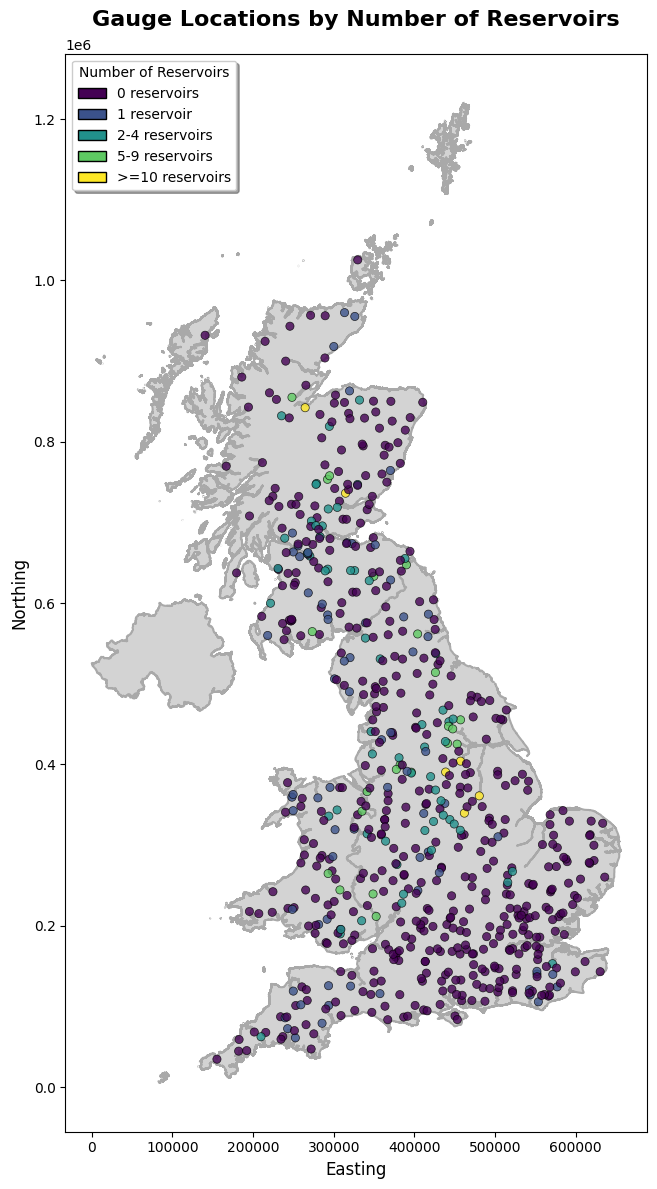

In [7]:

# Load the UK country boundary shapefile
uk_boundary = gpd.read_file(
    "/home/mokr/Camels_GB/GB_Shape_Files/CTRY_DEC_2024_UK_BFC.shp"
)

# Create gauge GeoDataFrame
gdf_gauges = gpd.GeoDataFrame(
    All_Static_Variables,
    geometry=gpd.points_from_xy(
        All_Static_Variables["gauge_lon"], All_Static_Variables["gauge_lat"]
    ),
    crs="EPSG:4326",
)

# Reproject gauges to match shapefile CRS
if uk_boundary.crs != gdf_gauges.crs:
    gdf_gauges = gdf_gauges.to_crs(uk_boundary.crs)


# Create discrete categories
def categorize_reservoirs(num):
    if num == 0:
        return "0"
    elif num == 1:
        return "1"
    elif 2 <= num <= 4:
        return "2-4"
    elif 5 <= num <= 9:
        return "5-9"
    else:
        return ">=10"


gdf_gauges["reservoir_category"] = gdf_gauges["num_reservoir"].apply(
    categorize_reservoirs
)

# Define colors for each category
category_colors = {
    "0": "#440154",  # Dark purple
    "1": "#3b528b",  # Blue
    "2-4": "#21918c",  # Teal
    "5-9": "#5ec962",  # Green
    ">=10": "#fde725",  # Yellow
}

# Map colors to the dataframe
gdf_gauges["color"] = gdf_gauges["reservoir_category"].map(category_colors)

# Create the map
fig, ax = plt.subplots(figsize=(12, 14))

# Plot UK boundary
uk_boundary.plot(ax=ax, color="lightgray", edgecolor="darkgray", linewidth=1.5)

# Plot gauges with discrete colors
gdf_gauges.plot(
    ax=ax,
    color=gdf_gauges["color"],
    markersize=35,
    alpha=0.8,
    edgecolor="black",
    linewidth=0.5,
)

# Create custom legend
legend_elements = [
    Patch(facecolor=category_colors["0"], edgecolor="black", label="0 reservoirs"),
    Patch(facecolor=category_colors["1"], edgecolor="black", label="1 reservoir"),
    Patch(facecolor=category_colors["2-4"], edgecolor="black", label="2-4 reservoirs"),
    Patch(facecolor=category_colors["5-9"], edgecolor="black", label="5-9 reservoirs"),
    Patch(
        facecolor=category_colors[">=10"], edgecolor="black", label=">=10 reservoirs"
    ),
]
ax.legend(
    handles=legend_elements,
    loc="upper left",
    title="Number of Reservoirs",
    frameon=True,
    fancybox=True,
    shadow=True,
)

# Customize the plot
ax.set_title(
    "Gauge Locations by Number of Reservoirs", fontsize=16, fontweight="bold", pad=20
)
ax.set_xlabel("Easting", fontsize=12)
ax.set_ylabel("Northing", fontsize=12)
ax.set_aspect("equal")

# plt.tight_layout()
# plt.show()

# Print summary statistics
print(f"\nValue counts by category:")
print(gdf_gauges["reservoir_category"].value_counts().sort_index())

# Optional: Print what countries are in the shapefile
print(f"\nCountries in shapefile:")
if "CTRY24NM" in uk_boundary.columns:
    print(uk_boundary["CTRY24NM"].tolist())
elif "NAME" in uk_boundary.columns:
    print(uk_boundary["NAME"].tolist())


Value counts by category:
area_category
0         518
0-10       76
10-25      44
25-75      24
75-100      9
Name: count, dtype: int64


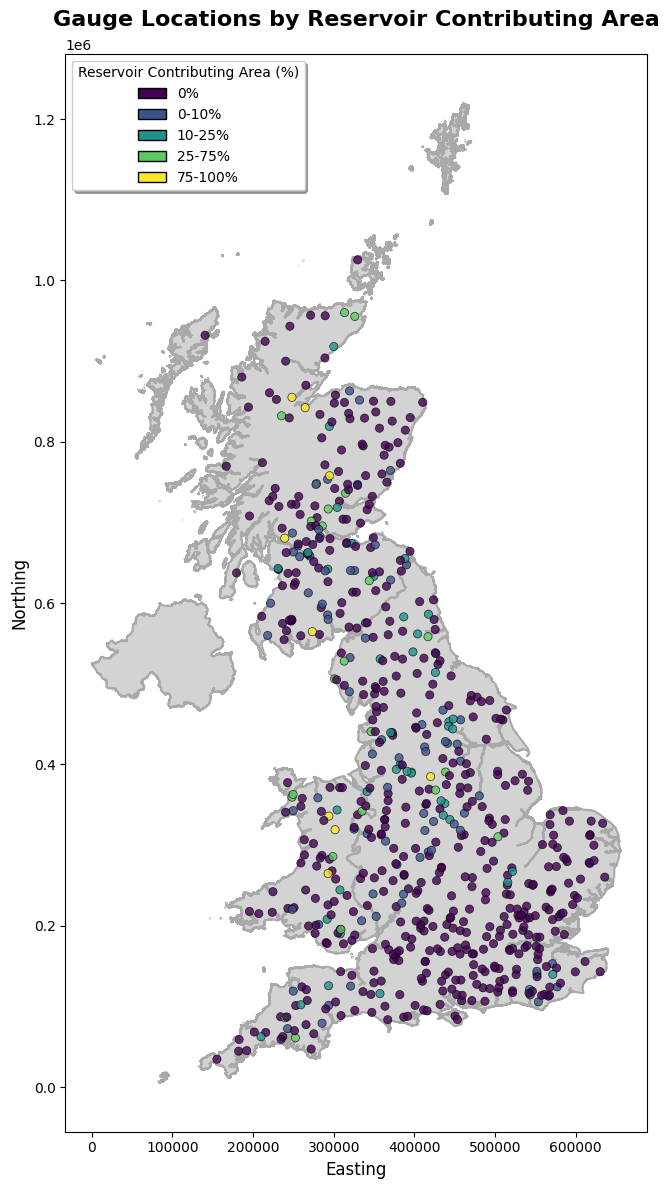

In [8]:
# Create gauge GeoDataFrame using Camels2_Human
gdf_gauges = gpd.GeoDataFrame(
    All_Static_Variables,
    geometry=gpd.points_from_xy(
        All_Static_Variables["gauge_lon"], All_Static_Variables["gauge_lat"]
    ),
    crs="EPSG:4326",
)

# Reproject gauges to match shapefile CRS
if uk_boundary.crs != gdf_gauges.crs:
    gdf_gauges = gdf_gauges.to_crs(uk_boundary.crs)


# Create discrete categories for reservoir_contributing_area
def categorize_reservoir_area(value):
    if value == 0:
        return "0"
    elif 0 < value <= 10:
        return "0-10"
    elif 10 < value <= 25:
        return "10-25"
    elif 25 < value <= 75:
        return "25-75"
    else:
        return "75-100"


gdf_gauges["area_category"] = gdf_gauges["reservoir_contributing_area"].apply(
    categorize_reservoir_area
)

# Define colors for each category
category_colors = {
    "0": "#440154",  # Dark purple
    "0-10": "#3b528b",  # Blue
    "10-25": "#21918c",  # Teal
    "25-75": "#5ec962",  # Green
    "75-100": "#fde725",  # Yellow
}

# Map colors to the dataframe
gdf_gauges["color"] = gdf_gauges["area_category"].map(category_colors)

# Create the map
fig, ax = plt.subplots(figsize=(12, 14))

# Plot UK boundary
uk_boundary.plot(ax=ax, color="lightgray", edgecolor="darkgray", linewidth=1.5)

# Plot gauges with discrete colors
gdf_gauges.plot(
    ax=ax,
    color=gdf_gauges["color"],
    markersize=35,
    alpha=0.8,
    edgecolor="black",
    linewidth=0.5,
)

# Create custom legend
legend_elements = [
    Patch(facecolor=category_colors["0"], edgecolor="black", label="0%"),
    Patch(facecolor=category_colors["0-10"], edgecolor="black", label="0-10%"),
    Patch(facecolor=category_colors["10-25"], edgecolor="black", label="10-25%"),
    Patch(facecolor=category_colors["25-75"], edgecolor="black", label="25-75%"),
    Patch(facecolor=category_colors["75-100"], edgecolor="black", label="75-100%"),
]
ax.legend(
    handles=legend_elements,
    loc="upper left",
    title="Reservoir Contributing Area (%)",
    frameon=True,
    fancybox=True,
    shadow=True,
)

# Customize the plot
ax.set_title(
    "Gauge Locations by Reservoir Contributing Area",
    fontsize=16,
    fontweight="bold",
    pad=20,
)
ax.set_xlabel("Easting", fontsize=12)
ax.set_ylabel("Northing", fontsize=12)
ax.set_aspect("equal")

# plt.tight_layout()
# plt.show()


print(f"\nValue counts by category:")
print(gdf_gauges["area_category"].value_counts().sort_index())

In [9]:
# Filter rows where reservoir_contributing_area > 0
reservoir_gauges = All_Static_Variables[
    All_Static_Variables["reservoir_contributing_area"] > 0
].copy()

# Select the specified columns
columns_to_keep = [
    "gauge_id",
    "gauge_lat",
    "gauge_lon",
    "reservoir_contributing_area",
    "reservoir_year_last",
    "daily_flow_period_start",
    "daily_flow_period_end",
    "daily_flow_perc_complete",
    "daily_flow_period_end",
]

# Create the new table
reservoir_table = reservoir_gauges[columns_to_keep]

# Sort by reservoir_contributing_area (descending) to see highest influence first
reservoir_table = reservoir_table.sort_values(
    "reservoir_contributing_area", ascending=False
)

# Reset index for cleaner display
reservoir_table = reservoir_table.reset_index(drop=True)

# Show distribution by reservoir_contributing_area ranges
print(f"\nDistribution by reservoir contribution:")
print(
    f"0-10%: {len(reservoir_table[reservoir_table['reservoir_contributing_area'] <= 10])}"
)
print(
    f"10-25%: {len(reservoir_table[(reservoir_table['reservoir_contributing_area'] > 10) & (reservoir_table['reservoir_contributing_area'] <= 25)])}"
)
print(
    f"25-75%: {len(reservoir_table[(reservoir_table['reservoir_contributing_area'] > 25) & (reservoir_table['reservoir_contributing_area'] <= 75)])}"
)
print(
    f"75-100%: {len(reservoir_table[reservoir_table['reservoir_contributing_area'] > 75])}"
)


Distribution by reservoir contribution:
0-10%: 76
10-25%: 44
25-75%: 24
75-100%: 9


In [10]:
reservoir_table

latest_reservoir_idx = reservoir_table["reservoir_year_last"].idxmax()
latest_reservoir_row = reservoir_table.loc[latest_reservoir_idx]
latest_reservoir_row

earliest_flow_end_idx = reservoir_table["daily_flow_period_end"].idxmin()
earliest_flow_end_row = reservoir_table.loc[earliest_flow_end_idx]
earliest_flow_end_row

,gauge_id,gauge_lat,gauge_lon,reservoir_contributing_area,reservoir_year_last,daily_flow_period_start,daily_flow_period_end,daily_flow_perc_complete,daily_flow_period_end
58,67033.0,53.19,-2.88,14.04,1979.0,1994-01-06,2013-03-13,36.89,2013-03-13
58,67033.0,53.19,-2.88,14.04,1979.0,1994-01-06,2013-03-13,36.89,2013-03-13


In [11]:
All_Static_Variables
numeric_cols = All_Static_Variables.select_dtypes(include=[np.number]).columns.tolist()

# Normalising Static Data

In [10]:

# Make a copy to avoid modifying original
All_Static_Variables_normalized = All_Static_Variables.copy()

# Define columns to exclude from normalization
exclude_cols = ["gauge_id", "gauge_name", "gauge_lat", "gauge_lon"]

# Get columns to normalize
numeric_cols = All_Static_Variables.select_dtypes(include=[np.number]).columns.tolist()
cols_to_normalize = [col for col in numeric_cols if col not in exclude_cols]

print(f"Total columns: {len(All_Static_Variables.columns)}")
print(f"Columns to normalize: {len(cols_to_normalize)}")
print(f"Excluded columns: {exclude_cols}")

# OPTION 1: StandardScaler (Z-score normalization: mean=0, std=1)
# Best for most ML models, handles outliers reasonably
scaler = StandardScaler()
All_Static_Variables_normalized[cols_to_normalize] = scaler.fit_transform(
    All_Static_Variables[cols_to_normalize]
)

print("\n" + "=" * 60)
print("Normalization complete using StandardScaler")
print("=" * 60)

# Show before/after statistics for a few columns
sample_cols = cols_to_normalize[:3]  # First 3 normalized columns
print(f"\nBefore normalization (first 3 numeric columns):")
print(All_Static_Variables[sample_cols].describe())

print(f"\nAfter normalization (first 3 numeric columns):")
print(All_Static_Variables_normalized[sample_cols].describe())

# Check for any NaN values introduced
nan_counts = All_Static_Variables_normalized[cols_to_normalize].isna().sum()
if nan_counts.sum() > 0:
    print(f"\nWarning: NaN values found in normalized data:")
    print(nan_counts[nan_counts > 0])
else:
    print(f"\nNo NaN values introduced during normalization ✓")


Total columns: 229
Columns to normalize: 208
Excluded columns: ['gauge_id', 'gauge_name', 'gauge_lat', 'gauge_lon']

Normalization complete using StandardScaler

Before normalization (first 3 numeric columns):
       inter_high_perc  inter_mod_perc  inter_low_perc
count       671.000000      671.000000      671.000000
mean          2.229329       19.724545        0.530835
std           8.706633       14.756241        2.535317
min           0.000000        0.000000        0.000000
25%           0.000000       10.055000        0.000000
50%           0.000000       16.160000        0.000000
75%           0.000000       25.140000        0.000000
max          94.300000       92.640000       35.110000

After normalization (first 3 numeric columns):
       inter_high_perc  inter_mod_perc  inter_low_perc
count     6.710000e+02    6.710000e+02    6.710000e+02
mean     -3.176793e-17   -1.058931e-16   -3.706259e-17
std       1.000746e+00    1.000746e+00    1.000746e+00
min      -2.562405e-01   -1

In [11]:
All_Static_Variables_normalized[numeric_cols].mean()

gauge_id             4.376840e+04
inter_high_perc     -3.176793e-17
inter_mod_perc      -1.058931e-16
inter_low_perc      -3.706259e-17
frac_high_perc      -8.471448e-17
                         ...     
shrub_perc_2022      0.000000e+00
crop_perc_2022       2.117862e-17
urban_perc_2022     -1.270717e-16
inwater_perc_2022    5.294655e-17
bares_perc_2022     -2.117862e-17
Length: 211, dtype: float64

# Pairing Reservoir and Non Reservoir Catchments

In [12]:

# Separate reservoir and non-reservoir catchments
reservoir_gauges = gdf_gauges[gdf_gauges["reservoir_contributing_area"] > 0].copy()
reservoir_gauges = reservoir_gauges.sort_values("gauge_lat").reset_index(drop=True)
non_reservoir_gauges = gdf_gauges[gdf_gauges["reservoir_contributing_area"] == 0].copy()
non_reservoir_gauges = non_reservoir_gauges[(non_reservoir_gauges['surfacewater_abs'] + non_reservoir_gauges['groundwater_abs']) < 0.2]
print(f"Reservoir catchments: {len(reservoir_gauges)}")
print(f"Non-reservoir catchments: {len(non_reservoir_gauges)}")

# Extract coordinates for distance calculation
reservoir_coords = np.column_stack(
    [reservoir_gauges.geometry.x, reservoir_gauges.geometry.y]
)
non_reservoir_coords = np.column_stack(
    [non_reservoir_gauges.geometry.x, non_reservoir_gauges.geometry.y]
)

# Create pairing lists
paired_reservoir_indices = []
paired_non_reservoir_indices = []
available_non_reservoir = set(range(len(non_reservoir_gauges)))

# For each reservoir gauge, find closest available non-reservoir gauge
for i in range(len(reservoir_gauges)):
    if not available_non_reservoir:
        print(f"Warning: Ran out of non-reservoir gauges at iteration {i}")
        break

    # Calculate distances to all available non-reservoir gauges
    res_coord = reservoir_coords[i : i + 1]
    available_indices = list(available_non_reservoir)
    available_coords = non_reservoir_coords[available_indices]

    distances = cdist(res_coord, available_coords, metric="euclidean")[0]

    # Find closest available gauge
    closest_idx_in_available = np.argmin(distances)
    closest_idx = available_indices[closest_idx_in_available]

    # Record pairing
    paired_reservoir_indices.append(i)
    paired_non_reservoir_indices.append(closest_idx)

    # Remove from available set
    available_non_reservoir.remove(closest_idx)

print(f"\nSuccessfully paired {len(paired_reservoir_indices)} catchments")

# Create paired dataframes
paired_reservoir = reservoir_gauges.iloc[paired_reservoir_indices].copy()
paired_non_reservoir = non_reservoir_gauges.iloc[paired_non_reservoir_indices].copy()
unpaired_non_reservoir = non_reservoir_gauges.iloc[list(available_non_reservoir)].copy()

# Add pairing information
paired_reservoir["pair_id"] = range(len(paired_reservoir_indices))
paired_non_reservoir["pair_id"] = range(len(paired_non_reservoir_indices))

Reservoir catchments: 153
Non-reservoir catchments: 471

Successfully paired 153 catchments


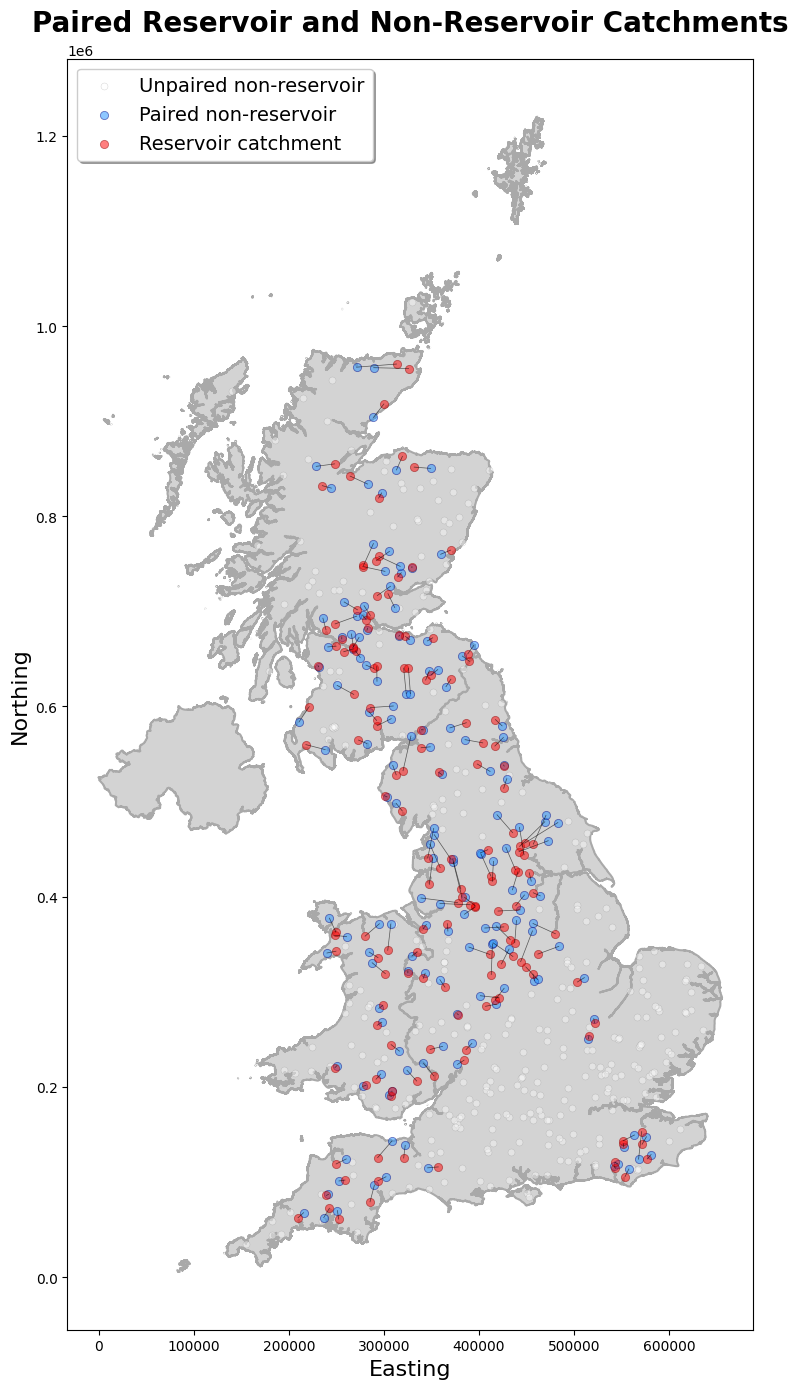


Pairing Statistics:
Paired reservoir catchments: 153
Paired non-reservoir catchments: 153
Unpaired non-reservoir catchments: 318

Pairing distance statistics (in CRS units):
Mean distance: 15174.81
Median distance: 12772.20
Min distance: 691.95
Max distance: 42206.59

First 5 pairs:
   reservoir_gauge_id  reservoir_lat  reservoir_lon  \
0             48011.0          50.43          -4.68   
1             47011.0          50.43          -4.08   
2             47001.0          50.53          -4.22   
3             46014.0          50.60          -3.62   
4             47008.0          50.65          -4.27   

   reservoir_contributing_area reservoir_gauge_name  non_reservoir_gauge_id  \
0                        12.02   Fowey at Restormel                 48004.0   
1                        27.17    Plym at Carn Wood                 47014.0   
2                         3.27  Tamar at Gunnislake                 47004.0   
3                         3.96   Teign at Chudleigh                 

In [13]:
# Create map
fig, ax = plt.subplots(figsize=(12, 14))

# Plot UK boundary
uk_boundary.plot(ax=ax, color="lightgray", edgecolor="darkgray", linewidth=1.5)

# Plot unpaired (grey)
unpaired_non_reservoir.plot(
    ax=ax,
    color="white",
    markersize=25,
    alpha=0.4,
    edgecolor="grey",
    linewidth=0.3,
    label="Unpaired non-reservoir",
)

# Plot paired non-reservoir (blue)
paired_non_reservoir.plot(
    ax=ax,
    color="dodgerblue",
    markersize=35,
    alpha=0.5,
    edgecolor="navy",
    linewidth=0.6,
    label="Paired non-reservoir",
)

# Plot paired reservoir (red)
paired_reservoir.plot(
    ax=ax,
    color="red",
    markersize=35,
    alpha=0.5,
    edgecolor="darkred",
    linewidth=0.6,
    label="Reservoir catchment",
)

# Draw lines connecting pairs
for res_idx, non_res_idx in zip(paired_reservoir_indices, paired_non_reservoir_indices):
    res_point = reservoir_coords[res_idx]
    non_res_point = non_reservoir_coords[non_res_idx]
    ax.plot(
        [res_point[0], non_res_point[0]],
        [res_point[1], non_res_point[1]],
        color="black",
        alpha=0.6,
        linewidth=0.5,
        zorder=1,
    )

# Customize plot
ax.legend(loc="upper left", frameon=True, fancybox=True, shadow=True, fontsize=14)
ax.set_title(
    "Paired Reservoir and Non-Reservoir Catchments",
    fontsize=20,
    fontweight="bold",
    pad=20,
)
ax.set_xlabel("Easting", fontsize=16)
ax.set_ylabel("Northing", fontsize=16)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

# Print pairing statistics
print(f"\nPairing Statistics:")
print(f"Paired reservoir catchments: {len(paired_reservoir)}")
print(f"Paired non-reservoir catchments: {len(paired_non_reservoir)}")
print(f"Unpaired non-reservoir catchments: {len(unpaired_non_reservoir)}")

# Calculate and display pairing distances
distances = []
for res_idx, non_res_idx in zip(paired_reservoir_indices, paired_non_reservoir_indices):
    dist = np.linalg.norm(reservoir_coords[res_idx] - non_reservoir_coords[non_res_idx])
    distances.append(dist)

distances = np.array(distances)
print(f"\nPairing distance statistics (in CRS units):")
print(f"Mean distance: {distances.mean():.2f}")
print(f"Median distance: {np.median(distances):.2f}")
print(f"Min distance: {distances.min():.2f}")
print(f"Max distance: {distances.max():.2f}")

# Create output dataframe with pairs
pairs_df = paired_reservoir.reset_index()[
    ["gauge_id", "gauge_lat", "gauge_lon", "reservoir_contributing_area", "gauge_name"]
].copy()
pairs_df.columns = [
    "reservoir_gauge_id",
    "reservoir_lat",
    "reservoir_lon",
    "reservoir_contributing_area",
    "reservoir_gauge_name",
]
pairs_df["non_reservoir_gauge_id"] = paired_non_reservoir.reset_index()[
    "gauge_id"
].values
pairs_df["non_reservoir_lat"] = paired_non_reservoir.reset_index()["gauge_lat"].values
pairs_df["non_reservoir_lon"] = paired_non_reservoir.reset_index()["gauge_lon"].values
pairs_df["non_reservoir_distance"] = distances
pairs_df["non_reservoir_gauge_name"] = paired_non_reservoir.reset_index()[
    "gauge_name"
].values


print("\nFirst 5 pairs:")
print(pairs_df.head())

# Choosing Training, Validation, Test

In [14]:
pairs_df = create_geographic_split(pairs_df, train_ratio=0.7, val_ratio=0.15, test_ratio=0.15)

In [15]:
# Calculate distance for each pair
pairs_df["calculated_distance_km"] = pairs_df.apply(
    lambda row: haversine_distance(
        row["reservoir_lat"],
        row["reservoir_lon"],
        row["non_reservoir_lat"],
        row["non_reservoir_lon"],
    ),
    axis=1,
)

# Calculate statistics
avg_distance = pairs_df["calculated_distance_km"].mean()
median_distance = pairs_df["calculated_distance_km"].median()
std_distance = pairs_df["calculated_distance_km"].std()
min_distance = pairs_df["calculated_distance_km"].min()
max_distance = pairs_df["calculated_distance_km"].max()

print("=" * 80)
print("GAUGE PAIR DISTANCE STATISTICS")
print("=" * 80)
print(f"\nTotal number of pairs: {len(pairs_df)}")
print(f"\nAverage distance: {avg_distance:.2f} km")
print(f"Median distance: {median_distance:.2f} km")
print(f"Standard deviation: {std_distance:.2f} km")
print(f"Minimum distance: {min_distance:.2f} km")
print(f"Maximum distance: {max_distance:.2f} km")

# Check if there's already a 'non_reservoir_distance' column and compare
if "non_reservoir_distance" in pairs_df.columns:
    print("\n" + "=" * 80)
    print("COMPARISON WITH EXISTING 'non_reservoir_distance' COLUMN")
    print("=" * 80)

    # Check if the existing column might be in different units
    existing_avg = pairs_df["non_reservoir_distance"].mean()
    print(f"\nExisting column average: {existing_avg:.2f}")
    print(f"Calculated average: {avg_distance:.2f} km")

    # Check correlation
    correlation = pairs_df["calculated_distance_km"].corr(
        pairs_df["non_reservoir_distance"]
    )
    print(f"Correlation: {correlation:.4f}")

    # If highly correlated but different scale, check if it might be in miles or meters
    ratio = existing_avg / avg_distance
    if abs(ratio - 1.60934) < 0.01:
        print("\n→ Existing column appears to be in MILES")
    elif abs(ratio - 1000) < 10:
        print("\n→ Existing column appears to be in METERS")
    elif abs(ratio - 1) < 0.01:
        print(
            "\n→ Existing column appears to be in KILOMETERS (matches our calculation)"
        )

# Distribution by split
if "split" in pairs_df.columns:
    print("\n" + "=" * 80)
    print("DISTANCE STATISTICS BY SPLIT")
    print("=" * 80)
    for split in pairs_df["split"].unique():
        split_data = pairs_df[pairs_df["split"] == split]["calculated_distance_km"]
        print(f"\n{split}:")
        print(f"  Count: {len(split_data)}")
        print(f"  Average: {split_data.mean():.2f} km")
        print(f"  Median: {split_data.median():.2f} km")
        print(f"  Std: {split_data.std():.2f} km")

# Show a few examples
print("\n" + "=" * 80)
print("SAMPLE PAIRS (showing 5 closest and 5 farthest)")
print("=" * 80)

print("\nCLOSEST PAIRS:")
closest = pairs_df.nsmallest(5, "calculated_distance_km")[
    ["reservoir_gauge_name", "non_reservoir_gauge_name", "calculated_distance_km"]
]
for idx, row in closest.iterrows():
    print(
        f"  {row['reservoir_gauge_name']} <-> {row['non_reservoir_gauge_name']}: {row['calculated_distance_km']:.2f} km"
    )

print("\nFARTHEST PAIRS:")
farthest = pairs_df.nlargest(5, "calculated_distance_km")[
    ["reservoir_gauge_name", "non_reservoir_gauge_name", "calculated_distance_km"]
]
for idx, row in farthest.iterrows():
    print(
        f"  {row['reservoir_gauge_name']} <-> {row['non_reservoir_gauge_name']}: {row['calculated_distance_km']:.2f} km"
    )

GAUGE PAIR DISTANCE STATISTICS

Total number of pairs: 153

Average distance: 15.15 km
Median distance: 12.75 km
Standard deviation: 9.87 km
Minimum distance: 0.69 km
Maximum distance: 42.07 km

COMPARISON WITH EXISTING 'non_reservoir_distance' COLUMN

Existing column average: 15174.81
Calculated average: 15.15 km
Correlation: 1.0000

→ Existing column appears to be in METERS

DISTANCE STATISTICS BY SPLIT

train:
  Count: 106
  Average: 15.93 km
  Median: 14.03 km
  Std: 9.76 km

test:
  Count: 26
  Average: 14.55 km
  Median: 12.18 km
  Std: 10.84 km

val:
  Count: 21
  Average: 11.92 km
  Median: 10.13 km
  Std: 8.87 km

SAMPLE PAIRS (showing 5 closest and 5 farthest)

CLOSEST PAIRS:
  Taff at Fiddlers Elbow <-> Cynon at Abercynon: 0.69 km
  Isla at Wester Cardean <-> Dean Water at Dean Bridge: 1.11 km
  Almond at Craigiehall <-> Gogar Burn at Turnhouse: 1.27 km
  Garnock at Kilwinning <-> Lugton Water at Eglinton Castle: 1.28 km
  Wear at Sunderland Bridge <-> Browney at Burnhall: 1

In [16]:
# Prepare data - create separate GeoDataFrames for reservoir and non-reservoir gauges
# Reservoir gauges
res_geometry = [
    Point(lon, lat)
    for lon, lat in zip(pairs_df["reservoir_lon"], pairs_df["reservoir_lat"])
]
res_gdf = gpd.GeoDataFrame(
    pairs_df[["reservoir_gauge_id", "reservoir_gauge_name", "split"]].copy(),
    geometry=res_geometry,
    crs="EPSG:4326",
)
res_gdf["type"] = "reservoir"
res_gdf = res_gdf.rename(
    columns={"reservoir_gauge_id": "gauge_id", "reservoir_gauge_name": "gauge_name"}
)

# Non-reservoir gauges
nonres_geometry = [
    Point(lon, lat)
    for lon, lat in zip(pairs_df["non_reservoir_lon"], pairs_df["non_reservoir_lat"])
]
nonres_gdf = gpd.GeoDataFrame(
    pairs_df[["non_reservoir_gauge_id", "non_reservoir_gauge_name", "split"]].copy(),
    geometry=nonres_geometry,
    crs="EPSG:4326",
)
nonres_gdf["type"] = "non_reservoir"
nonres_gdf = nonres_gdf.rename(
    columns={
        "non_reservoir_gauge_id": "gauge_id",
        "non_reservoir_gauge_name": "gauge_name",
    }
)

# Convert to same CRS as uk_boundary
res_gdf = res_gdf.to_crs(uk_boundary.crs)
nonres_gdf = nonres_gdf.to_crs(uk_boundary.crs)

In [17]:
uk_boundary.keys()

Index(['CTRY24CD', 'CTRY24NM', 'CTRY24NMW', 'BNG_E', 'BNG_N', 'LONG', 'LAT',
       'GlobalID', 'geometry'],
      dtype='object')

In [18]:
with open(
    "/home/mokr/Reservoir_Modelling/Sample_Pairs/catchment_date_pairs.pkl", "rb"
) as f:
    catchment_pairings = pickle.load(f)

In [19]:
def create_catchment_splits(catchment_pairings, pairs_gdf):
    """
    Create split dictionaries matching the catchment_pairings structure
    """
    # Create mapping from gauge_id to split
    pairs_gdf["reservoir_gauge_id"] = (
        pairs_gdf["reservoir_gauge_id"].astype(int).astype(str)
    )
    pairs_gdf["non_reservoir_gauge_id"] = (
        pairs_gdf["non_reservoir_gauge_id"].astype(int).astype(str)
    )

    reservoir_split_map = dict(zip(pairs_gdf["reservoir_gauge_id"], pairs_gdf["split"]))
    non_reservoir_split_map = dict(
        zip(pairs_gdf["non_reservoir_gauge_id"], pairs_gdf["split"])
    )

    catchment_splits = {
        "reservoir_train": [],
        "reservoir_val": [],
        "reservoir_test": [],
        "non_reservoir_train": [],
        "non_reservoir_val": [],
        "non_reservoir_test": [],
    }

    # Process paired reservoir entries
    for entry in catchment_pairings["paired_reservoir"]:
        gauge_id = str(entry["gauge_id"])

        split = reservoir_split_map.get(gauge_id)

        if split:
            catchment_splits[f"reservoir_{split}"].append(entry)

    # Process paired non-reservoir entries
    for entry in catchment_pairings["paired_non_reservoir"]:
        gauge_id = str(entry["gauge_id"])
        split = non_reservoir_split_map.get(gauge_id)
        if split:
            catchment_splits[f"non_reservoir_{split}"].append(entry)

    # Print statistics
    for key in catchment_splits.keys():
        print(f"{key}: {len(catchment_splits[key])} entries")

    return catchment_splits


# Create the splits
catchment_splits = create_catchment_splits(catchment_pairings, pairs_df)

# Save to file
# output_path = (
#     "/home/mokr/Reservoir_Modelling/Sample_Pairs/catchment_date_pairs_splits.pkl"
# )
# with open(output_path, "wb") as f:
#     pickle.dump(catchment_splits, f)
# print(f"\nSaved to {output_path}")

# # Verify the structure
# print(f"\nExample entry from reservoir_train:")
# print(catchment_splits["reservoir_train"][0])

reservoir_train: 959493 entries
reservoir_val: 167255 entries
reservoir_test: 214977 entries
non_reservoir_train: 922758 entries
non_reservoir_val: 145883 entries
non_reservoir_test: 205762 entries


# Get Data Range

In [112]:
with open("/home/mokr/Reservoir_Modelling/Normalised_Temporal_Data.pkl", "rb") as f:
    temporal_data = pickle.load(f)


paired_reservoir
paired_non_reservoir
unpaired_non_reservoir

,gauge_id,inter_high_perc,inter_mod_perc,inter_low_perc,frac_high_perc,frac_mod_perc,frac_low_perc,no_gw_perc,low_nsig_perc,nsig_low_perc,...,ewood_perc_2022,grass_perc_2022,shrub_perc_2022,crop_perc_2022,urban_perc_2022,inwater_perc_2022,bares_perc_2022,geometry,area_category,color
3,3003.0,0.00,5.75,0.00,0.00,0.21,12.17,81.88,0.0,0.0,...,12.30,23.69,59.85,0.32,0.00,1.50,0.90,POINT (240347.766 899939.164),0,#440154
5,4003.0,0.00,5.59,0.00,0.00,3.60,7.90,82.91,0.0,0.0,...,15.62,8.81,69.21,1.54,0.16,1.63,0.03,POINT (265407.992 870046.238),0,#440154
7,4006.0,0.00,7.92,0.00,0.00,0.00,10.78,81.29,0.0,0.0,...,2.28,35.91,57.94,0.06,0.03,3.13,0.31,POINT (220230.527 860658.533),0,#440154
12,7002.0,0.00,19.28,0.00,0.00,0.00,4.63,76.09,0.0,0.0,...,9.71,11.56,74.03,0.54,0.12,0.72,0.21,POINT (302084.198 857851.644),0,#440154
14,7005.0,0.00,18.11,0.00,0.00,0.00,4.37,77.52,0.0,0.0,...,10.15,11.25,74.89,0.28,0.05,1.73,0.00,POINT (300643.989 847862.922),0,#440154
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
664,96004.0,0.00,2.44,0.00,0.00,0.00,30.33,67.23,0.0,0.0,...,1.73,36.41,56.46,0.00,0.00,1.01,4.28,POINT (245597.282 943200.417),0,#440154
666,101002.0,45.27,31.08,0.08,4.28,0.00,0.00,19.29,0.0,0.0,...,0.24,46.36,0.00,41.72,4.14,0.47,0.28,POINT (450248.528 88058.134),0,#440154
667,101005.0,28.84,43.99,0.00,8.92,0.00,0.00,18.25,0.0,0.0,...,0.00,64.22,0.00,27.41,4.50,0.10,0.00,POINT (453119.017 83638.048),0,#440154
669,106001.0,0.00,0.00,0.00,0.00,0.00,4.65,95.35,0.0,0.0,...,1.39,0.96,91.11,0.00,0.00,5.86,0.00,POINT (140402.516 931990.27),0,#440154


In [113]:
def get_actual_data_range(gauge_id, temporal_data):
    """Get the actual start and end dates from the timeseries data"""
    if gauge_id not in temporal_data:
        print("Gauge not in dataset")
        return None, None

    df = temporal_data[gauge_id]
    if df is None or len(df) == 0:
        print("Gauge data empty")
        return None, None

    dates = pd.to_datetime(df["date"])
    return dates.min(), dates.max()


def check_for_nans_in_range(df, start_date, end_date):
    """Check if there are any NaNs in the specified date range, and adjust bounds if needed"""
    if df is None or len(df) == 0:
        return None, None

    dates = pd.to_datetime(df["date"])
    df_range = df[(dates >= start_date) & (dates <= end_date)]

    if len(df_range) == 0:
        return None, None

    # Check if there are any NaNs
    if df_range.isna().any().any():
        print(f"There are nans for this catchment")
        # There are NaNs, so filter to complete rows only
        complete_rows = df_range.dropna()
        if len(complete_rows) == 0:
            return None, None

        dates = pd.to_datetime(complete_rows["date"])
        return dates.min(), dates.max()
    else:
        # No NaNs in this range, return original bounds
        return start_date, end_date


def find_longest_consecutive_period(df, start_date, end_date):
    """Find the longest consecutive period without NaNs in the specified date range"""
    if df is None or len(df) == 0:
        return None, None

    dates = pd.to_datetime(df["date"])
    df_range = df[(dates >= start_date) & (dates <= end_date)].copy()
    df_range["date_col"] = dates[(dates >= start_date) & (dates <= end_date)]

    if len(df_range) == 0:
        return None, None

    # Check if there are any NaNs
    if not df_range.isna().any().any():
        # No NaNs in this range, return original bounds
        return start_date, end_date

    # Find rows with complete data (no NaNs)
    has_complete_data = ~df_range.drop(columns=["date_col"]).isna().any(axis=1)

    if not has_complete_data.any():
        return None, None

    # Find consecutive groups of complete data
    # Create group IDs where each consecutive run gets the same ID
    df_range["complete"] = has_complete_data
    df_range["group"] = (df_range["complete"] != df_range["complete"].shift()).cumsum()

    # Filter to only complete data groups
    complete_groups = df_range[df_range["complete"]].groupby("group")

    # Find the longest group
    longest_group = None
    longest_duration = pd.Timedelta(0)

    for group_id, group_df in complete_groups:
        group_start = group_df["date_col"].min()
        group_end = group_df["date_col"].max()
        duration = group_end - group_start

        if duration > longest_duration:
            longest_duration = duration
            longest_group = (group_start, group_end)

    if longest_group is None:
        return None, None

    return longest_group[0], longest_group[1]


def determine_valid_period(gauge_row, temporal_data, is_reservoir=False):
    """Determine valid start and end dates for a gauge"""
    gauge_id = int(gauge_row["gauge_id"])

    # Get actual data range
    valid_start, valid_end = get_actual_data_range(f"{gauge_id}", temporal_data)

    if valid_start is None or valid_end is None:
        return None, None

    # Start with flow period bounds
    flow_start = pd.to_datetime(gauge_row["daily_flow_period_start"])
    flow_end = pd.to_datetime(gauge_row["daily_flow_period_end"])

    # For reservoirs, also consider reservoir_year_last
    if is_reservoir and pd.notna(gauge_row.get("reservoir_year_last")):
        reservoir_year = int(gauge_row["reservoir_year_last"])
        # Start from January 1st of the year after last reservoir
        reservoir_date = pd.Timestamp(year=reservoir_year + 1, month=1, day=1)
        valid_start = max(valid_start, reservoir_date)

    # Valid end is the earliest of: actual data end, flow period end
    valid_end = flow_end

    # Check if valid range exists
    if valid_start >= valid_end:
        return None, None

    # final_start, final_end = check_for_nans_in_range(temporal_data[f'{gauge_id}'], valid_start, valid_end)
    final_start, final_end = find_longest_consecutive_period(
        temporal_data[f"{gauge_id}"], valid_start, valid_end
    )

    return final_start, final_end

In [114]:
# Process paired reservoir gauges
print("\n" + "=" * 60)
print("Processing paired reservoir gauges...")
print("=" * 60)

paired_reservoir["valid_start"] = None
paired_reservoir["valid_end"] = None

for idx, row in paired_reservoir.iterrows():
    start, end = determine_valid_period(row, temporal_data, is_reservoir=True)
    paired_reservoir.at[idx, "valid_start"] = start
    paired_reservoir.at[idx, "valid_end"] = end


# Process paired non-reservoir gauges
print("\nProcessing paired non-reservoir gauges...")

paired_non_reservoir["valid_start"] = None
paired_non_reservoir["valid_end"] = None

for idx, row in paired_non_reservoir.iterrows():
    start, end = determine_valid_period(row, temporal_data, is_reservoir=False)
    paired_non_reservoir.at[idx, "valid_start"] = start
    paired_non_reservoir.at[idx, "valid_end"] = end

# Align dates for paired gauges
print("\nAligning dates for paired gauges...")

paired_reservoir["pair_start"] = None
paired_reservoir["pair_end"] = None
paired_non_reservoir["pair_start"] = None
paired_non_reservoir["pair_end"] = None

for pair_id in range(len(paired_reservoir)):
    res_row = paired_reservoir[paired_reservoir["pair_id"] == pair_id].iloc[0]
    non_res_row = paired_non_reservoir[paired_non_reservoir["pair_id"] == pair_id].iloc[
        0
    ]

    # Get valid periods for both
    res_start = res_row["valid_start"]
    res_end = res_row["valid_end"]
    non_res_start = non_res_row["valid_start"]
    non_res_end = non_res_row["valid_end"]

    # Find overlap (latest start, earliest end)
    pair_start = max(res_start, non_res_start)
    pair_end = min(res_end, non_res_end)

    # Check if valid overlap exists
    if pair_start < pair_end:
        paired_reservoir.loc[paired_reservoir["pair_id"] == pair_id, "pair_start"] = (
            pair_start
        )
        paired_reservoir.loc[paired_reservoir["pair_id"] == pair_id, "pair_end"] = (
            pair_end
        )
        paired_non_reservoir.loc[
            paired_non_reservoir["pair_id"] == pair_id, "pair_start"
        ] = pair_start
        paired_non_reservoir.loc[
            paired_non_reservoir["pair_id"] == pair_id, "pair_end"
        ] = pair_end
    else:
        print(f"Warning: No valid overlap for pair {pair_id}")

# Process unpaired non-reservoir gauges
print("\nProcessing unpaired non-reservoir gauges...")

unpaired_non_reservoir["valid_start"] = None
unpaired_non_reservoir["valid_end"] = None

for idx, row in unpaired_non_reservoir.iterrows():
    start, end = determine_valid_period(row, temporal_data, is_reservoir=False)
    unpaired_non_reservoir.at[idx, "valid_start"] = start
    unpaired_non_reservoir.at[idx, "valid_end"] = end


Processing paired reservoir gauges...

Processing paired non-reservoir gauges...

Aligning dates for paired gauges...

Processing unpaired non-reservoir gauges...


In [115]:
# Summary statistics
print("\n" + "=" * 60)
print("SUMMARY STATISTICS")
print("=" * 60)

# Paired gauges
valid_pairs = paired_reservoir[paired_reservoir["pair_start"].notna()]
print(
    f"\nPaired gauges with valid overlapping data: {len(valid_pairs)} out of {len(paired_reservoir)}"
)

if len(valid_pairs) > 0:
    paired_reservoir["pair_duration_days"] = (
        paired_reservoir["pair_end"] - paired_reservoir["pair_start"]
    ).apply(lambda x: x.days if pd.notna(x) else None)
    paired_reservoir["pair_duration_years"] = (
        paired_reservoir["pair_duration_days"] / 365.25
    )

    # Filter out None/NaN values for statistics
    valid_durations = paired_reservoir["pair_duration_years"].dropna()
    valid_starts = paired_reservoir["pair_start"].dropna()
    valid_ends = paired_reservoir["pair_end"].dropna()

    print(f"Mean overlap duration: {valid_durations.mean():.1f} years")
    print(f"Median overlap duration: {valid_durations.median():.1f} years")
    print(f"Min overlap duration: {valid_durations.min():.1f} years")
    print(f"Max overlap duration: {valid_durations.max():.1f} years")

    if len(valid_starts) > 0 and len(valid_ends) > 0:
        print(f"\nEarliest pair start: {valid_starts.min()}")
        print(f"Latest pair end: {valid_ends.max()}")

# Unpaired gauges
valid_unpaired = unpaired_non_reservoir[unpaired_non_reservoir["valid_start"].notna()]
print(
    f"\nUnpaired gauges with valid data: {len(valid_unpaired)} out of {len(unpaired_non_reservoir)}"
)

if len(valid_unpaired) > 0:
    unpaired_non_reservoir["duration_days"] = (
        unpaired_non_reservoir["valid_end"] - unpaired_non_reservoir["valid_start"]
    ).apply(lambda x: x.days if pd.notna(x) else None)
    unpaired_non_reservoir["duration_years"] = (
        unpaired_non_reservoir["duration_days"] / 365.25
    )

    # Filter out None/NaN values for statistics
    valid_durations = unpaired_non_reservoir["duration_years"].dropna()

    print(f"Mean duration: {valid_durations.mean():.1f} years")
    print(f"Median duration: {valid_durations.median():.1f} years")

# Display sample pairs
print("\n" + "=" * 60)
print("SAMPLE PAIRED GAUGES (first 5 with valid data)")
print("=" * 60)

sample_pairs = paired_reservoir[paired_reservoir["pair_start"].notna()].head()
for _, res_row in sample_pairs.iterrows():
    pair_id = res_row["pair_id"]
    non_res_row = paired_non_reservoir[paired_non_reservoir["pair_id"] == pair_id].iloc[
        0
    ]

    print(f"\nPair {pair_id}:")
    print(
        f"  Reservoir: {res_row['gauge_id']} ({res_row['reservoir_contributing_area']:.1f}%)"
    )
    print(f"  Non-reservoir: {non_res_row['gauge_id']}")
    print(
        f"  Shared period: {res_row['pair_start'].date()} to {res_row['pair_end'].date()}"
    )
    duration = (res_row["pair_end"] - res_row["pair_start"]).days / 365.25
    print(f"  Duration: {duration:.1f} years")

print("\n" + "=" * 60)
print("Data processing complete!")
print("=" * 60)


SUMMARY STATISTICS

Paired gauges with valid overlapping data: 148 out of 153
Mean overlap duration: 24.8 years
Median overlap duration: 23.7 years
Min overlap duration: 2.9 years
Max overlap duration: 52.0 years

Earliest pair start: 1970-10-01 00:00:00
Latest pair end: 2022-09-30 00:00:00

Unpaired gauges with valid data: 318 out of 318
Mean duration: 32.5 years
Median duration: 30.6 years

SAMPLE PAIRED GAUGES (first 5 with valid data)

Pair 0:
  Reservoir: 48011.0 (12.0%)
  Non-reservoir: 48004.0
  Shared period: 1984-01-01 to 2022-09-30
  Duration: 38.7 years

Pair 1:
  Reservoir: 47011.0 (27.2%)
  Non-reservoir: 47014.0
  Shared period: 2000-04-17 to 2014-07-07
  Duration: 14.2 years

Pair 2:
  Reservoir: 47001.0 (3.3%)
  Non-reservoir: 47004.0
  Shared period: 1990-01-01 to 2022-09-30
  Duration: 32.7 years

Pair 4:
  Reservoir: 47008.0 (26.7%)
  Non-reservoir: 47018.0
  Shared period: 1990-01-01 to 2015-09-30
  Duration: 25.7 years

Pair 5:
  Reservoir: 45001.0 (4.8%)
  Non-re

In [116]:
chosen_catchments = {
    "paired_reservoir": paired_reservoir[["gauge_id", "pair_start", "pair_end"]],
    "paired_non_reservoir": paired_non_reservoir[
        ["gauge_id", "pair_start", "pair_end"]
    ],
    "unpaired_non_reservoir": unpaired_non_reservoir[
        ["gauge_id", "valid_start", "valid_end"]
    ],
}

# with open('/home/mokr/Reservoir_Modelling/chosen_catchments.pkl', 'wb') as f:
#     pickle.dump(chosen_catchments, f)

In [117]:
paired_reservoir_pairs[0]

NameError: name 'paired_reservoir_pairs' is not defined

In [ ]:
# Generate pairs for each catchment type
forecast_days = 90

print("Generating pairs for paired_reservoir catchments...")
paired_reservoir_pairs = generate_all_catchment_date_pairs(
    paired_reservoir[["gauge_id", "pair_id", "pair_start", "pair_end"]],
    forecast_days=forecast_days,
    catchment_type="paired_reservoir",
    pair_id_col="pair_id",
)

print("Generating pairs for paired_non_reservoir catchments...")
paired_non_reservoir_pairs = generate_all_catchment_date_pairs(
    paired_non_reservoir[["gauge_id", "pair_id", "pair_start", "pair_end"]],
    forecast_days=forecast_days,
    catchment_type="paired_non_reservoir",
    pair_id_col="pair_id",
)

print("Generating pairs for unpaired_non_reservoir catchments...")
unpaired_non_reservoir_pairs = generate_all_catchment_date_pairs(
    unpaired_non_reservoir[["gauge_id", "valid_start", "valid_end"]],
    forecast_days=forecast_days,
    catchment_type="unpaired_non_reservoir",
)

# Create the dictionary
catchment_date_pairs = {
    "paired_reservoir": paired_reservoir_pairs,
    "paired_non_reservoir": paired_non_reservoir_pairs,
    "unpaired_non_reservoir": unpaired_non_reservoir_pairs,
}

# Print statistics
print(f"\nPaired reservoir pairs: {len(paired_reservoir_pairs)}")
print(f"Paired non-reservoir pairs: {len(paired_non_reservoir_pairs)}")
print(f"Unpaired non-reservoir pairs: {len(unpaired_non_reservoir_pairs)}")
print(f"Total pairs: {sum(len(v) for v in catchment_date_pairs.values())}")

# Save to pickle file
with open("/home/mokr/Reservoir_Modelling/catchment_date_pairs.pkl", "wb") as f:
    pickle.dump(catchment_date_pairs, f)

print(
    "\nSaved catchment-date pairs to '/home/mokr/Reservoir_Modelling/catchment_date_pairs.pkl'"
)

In [ ]:
def sample_batch(all_pairs, batch_size, random_seed=None):
    """Sample a batch of catchment-date pairs uniformly."""
    if random_seed is not None:
        np.random.seed(random_seed)

    indices = np.random.choice(len(all_pairs), size=batch_size, replace=False)
    return [all_pairs[i] for i in indices]


all_pairs = (
    catchment_date_pairs["paired_reservoir"]
    + catchment_date_pairs["paired_non_reservoir"]
    + catchment_date_pairs["unpaired_non_reservoir"]
)

# Example usage
batch = sample_batch(all_pairs, batch_size=32)

batch[0]

# Getting data from ids

In [ ]:
with open(
    "/home/mokr/Reservoir_Modelling/Sample_Pairs/catchment_date_pairs.pkl", "rb"
) as f:
    catchment_pairings = pickle.load(f)

with open("/home/mokr/Reservoir_Modelling/Normalised_Temporal_Data.pkl", "rb") as f:
    temporal_data = pickle.load(f)

In [ ]:
static_variables = pd.read_csv(
    "/perm/mokr/Scaled_CamelsGB_V2/normalised_static_data.csv", dtype={"gauge_id": str}
)

static_variables = static_variables.set_index("gauge_id")
static_variables = static_variables.select_dtypes(include=[np.number])

In [ ]:
static_variables.loc["1001"]

In [ ]:
# Example usage
batch = sample_batch(catchment_pairings["paired_reservoir"], batch_size=32)

batch[0]

In [ ]:
static_variables = pd.read_csv(
    "/perm/mokr/Scaled_CamelsGB_V2/normalised_static_data.csv", dtype={"gauge_id": str}
)

In [ ]:
static_variables[static_variables["gauge_id"] == batch[0]["gauge_id"]]

In [ ]:
goals = [
    "discharge_spec_x",
    "discharge_spec_y",
    "discharge_vol_x",
    "discharge_vol_y",
]  # Need to choose what we use as goal, using Specific Discharge from CamelsGBV2 for now
goal = "discharge_spec_x"

## this is the code for a given sample
gauge_id = batch[0]["gauge_id"]
init_date = batch[0]["init_date"]
end_date = init_date + pd.Timedelta(days=89)  # Gives timeseries of days + 1

static_input = static_variables[static_variables["gauge_id"] == gauge_id]
temporal_values = temporal_data[gauge_id].loc[init_date:end_date]
true_discharge = temporal_values[goal]
temporal_input = temporal_values - goals

In [ ]:
sliced_data["discharge_spec_x"]

# Shapefiles

STEP 1: Loading and filtering catchments
Reading: /perm/ecm3644/Caravane_Mapping/Caravan/shapefiles/camelsgb/CAMELS_GB_catchment_boundaries.shp
Original number of catchments: 671
Filtering subset catchments...
Filtered number of catchments: 287
Removed 384 subset catchments

STEP 2: Creating catchment-only plot


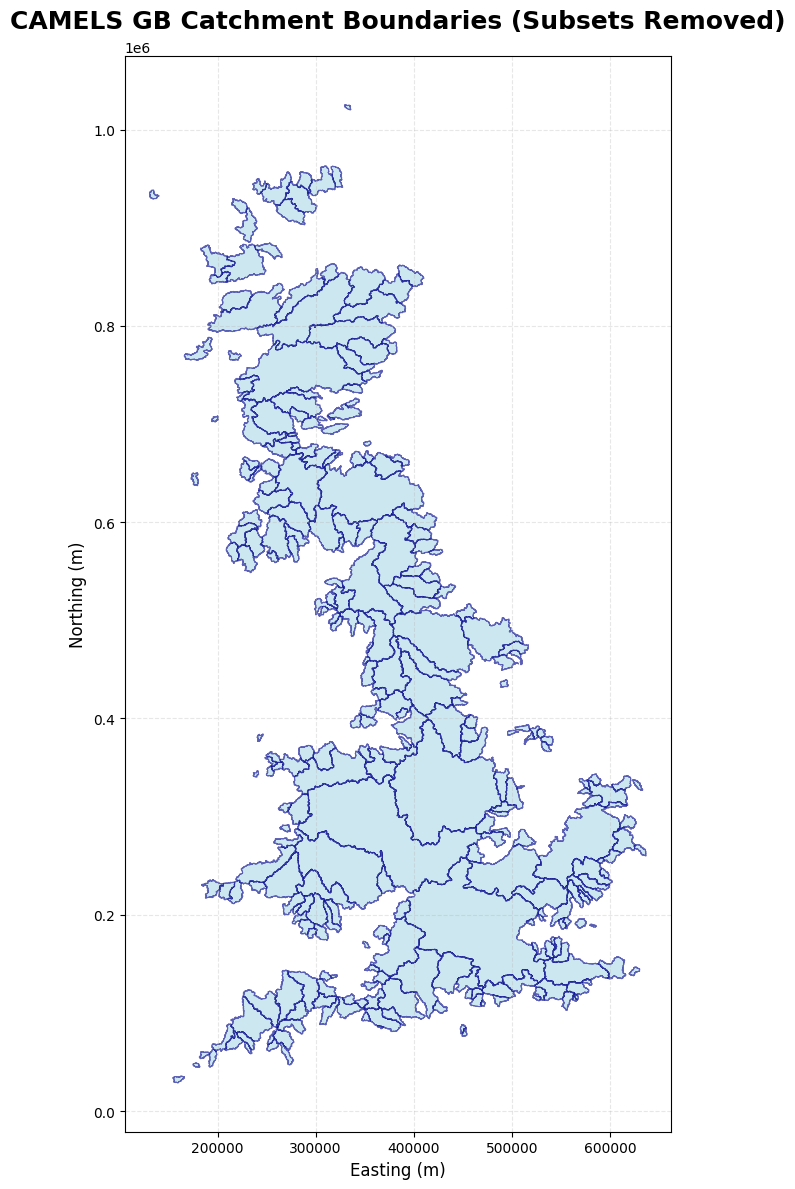


STEP 3: Creating catchments + gauges plot
Preparing gauge data...


In [20]:

# Configuration
shapefile_dir = "/perm/ecm3644/Caravane_Mapping/Caravan/shapefiles/camelsgb"

# Step 1: Load and filter catchments
print("STEP 1: Loading and filtering catchments")
catchments_gdf = load_and_filter_catchments(shapefile_dir)

# Step 2: Plot catchments only
print("STEP 2: Creating catchment-only plot")
plot_catchments_only(catchments_gdf)

# Step 3: Load gauge data and create combined plot
print("\n" + "="*70)
print("STEP 3: Creating catchments + gauges plot")
print("="*70)


# This assumes pairs_df is already defined
print("Preparing gauge data...")
res_gdf, nonres_gdf = prepare_gauge_data(pairs_df, catchments_gdf.crs)




# Splitting Gauges by Catchments and Pairings

In [21]:
print(f"Reservoir gauges: {len(res_gdf)}")
print(f"Non-reservoir gauges: {len(nonres_gdf)}")
# plot_catchments_with_gauges(catchments_gdf, res_gdf, nonres_gdf)



Reservoir gauges: 153
Non-reservoir gauges: 153


In [22]:
nonres_gdf['pair_id'] = nonres_gdf.index
res_gdf['pair_id'] = res_gdf.index

In [23]:
res_gdf['source']    = 'res'
nonres_gdf['source'] = 'nonres'

all_gdf = pd.concat([res_gdf, nonres_gdf], ignore_index=True)

stats_df = count_gauges_per_catchment(catchments_gdf, res_gdf, nonres_gdf)
stats_df



,reservoir_gauges,non_reservoir_gauges,total_gauges,pair_ids,area
152,16.0,11.0,27.0,"[34, 36, 37, 41, 42, 45, 46, 47, 49, 50, 51, 5...",8.209420e+09
471,8.0,6.0,14.0,"[26, 28, 33, 35, 38, 40, 43, 44]",9.885468e+09
26,6.0,6.0,12.0,"[137, 138, 139, 140, 141, 142]",4.586775e+09
71,6.0,5.0,11.0,"[110, 111, 112, 114, 116, 118]",4.398755e+09
639,5.0,4.0,9.0,"[113, 117, 121, 122, 124, 120]",1.901227e+09
...,...,...,...,...,...
666,0.0,0.0,0.0,[],1.384606e+08
3,0.0,0.0,0.0,[],3.061156e+07
1,0.0,0.0,0.0,[],5.322869e+08
669,0.0,0.0,0.0,[],1.053494e+08


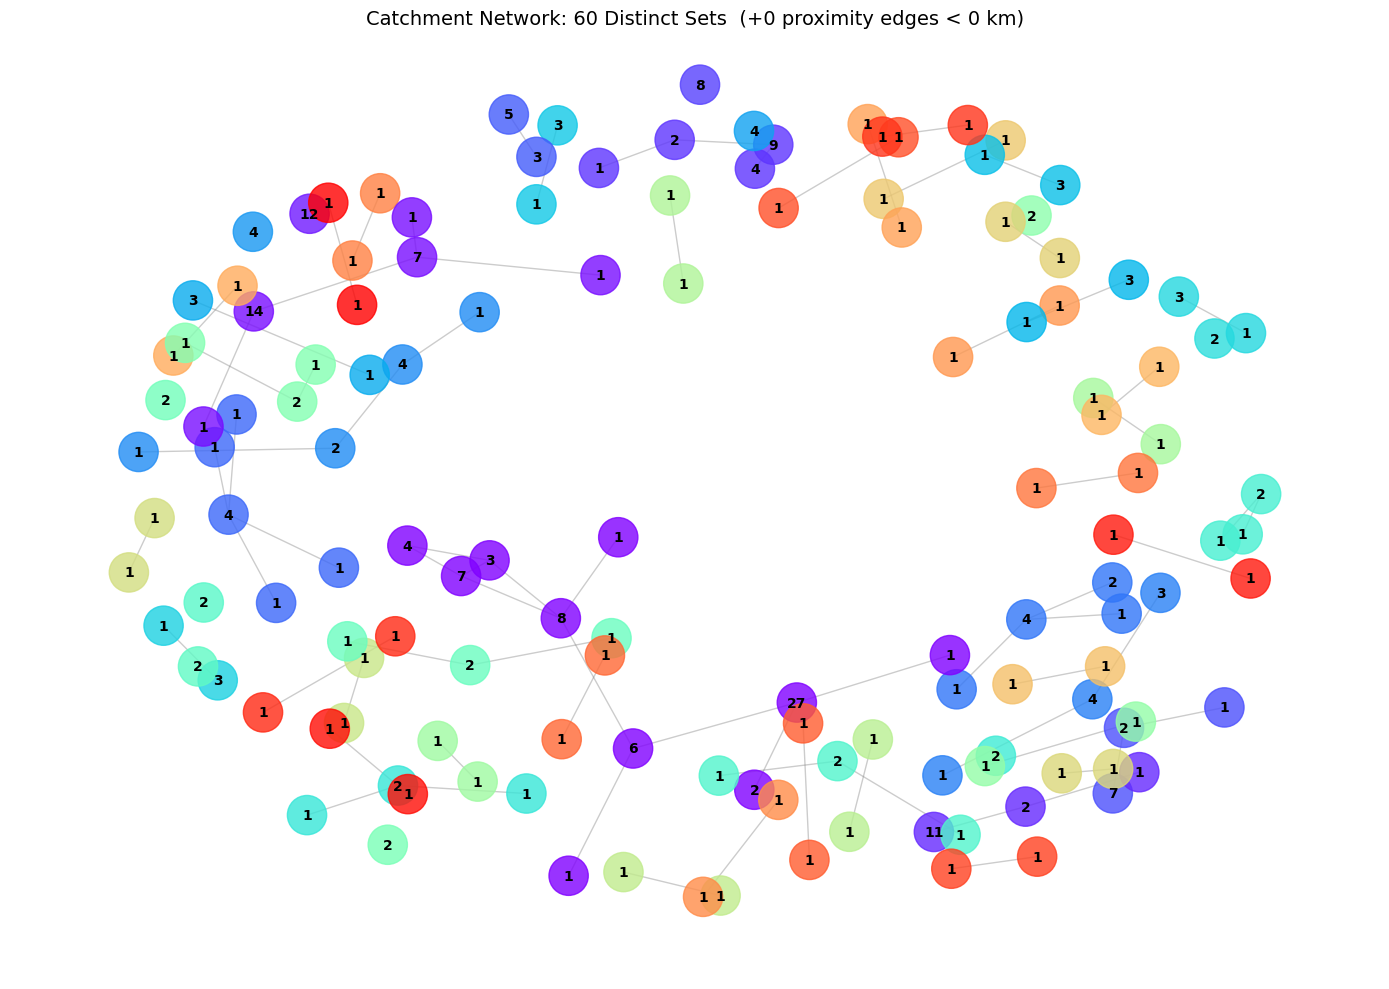

In [24]:
min_distance = 0
components = plot_catchment_sets_distance(stats_df, gauge_gdf=all_gdf, distance_threshold_km= min_distance)
component_df = get_component_stats_distance(stats_df, gauge_gdf=all_gdf, distance_threshold_km=min_distance)

In [25]:
# Usage
sets_df = get_component_stats(stats_df)


In [26]:
random_seed = random.randint(0, 100) # Seed of 0,1, 6, 8, 11, 33 are decent 0, 11, 13, 33, 49 best so far
# [55, 64, 69, 75, 84, 85, 89, 96]
random_seed = 0 # 0 in the paper right now
print(random_seed)
sets_with_splits = assign_splits_greedy(component_df, optimize_by='Total Gauges', random_seed=random_seed,
                         top_n_locked= 0) # sets_df 

# Create a mapping from pair_id to set_id and split
pair_to_set = {}
pair_to_split = {}
for idx, row in sets_with_splits.iterrows():
    set_id = row['set_id']
    split = row['split']
    for pair_id in row['pair_ids']:
        pair_to_set[pair_id] = set_id
        pair_to_split[pair_id] = split

# Assign set_id and split to gauges based on pair_id
res_gdf['set_id'] = res_gdf['pair_id'].map(pair_to_set)
res_gdf['split'] = res_gdf['pair_id'].map(pair_to_split)

nonres_gdf['set_id'] = nonres_gdf['pair_id'].map(pair_to_set)
nonres_gdf['split'] = nonres_gdf['pair_id'].map(pair_to_split)

# Display sets_df
sets_with_splits.head(10)

0

Split Assignment Summary (optimized by Total Gauges):
TRAIN : 41 sets |  96 catchments ( 70.1%) | 214 gauges ( 69.9%)
VAL   : 11 sets |  21 catchments ( 15.3%) |  46 gauges ( 15.0%)
TEST  :  8 sets |  20 catchments ( 14.6%) |  46 gauges ( 15.0%)


,set_id,Catchments,Total Gauges,pair_ids,split
0,1,10,60,"[71, 76, 82, 83, 84, 74, 75, 77, 78, 85, 86, 8...",train
1,2,5,24,"[61, 26, 54, 28, 33, 35, 38, 40, 43, 44, 48, 53]",test
2,3,1,12,"[137, 138, 139, 140, 141, 142]",train
3,4,3,14,"[119, 118, 110, 111, 112, 114, 116]",train
4,5,4,16,"[125, 122, 124, 123, 120, 113, 117, 121]",val
5,6,1,8,"[24, 27, 29, 31]",val
6,7,3,10,"[12, 15, 16, 17, 18]",train
7,8,2,8,"[93, 97, 104, 100]",train
8,9,5,8,"[65, 66, 68, 69]",train
9,10,4,8,"[80, 70, 72, 79]",train


In [27]:
# # # List to store the seeds that meet your criteria
# successful_seeds = []

# # Loop from 42 to 100 (inclusive)
# for random_seed in range(42, 101):
    
#     # Run your assignment function
#     sets_with_splits = assign_splits_greedy(
#         component_df, 
#         optimize_by='Total Gauges', 
#         random_seed=random_seed,
#         top_n_locked=0
#     )
    
#     # Grab the first 3 values of the 'split' column and convert to a set
#     first_three_splits = set(sets_with_splits['split'].head(3))
    
#     # Check if the set contains exactly our three required splits
#     if first_three_splits == {'test', 'train', 'val'}:
#         print(f"Success! Seed {random_seed} meets the criteria.")
#         successful_seeds.append(random_seed)

# print(f"\nAll successful seeds between 42 and 100: {successful_seeds}")

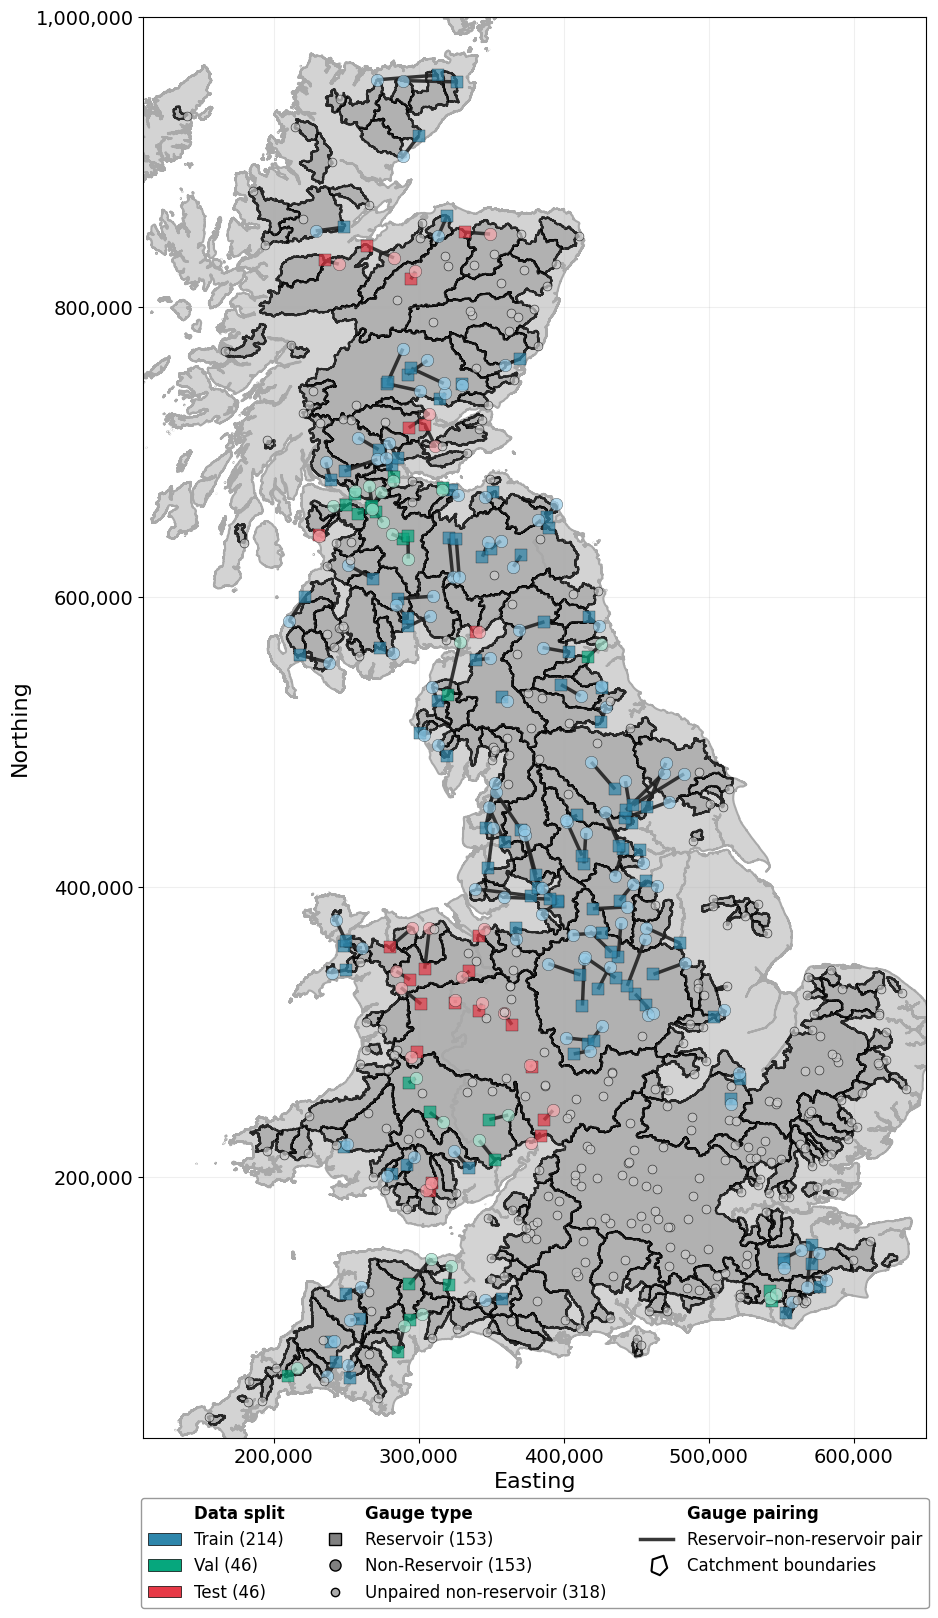

In [29]:
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.path as mpath
import geopandas as gpd
import numpy as np
import time

# --- Define split and nonres_gdf ---
splits = ["train", "val", "test"]
res_by_split = {s: res_gdf[res_gdf["split"] == s] for s in splits}
nonres_by_split = {s: nonres_gdf[nonres_gdf["split"] == s] for s in splits}
res_coords = res_gdf.geometry.values
nonres_coords = nonres_gdf.geometry.values
res_splits = res_gdf["split"].values

# ── Updated Color Definitions ──────────────────────────────────────────
# 1. Your original "base" colors, which we will use for Reservoir gauges (squares)
split_colors_res = {"train": "#2E86AB", "val": "#06A77D", "test": "#E63946"}

# 2. Corresponding lighter hues of the same colors for Non-Reservoir gauges (circles)
split_colors_light = {"train": "#97CEEB", "val": "#A6E7D2", "test": "#F7A8AE"}
# ───────────────────────────────────────────────────────────────────────

MARKER_SIZE = 80
UNPAIRED_SIZE = 40
LINE_WIDTH = 2.5
LINE_COLOR = '#222222'
LINE_ALPHA = 0.9
ALPHA = 0.7
TITLE_FONT = 18
LABEL_FONT = 16
LEGEND_FONT = 12
TICK_SIZE = 14

t_total = time.time()

# ── Figure with extra top margin for the legend ────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 16))
fig.subplots_adjust(top=0.85)

# UK boundary
uk_boundary_filtered.plot(ax=ax, color="lightgray", edgecolor="darkgray", linewidth=1.5)

# Catchments
catchments_gdf.plot(ax=ax, color="darkgray", edgecolor="black", linewidth=1.5, alpha=0.8)

# ── Gauge scatter with updated color logic ──────────────────────
for split in splits:
    # 3. Iterate through types and markers, including a type name ('res' or 'nonres')
    for gdf, marker, type_name in [
        (res_by_split[split], "s", "res"),       # Reservoir -> Square
        (nonres_by_split[split], "o", "nonres") # Non-Reservoir -> Circle
    ]:
        # 4. Use the correct color dictionary based on the gauge type
        color_dict = split_colors_res if type_name == "res" else split_colors_light
        
        ax.scatter(gdf.geometry.x.values, gdf.geometry.y.values,
                    c=color_dict[split], # ← Use the updated, distinct color
                    s=MARKER_SIZE, alpha=ALPHA,
                    edgecolors="black", linewidths=0.3, marker=marker, zorder=3)
# ──────────────────────────────────────────────────────────────────

# Pair lines — single dark colour so they stand out against the basemap
for split in splits:
    mask = res_splits == split
    xs_res = np.array([g.x for g in res_coords[mask]])
    ys_res = np.array([g.y for g in res_coords[mask]])
    xs_nonres = np.array([g.x for g in nonres_coords[mask]])
    ys_nonres = np.array([g.y for g in nonres_coords[mask]])
    segments = np.stack([np.column_stack([xs_res, ys_res]),
                          np.column_stack([xs_nonres, ys_nonres])], axis=1)
    lc = LineCollection(segments, colors=LINE_COLOR,
                        alpha=LINE_ALPHA, linewidths=LINE_WIDTH, zorder=2)
    ax.add_collection(lc)

# Unpaired gauges — use a visible grey instead of white
unpaired_non_reservoir.plot(ax=ax, color="#CCCCCC", markersize=UNPAIRED_SIZE, alpha=0.7,
                             edgecolor="black", linewidth=0.5, zorder=3)

# ── Axes formatting ────────────────────────────────────────────────────────────
ax.set_xlabel("Easting", fontsize=LABEL_FONT)
ax.set_ylabel("Northing", fontsize=LABEL_FONT)
ax.set_aspect("equal")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_xlim(110_000, 650_000)
ax.set_ylim(20_000, 1_000_000)
ax.tick_params(axis="both", labelsize=TICK_SIZE)
ax.grid(True, alpha=0.2)

# ── Custom 3-column legend placed at the top ─────────────────────────────────

# 1. Column 1 items: Data Split (Showing the base/reservoir color)
split_handles = [
    Patch(facecolor=split_colors_res[s], edgecolor="black", linewidth=0.5,
          label=f"{s.capitalize()} ({len(res_by_split[s])+len(nonres_by_split[s])})")
    for s in splits
]

# 2. Column 2 items: Gauge Type (With generic placeholders)
total_res = len(res_gdf)
total_nonres = len(nonres_gdf)
total_unpaired = len(unpaired_non_reservoir)

type_handles = [
    Line2D([0], [0], marker="s", color="none", markerfacecolor="grey",
            markeredgecolor="black", markersize=8, label=f"Reservoir ({total_res})"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="grey",
            markeredgecolor="black", markersize=8, label=f"Non-Reservoir ({total_nonres})"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#AAAAAA",
            markeredgecolor="black", markersize=6, label=f"Unpaired non-reservoir ({total_unpaired})"),
]

# 3. Column 3 items: Gauge Pairing & Boundaries
# Create an irregular, "wonky" polygon path to represent a catchment shape
catchment_verts = [[-0.5, -0.5], [0.2, -0.8], [0.8, -0.2], [0.5, 0.8], [-0.4, 0.5], [-0.5, -0.5]]
catchment_path = mpath.Path(catchment_verts)

pairing_handles = [
    Line2D([0], [0], color=LINE_COLOR, linewidth=LINE_WIDTH, alpha=LINE_ALPHA,
           label="Reservoir–non-reservoir pair"),
    Line2D([0], [0], marker=catchment_path, color="none", markeredgecolor="black", 
           markerfacecolor="none", markersize=14, markeredgewidth=1.5, 
           label="Catchment boundaries")
]

# Blank handle helper used for bold section titles and empty spacing
def section_title(text):
    return Patch(color="none", label=text)

# --- Force the layout row-by-row for a 3-column grid ---
all_handles_horizontal = [
    section_title("Data split"),    split_handles[0],   split_handles[1],   split_handles[2],
    section_title("Gauge type"),    type_handles[0],    type_handles[1],    type_handles[2],
    section_title("Gauge pairing"), pairing_handles[0], pairing_handles[1], section_title("")
]

leg = ax.legend(
    handles=all_handles_horizontal,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    borderaxespad=0,
    frameon=True,
    edgecolor="grey",
    fontsize=LEGEND_FONT,
)

# Make the section-title entries bold and hide their blank handles
for text, handle in zip(leg.get_texts(), leg.legend_handles):
    if text.get_text() in ("Data split", "Gauge type", "Gauge pairing", ""):
        text.set_fontweight("bold")
        handle.set_visible(False)   

plt.tight_layout()
plt.show()

In [30]:
catchment_splits['reservoir_train'][0]
res_gdf['gauge_id'] = res_gdf['gauge_id'].astype(int).astype(str)
res_gdf['gauge_id'] 


pairs_df['split'] = pairs_df['reservoir_gauge_id'].map(
    res_gdf.set_index('gauge_id')['split']
)



catchment_splits = create_catchment_splits(catchment_pairings, pairs_df)

# Save to file
output_path = (
    "/home/mokr/Reservoir_Modelling/Sample_Pairs/2003_catchment_date_pairs_splits.pkl"
)
with open(output_path, "wb") as f:
    pickle.dump(catchment_splits, f)
print(f"\nSaved to {output_path}")

# Verify the structure
print(f"\nExample entry from reservoir_train:")
print(catchment_splits["reservoir_train"][0])

reservoir_train: 903643 entries
reservoir_val: 187869 entries
reservoir_test: 250213 entries
non_reservoir_train: 849976 entries
non_reservoir_val: 174214 entries
non_reservoir_test: 250213 entries

Saved to /home/mokr/Reservoir_Modelling/Sample_Pairs/2003_catchment_date_pairs_splits.pkl

Example entry from reservoir_train:
{'gauge_id': '47011', 'pair_id': 1, 'init_date': Timestamp('2000-04-17 00:00:00'), 'catchment_type': 'paired_reservoir'}


In [31]:
# ── 1. Combine both GeoDataFrames ─────────────────────────────────────────────
res_gdf['source']    = 'res'
nonres_gdf['source'] = 'nonres'

all_gdf = pd.concat([res_gdf, nonres_gdf], ignore_index=True)

# ── 2. Compute all pairwise distances between gauges in DIFFERENT splits ───────
records = []

for (i, row_a), (j, row_b) in product(all_gdf.iterrows(), all_gdf.iterrows()):
    if i >= j:                          # avoid duplicates & self-pairs
        continue
    if row_a['split'] == row_b['split']:  # only cross-split pairs
        continue

    dist = row_a.geometry.distance(row_b.geometry)

    records.append({
        'gauge_id_a':   row_a['gauge_id'],
        'gauge_name_a': row_a['gauge_name'],
        'split_a':      row_a['split'],
        'source_a':     row_a['source'],
        'gauge_id_b':   row_b['gauge_id'],
        'gauge_name_b': row_b['gauge_name'],
        'split_b':      row_b['split'],
        'source_b':     row_b['source'],
        'distance_km':   dist*1e-3,
    })

distances_df = pd.DataFrame(records).sort_values('distance_km').reset_index(drop=True)

# ── 3. Closest pair overall ────────────────────────────────────────────────────
closest = distances_df.iloc[0]
print("=== Closest cross-split pair ===")
print(f"  {closest.gauge_name_a} ({closest.split_a}, {closest.source_a})")
print(f"  {closest.gauge_name_b} ({closest.split_b}, {closest.source_b})")
print(f"  Distance: {closest.distance_km:.1f} km")

# ── 4. Closest pair for every split combination ───────────────────────────────
print("\n=== Closest pair per split combination ===")
for combo, grp in distances_df.groupby(['split_a', 'split_b']):
    row = grp.iloc[0]
    print(f"  {combo[0]} ↔ {combo[1]}: "
          f"{row.gauge_name_a} — {row.gauge_name_b}  "
          f"({row.distance_km:.1f} km)")


=== Closest cross-split pair ===
  Water of Leith at Murrayfield (train, res)
  Almond at Craigiehall (val, res)
  Distance: 6.3 km

=== Closest pair per split combination ===
  test ↔ train: Almond at Almondbank — Braan at Hermitage  (16.8 km)
  test ↔ val: Esk at Canonbie — Kirtle Water at Mossknowe  (12.8 km)
  train ↔ test: Tay at Ballathie — Almond at Almondbank  (12.5 km)
  train ↔ val: Water of Leith at Murrayfield — Almond at Craigiehall  (6.3 km)
  val ↔ test: Kirtle Water at Mossknowe — Liddel Water at Rowanburnfoot  (14.4 km)
  val ↔ train: Carron at Headswood — Bannock Burn at Bannockburn  (9.1 km)


In [32]:
from itertools import combinations

def avg_pairwise_distance(gdf):
    coords = np.array([(geom.x, geom.y) for geom in gdf.geometry])
    distances = [
        np.sqrt((x1 - x2)**2 + (y1 - y2)**2)
        for (x1, y1), (x2, y2) in combinations(coords, 2)
    ]
    return np.mean(distances)*1e-3

avg_res = avg_pairwise_distance(res_gdf)
avg_nonres = avg_pairwise_distance(nonres_gdf)

print(f"Average distance between res gauges:    {avg_res:,.2f}")
print(f"Average distance between nonres gauges: {avg_nonres:,.2f}")

Average distance between res gauges:    281.99
Average distance between nonres gauges: 280.95


In [33]:
gauge_to_split = all_gdf.set_index('gauge_id')['split']
pairs_df['split'] = pairs_df['reservoir_gauge_id'].map(gauge_to_split)

pairs_df['calculated_distance_km'].mean()

distances_df[distances_df['distance_km'] < 12.8]

,gauge_id_a,gauge_name_a,split_a,source_a,gauge_id_b,gauge_name_b,split_b,source_b,distance_km
0,19006,Water of Leith at Murrayfield,train,res,19001,Almond at Craigiehall,val,res,6.343293
1,19006,Water of Leith at Murrayfield,train,res,19017,Gogar Burn at Turnhouse,val,nonres,6.870218
2,75004,Cocker at Southwaite Bridge,train,res,75003,Derwent at Ouse Bridge,val,res,8.377332
3,17001,Carron at Headswood,val,res,18014,Bannock Burn at Bannockburn,train,res,9.099707
4,18014,Bannock Burn at Bannockburn,train,res,17003,Bonny Water at Bonnybridge,val,nonres,11.201685
5,19001,Almond at Craigiehall,val,res,19010,Braid Burn at Liberton,train,nonres,11.515789
6,19010,Braid Burn at Liberton,train,nonres,19017,Gogar Burn at Turnhouse,val,nonres,11.731701
7,75003,Derwent at Ouse Bridge,val,res,75017,Ellen at Bullgill,train,nonres,12.287860
8,23016,Ouse Burn at Crag Hall,val,nonres,22006,Blyth at Hartford Bridge,train,nonres,12.307837
9,15006,Tay at Ballathie,train,res,15013,Almond at Almondbank,test,nonres,12.452510


In [34]:
all_gdf['gauge_id']
All_Static_Variables['gauge_id']

0        1001.0
1        2001.0
2        2002.0
3        3003.0
4        4001.0
         ...   
666    101002.0
667    101005.0
668    102001.0
669    106001.0
670    107001.0
Name: gauge_id, Length: 671, dtype: float64

In [35]:
all_gdf

,gauge_id,gauge_name,split,geometry,type,pair_id,source,set_id
0,48011,Fowey at Restormel,val,POINT (209757.32 62339.436),reservoir,0,res,21
1,47011,Plym at Carn Wood,train,POINT (252366.207 60974.397),reservoir,1,res,56
2,47001,Tamar at Gunnislake,train,POINT (242756.333 72380.038),reservoir,2,res,16
3,46014,Teign at Chudleigh,val,POINT (285447.595 79062.837),reservoir,3,res,57
4,47008,Thrushel at Tinhay,train,POINT (239621.533 85828.887),reservoir,4,res,16
...,...,...,...,...,...,...,...,...
301,4005,Meig at Glenmeanie,train,POINT (228862.358 852481.623),non_reservoir,148,nonres,29
302,7006,Lossie at Torwinny,train,POINT (313248.201 848687.96),non_reservoir,149,nonres,26
303,2002,Brora at Bruachrobie,train,POINT (289010.703 903859.745),non_reservoir,150,nonres,44
304,96001,Halladale at Halladale,train,POINT (289305.278 956209.991),non_reservoir,151,nonres,36


In [36]:
all_gdf.to_csv('/home/mokr/Reservoir_Modelling/20March_GaugeSplit.csv', index=False)

# Properties of Train, Validation, Test Splits

In [37]:
all_gdf_static = All_Static_Variables[
    All_Static_Variables['gauge_id'].astype('Int64').astype(str).isin(all_gdf['gauge_id'])
].copy()

all_gdf_static['gauge_id'] = all_gdf_static['gauge_id'].astype('Int64').astype(str)
# Merge split column from all_gdf into all_gdf_static
all_gdf_static = pd.concat(
    [
        all_gdf_static.set_index('gauge_id'),
        all_gdf.set_index('gauge_id')[['split', 'type']]
    ],
    axis=1
).loc[all_gdf_static['gauge_id']].reset_index()

all_gdf_static

,gauge_id,inter_high_perc,inter_mod_perc,inter_low_perc,frac_high_perc,frac_mod_perc,frac_low_perc,no_gw_perc,low_nsig_perc,nsig_low_perc,...,dwood_perc_2022,ewood_perc_2022,grass_perc_2022,shrub_perc_2022,crop_perc_2022,urban_perc_2022,inwater_perc_2022,bares_perc_2022,split,type
0,1001,0.0,10.19,0.0,0.0,2.25,0.00,87.56,0.00,0.0,...,0.79,11.23,34.44,38.81,10.55,0.62,3.31,0.24,train,reservoir
1,2001,0.0,9.86,0.0,0.0,1.01,3.27,85.86,0.00,0.0,...,0.34,5.45,10.24,80.82,0.00,0.01,3.15,0.01,train,reservoir
2,2002,0.0,8.81,0.0,0.0,0.78,3.39,86.95,0.06,0.0,...,1.16,4.77,9.89,82.85,0.00,0.01,1.33,0.00,train,non_reservoir
3,4001,0.0,8.16,0.0,0.0,0.20,21.75,69.76,0.12,0.0,...,4.40,6.97,34.72,47.69,0.67,0.07,3.95,1.53,train,reservoir
4,4005,0.0,7.83,0.0,0.0,0.00,33.26,58.91,0.00,0.0,...,1.56,4.83,49.35,41.84,0.07,0.01,0.94,1.40,train,non_reservoir
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
301,85004,0.0,4.03,0.0,0.0,0.00,30.82,65.15,0.00,0.0,...,2.83,0.00,80.67,16.47,0.02,0.00,0.00,0.00,train,non_reservoir
302,96001,0.0,9.50,0.0,0.0,0.38,0.34,89.77,0.00,0.0,...,0.07,20.55,14.02,64.46,0.00,0.00,0.90,0.00,train,non_reservoir
303,96002,0.0,10.38,0.0,0.0,0.00,9.04,80.58,0.00,0.0,...,1.06,4.75,33.49,57.25,0.00,0.00,3.43,0.02,train,non_reservoir
304,97002,0.0,7.88,0.0,0.0,2.82,0.15,89.15,0.00,0.0,...,0.13,13.20,14.06,68.27,1.18,0.13,3.04,0.00,train,reservoir


In [38]:
all_gdf['gauge_id']

0      48011
1      47011
2      47001
3      46014
4      47008
       ...  
301     4005
302     7006
303     2002
304    96001
305    96002
Name: gauge_id, Length: 306, dtype: object

In [39]:
static_variables = pd.read_csv(
    "/perm/mokr/Scaled_CamelsGB_V2/normalised_static_data.csv", dtype={"gauge_id": str}
)

static_variables = static_variables.set_index("gauge_id")
static_variables = static_variables.select_dtypes(include=[np.number])

static_variables


,inter_high_perc,inter_mod_perc,inter_low_perc,frac_high_perc,frac_mod_perc,frac_low_perc,no_gw_perc,low_nsig_perc,nsig_low_perc,surfacewater_abs,...,inwater_perc_2021,bares_perc_2021,dwood_perc_2022,ewood_perc_2022,grass_perc_2022,shrub_perc_2022,crop_perc_2022,urban_perc_2022,inwater_perc_2022,bares_perc_2022
gauge_id,,,,,,,,,,,,,,,,,,,,,
1001,-0.256241,-0.646618,-0.209532,-0.417310,-0.312042,-0.663533,1.663244,-0.091367,-0.21683,-0.330072,...,2.277808,-0.284738,-1.214105,0.477580,-0.528713,1.503292,-0.467876,-0.561518,2.292226,-0.120675
2001,-0.256241,-0.668999,-0.209532,-0.417310,-0.383036,-0.518437,1.594632,-0.091367,-0.21683,-0.330072,...,2.174945,-0.291673,-1.297795,-0.069854,-1.674740,3.757503,-0.912428,-0.611897,2.155168,-0.307717
2002,-0.256241,-0.740208,-0.209532,-0.417310,-0.396204,-0.513113,1.638624,-0.030767,-0.21683,-0.330072,...,0.580566,-0.291673,-1.145293,-0.134258,-1.691315,3.866430,-0.912428,-0.611897,0.596141,-0.315849
3003,-0.256241,-0.947733,-0.209532,-0.417310,-0.428838,-0.123529,1.434001,-0.091367,-0.21683,-0.330072,...,0.726289,0.505795,-1.093220,0.578922,-1.037795,2.632275,-0.898943,-0.612723,0.741764,0.416054
4001,-0.256241,-0.784290,-0.209532,-0.417310,-0.429411,0.301553,0.944840,0.029834,-0.21683,-0.330072,...,2.809267,1.220049,-0.542728,0.074108,-0.515453,1.979783,-0.884195,-0.606942,2.840455,0.928385
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101002,4.947122,0.770110,-0.177954,-0.199549,-0.440861,-0.663533,-1.092116,-0.091367,-0.21683,-0.278132,...,-0.088044,-0.291673,-0.096384,-0.563302,0.035776,-0.579211,0.845552,-0.270809,-0.140543,-0.088146
101005,3.058648,1.645646,-0.209532,0.036528,-0.440861,-0.663533,-1.134090,-0.091367,-0.21683,-0.323579,...,-0.439493,-0.291673,-0.661754,-0.586033,0.881563,-0.579211,0.242564,-0.241077,-0.457488,-0.315849
102001,-0.256241,-0.572696,-0.209532,-0.417310,-0.440861,-0.577452,1.631763,-0.091367,-0.21683,-0.330072,...,-0.559500,-0.291673,-1.268038,-0.586033,2.248746,-0.579211,-0.695840,-0.507836,-0.543149,-0.315849


In [40]:
all_gdf_static

,gauge_id,inter_high_perc,inter_mod_perc,inter_low_perc,frac_high_perc,frac_mod_perc,frac_low_perc,no_gw_perc,low_nsig_perc,nsig_low_perc,...,dwood_perc_2022,ewood_perc_2022,grass_perc_2022,shrub_perc_2022,crop_perc_2022,urban_perc_2022,inwater_perc_2022,bares_perc_2022,split,type
0,1001,0.0,10.19,0.0,0.0,2.25,0.00,87.56,0.00,0.0,...,0.79,11.23,34.44,38.81,10.55,0.62,3.31,0.24,train,reservoir
1,2001,0.0,9.86,0.0,0.0,1.01,3.27,85.86,0.00,0.0,...,0.34,5.45,10.24,80.82,0.00,0.01,3.15,0.01,train,reservoir
2,2002,0.0,8.81,0.0,0.0,0.78,3.39,86.95,0.06,0.0,...,1.16,4.77,9.89,82.85,0.00,0.01,1.33,0.00,train,non_reservoir
3,4001,0.0,8.16,0.0,0.0,0.20,21.75,69.76,0.12,0.0,...,4.40,6.97,34.72,47.69,0.67,0.07,3.95,1.53,train,reservoir
4,4005,0.0,7.83,0.0,0.0,0.00,33.26,58.91,0.00,0.0,...,1.56,4.83,49.35,41.84,0.07,0.01,0.94,1.40,train,non_reservoir
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
301,85004,0.0,4.03,0.0,0.0,0.00,30.82,65.15,0.00,0.0,...,2.83,0.00,80.67,16.47,0.02,0.00,0.00,0.00,train,non_reservoir
302,96001,0.0,9.50,0.0,0.0,0.38,0.34,89.77,0.00,0.0,...,0.07,20.55,14.02,64.46,0.00,0.00,0.90,0.00,train,non_reservoir
303,96002,0.0,10.38,0.0,0.0,0.00,9.04,80.58,0.00,0.0,...,1.06,4.75,33.49,57.25,0.00,0.00,3.43,0.02,train,non_reservoir
304,97002,0.0,7.88,0.0,0.0,2.82,0.15,89.15,0.00,0.0,...,0.13,13.20,14.06,68.27,1.18,0.13,3.04,0.00,train,reservoir


/etc/ecmwf/ssd/ssd1/jupyterhub/mokr-jupyterhub/tmpdirs/mokr.27833902/ipykernel_3655777/1676961440.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=all_gdf_static, x='split', y='area', order=split_order,


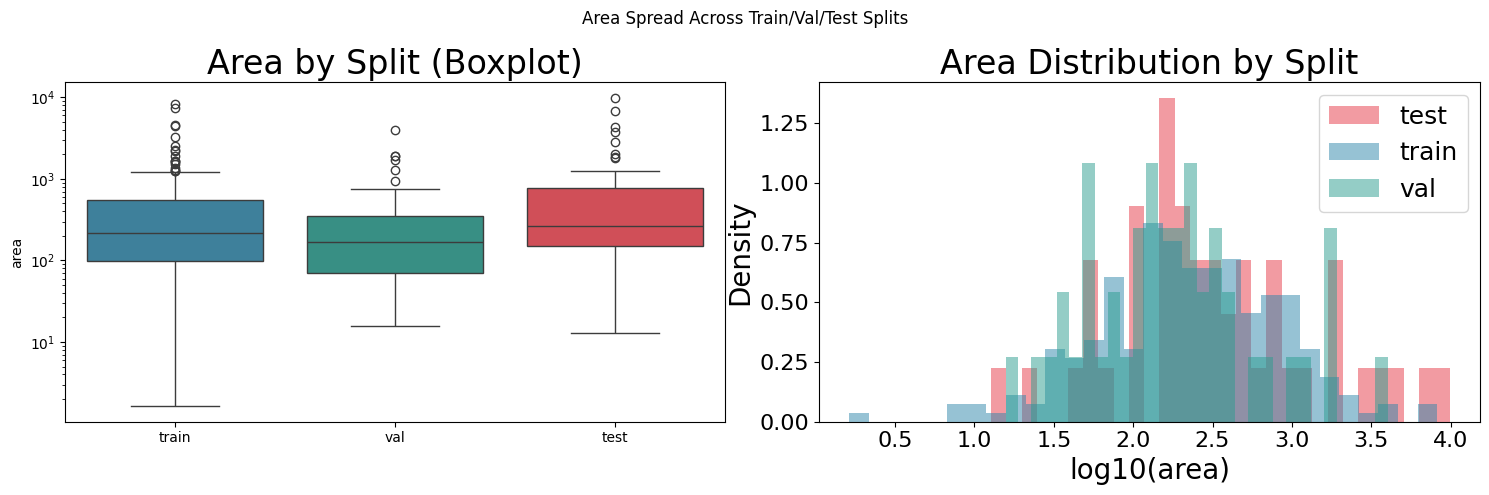

/etc/ecmwf/ssd/ssd1/jupyterhub/mokr-jupyterhub/tmpdirs/mokr.27833902/ipykernel_3655777/1676961440.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=all_gdf_static, x='split', y='p_mean', order=split_order,


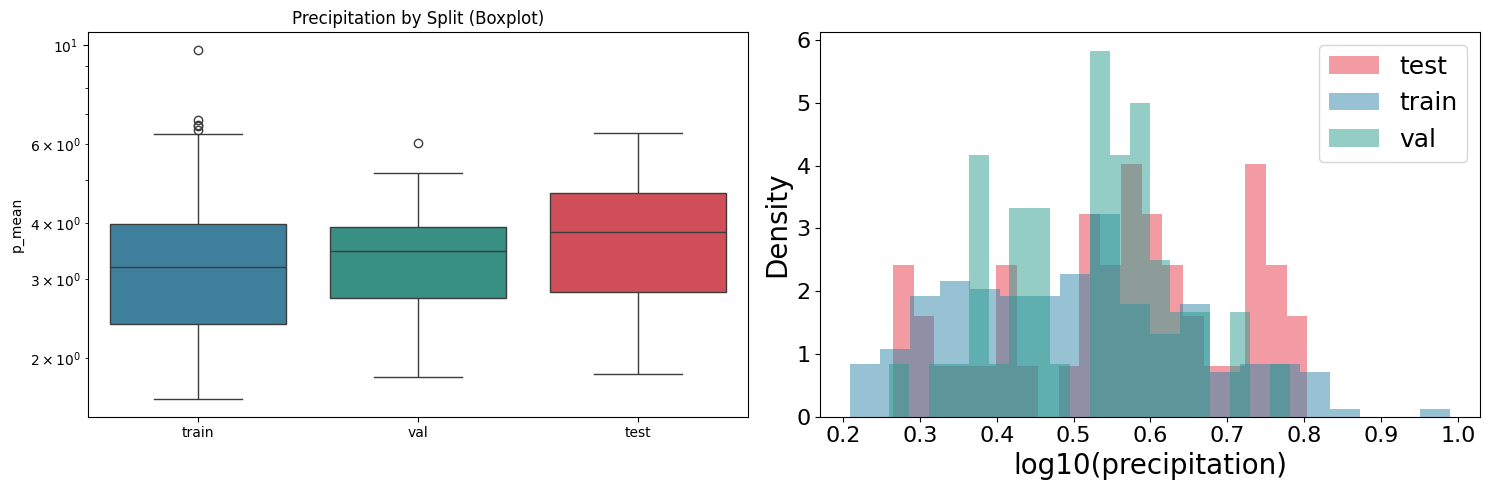

In [41]:
TITLE_SIZE = 24
LABEL_FONT = 20
TICK_SIZE = 16
LEGEND_FONT = 18
### Spread of Area

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
split_colors = {'train': '#2E86AB', 'val': '#2A9D8F', 'test': '#E63946'}
split_order = ['train', 'val', 'test']

# Option A: Box plots (great for spread/outliers)
sns.boxplot(data=all_gdf_static, x='split', y='area', order=split_order,
            palette=split_colors, ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Area by Split (Boxplot)', fontsize = TITLE_SIZE)
axes[0].set_xlabel('')


# Option B: Overlapping histograms / KDE
for split, grp in all_gdf_static.groupby('split'):
    axes[1].hist(np.log10(grp['area'].dropna()), bins=30, alpha=0.5, label=split, density=True, color=split_colors[split])
axes[1].set_xlabel('log10(area)', fontsize=LABEL_FONT)
axes[1].set_ylabel('Density', fontsize=LABEL_FONT)
axes[1].set_title('Area Distribution by Split', fontsize = TITLE_SIZE)
axes[1].tick_params(axis="both", labelsize=TICK_SIZE)
axes[1].legend(fontsize=LEGEND_FONT)

plt.suptitle('Area Spread Across Train/Val/Test Splits')
plt.tight_layout()
plt.show()


### Spread of Precipitation

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Option A: Box plots (great for spread/outliers)
sns.boxplot(data=all_gdf_static, x='split', y='p_mean', order=split_order,
            palette=split_colors, ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Precipitation by Split (Boxplot)')
axes[0].set_xlabel('')


# Option B: Overlapping histograms / KDE
for split, grp in all_gdf_static.groupby('split'):
    axes[1].hist(np.log10(grp['p_mean'].dropna()), bins=20, alpha=0.5, label=split, density=True, color=split_colors[split])
axes[1].set_xlabel('log10(precipitation)', fontsize=LABEL_FONT)
axes[1].set_ylabel('Density', fontsize=LABEL_FONT)
# axes[1].set_title('Precipitation Distribution by Split', fontsize = TITLE_SIZE)
axes[1].tick_params(axis="both", labelsize=TICK_SIZE)
axes[1].legend(fontsize=LEGEND_FONT)


# plt.suptitle('Precipitation Spread Across Train/Val/Test Splits')
plt.tight_layout()
plt.show()

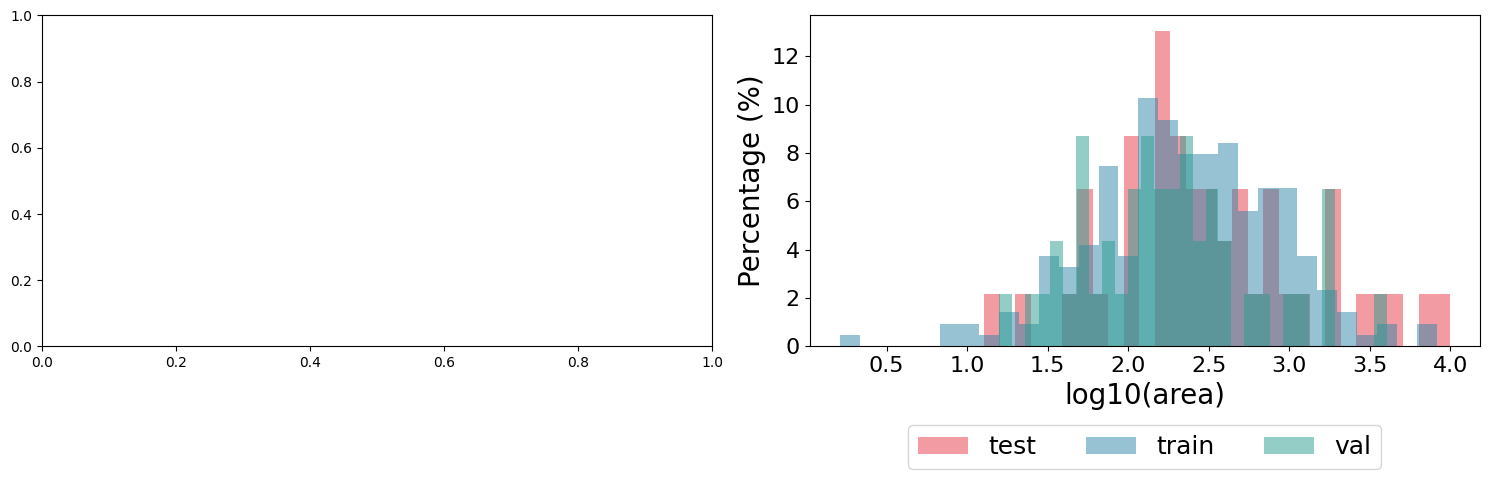

In [42]:
TITLE_SIZE = 24
LABEL_FONT = 20
TICK_SIZE = 16
LEGEND_FONT = 18

### Spread of Area
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
split_colors = {'train': '#2E86AB', 'val': '#2A9D8F', 'test': '#E63946'}
split_order = ['train', 'val', 'test']

# Option A: Box plots (great for spread/outliers)
# sns.boxplot(data=all_gdf_static, x='split', y='area', order=split_order,
#             palette=split_colors, ax=axes[0])
# axes[0].set_yscale('log')
# axes[0].set_title('Area by Split (Boxplot)', fontsize=TITLE_SIZE)
# axes[0].set_xlabel('')

# Option B: Overlapping histograms / KDE
for split, grp in all_gdf_static.groupby('split'):
    data = np.log10(grp['area'].dropna())
    # Calculate weights to show percentage per group
    weights = np.ones_like(data) / len(data) * 100
    
    axes[1].hist(data, bins=30, alpha=0.5, label=split, 
                 weights=weights, color=split_colors[split])
    
axes[1].set_xlabel('log10(area)', fontsize=LABEL_FONT)
axes[1].set_ylabel('Percentage (%)', fontsize=LABEL_FONT)
# axes[1].set_title('Area Distribution by Split', fontsize=TITLE_SIZE)
axes[1].tick_params(axis="both", labelsize=TICK_SIZE)

# Updated Legend Positioning
axes[1].legend(
    fontsize=LEGEND_FONT, 
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.2), # Pushes it below the x-axis
    ncol=3 # Lays the items out horizontally
)

# plt.suptitle('Area Spread Across Train/Val/Test Splits')
plt.tight_layout()
plt.show()


### Spread of Precipitation
# fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Option A: Box plots (great for spread/outliers)
# sns.boxplot(data=all_gdf_static, x='split', y='p_mean', order=split_order,
#             palette=split_colors, ax=axes[0])
# axes[0].set_yscale('log')
# axes[0].set_title('Precipitation by Split (Boxplot)')
# axes[0].set_xlabel('')

# Option B: Overlapping histograms / KDE
# for split, grp in all_gdf_static.groupby('split'):
#     data = np.log10(grp['p_mean'].dropna())
#     # Calculate weights to show percentage per group
#     weights = np.ones_like(data) / len(data) * 100
    
#     axes[1].hist(data, bins=20, alpha=0.5, label=split, 
#                  weights=weights, color=split_colors[split])
    
# axes[1].set_xlabel('log10(precipitation)', fontsize=LABEL_FONT)
# axes[1].set_ylabel('Percentage (%)', fontsize=LABEL_FONT)
# # axes[1].set_title('Precipitation Distribution by Split', fontsize=TITLE_SIZE)
# axes[1].tick_params(axis="both", labelsize=TICK_SIZE)

# # Updated Legend Positioning
# axes[1].legend(
#     fontsize=LEGEND_FONT, 
#     loc='upper center', 
#     bbox_to_anchor=(0.5, -0.2), # Pushes it below the x-axis
#     ncol=3 # Lays the items out horizontally
# )

# # plt.suptitle('Precipitation Spread Across Train/Val/Test Splits')
# plt.tight_layout()
# plt.show()

In [43]:

splits = all_gdf_static.groupby('split')['area'].apply(lambda x: x.dropna().values)

for (s1, g1), (s2, g2) in combinations(splits.items(), 2):
    stat, p = stats.ks_2samp(g1, g2)  # Kolmogorov-Smirnov
    print(f" Area {s1} vs {s2}: KS stat={stat:.3f}, p={p:.4f}")


    splits = all_gdf_static.groupby('split')['p_mean'].apply(lambda x: x.dropna().values)

for (s1, g1), (s2, g2) in combinations(splits.items(), 2):
    stat, p = stats.ks_2samp(g1, g2)  # Kolmogorov-Smirnov
    print(f"Precipitation {s1} vs {s2}: KS stat={stat:.3f}, p={p:.4f}")

 Area test vs train: KS stat=0.132, p=0.4791
 Area test vs val: KS stat=0.239, p=0.1446
 Area train vs val: KS stat=0.167, p=0.2121
Precipitation test vs train: KS stat=0.258, p=0.0102
Precipitation test vs val: KS stat=0.261, p=0.0873
Precipitation train vs val: KS stat=0.190, p=0.1129


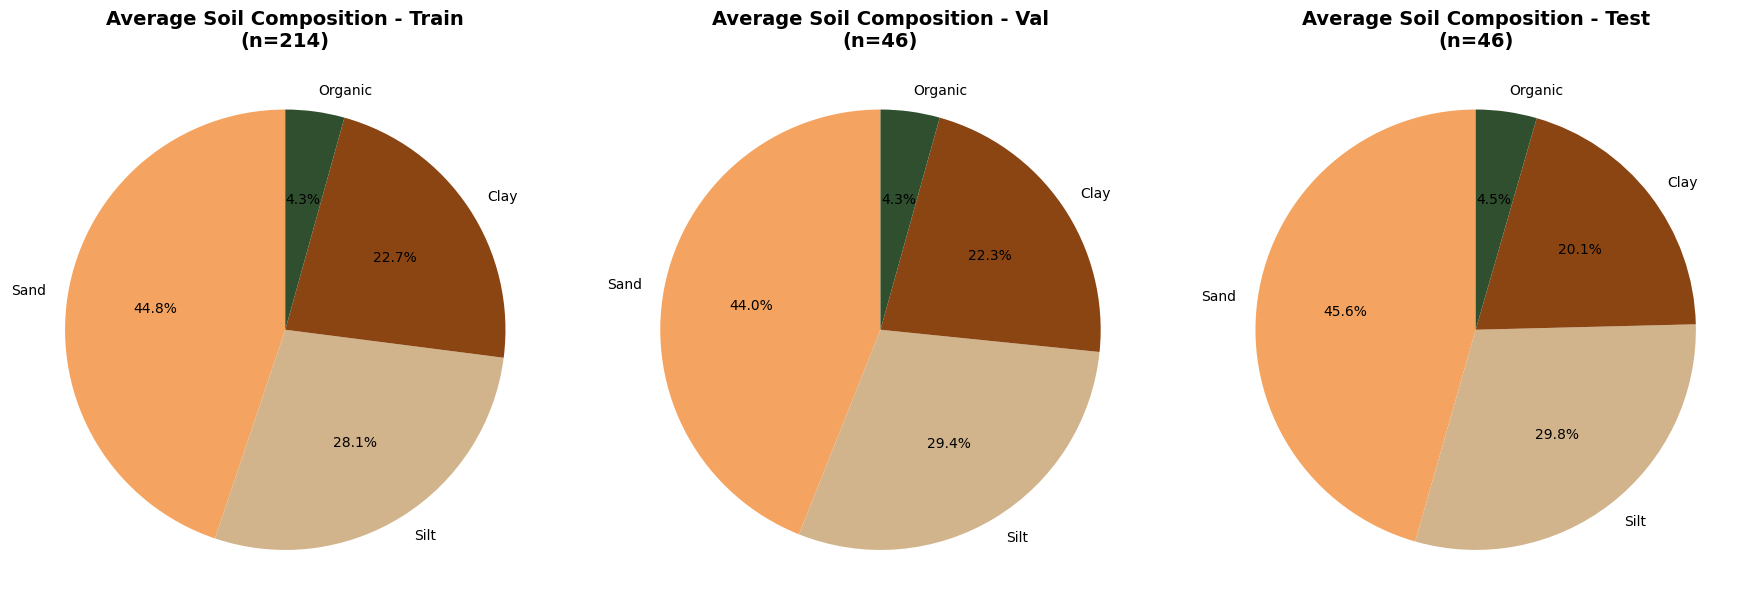

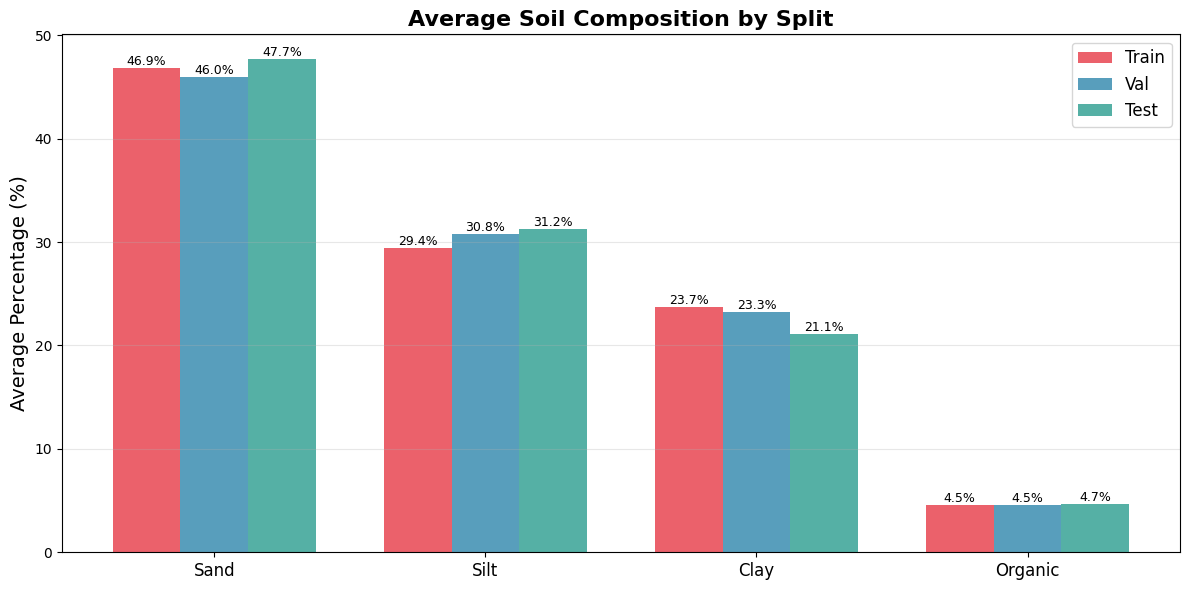


Average Soil Composition:

Train (n=214):
  Sand: 46.86%
  Silt: 29.41%
  Clay: 23.73%
  Organic: 4.53%
  Total: 104.52%

Val (n=46):
  Sand: 45.96%
  Silt: 30.76%
  Clay: 23.28%
  Organic: 4.53%
  Total: 104.53%

Test (n=46):
  Sand: 47.70%
  Silt: 31.22%
  Clay: 21.08%
  Organic: 4.68%
  Total: 104.68%


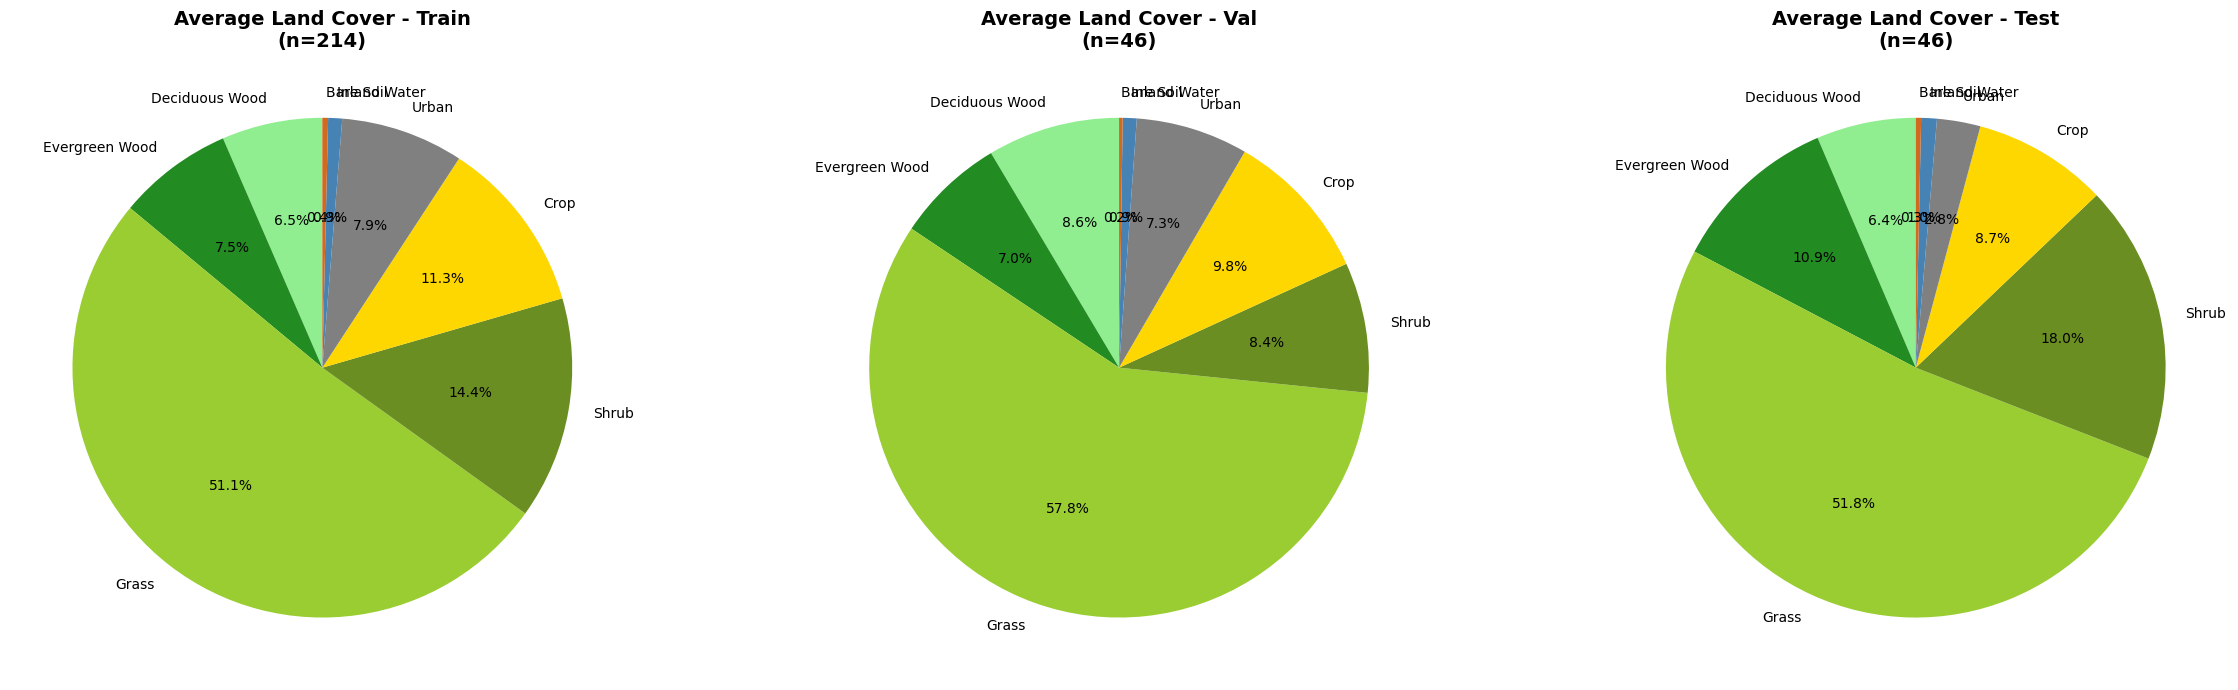

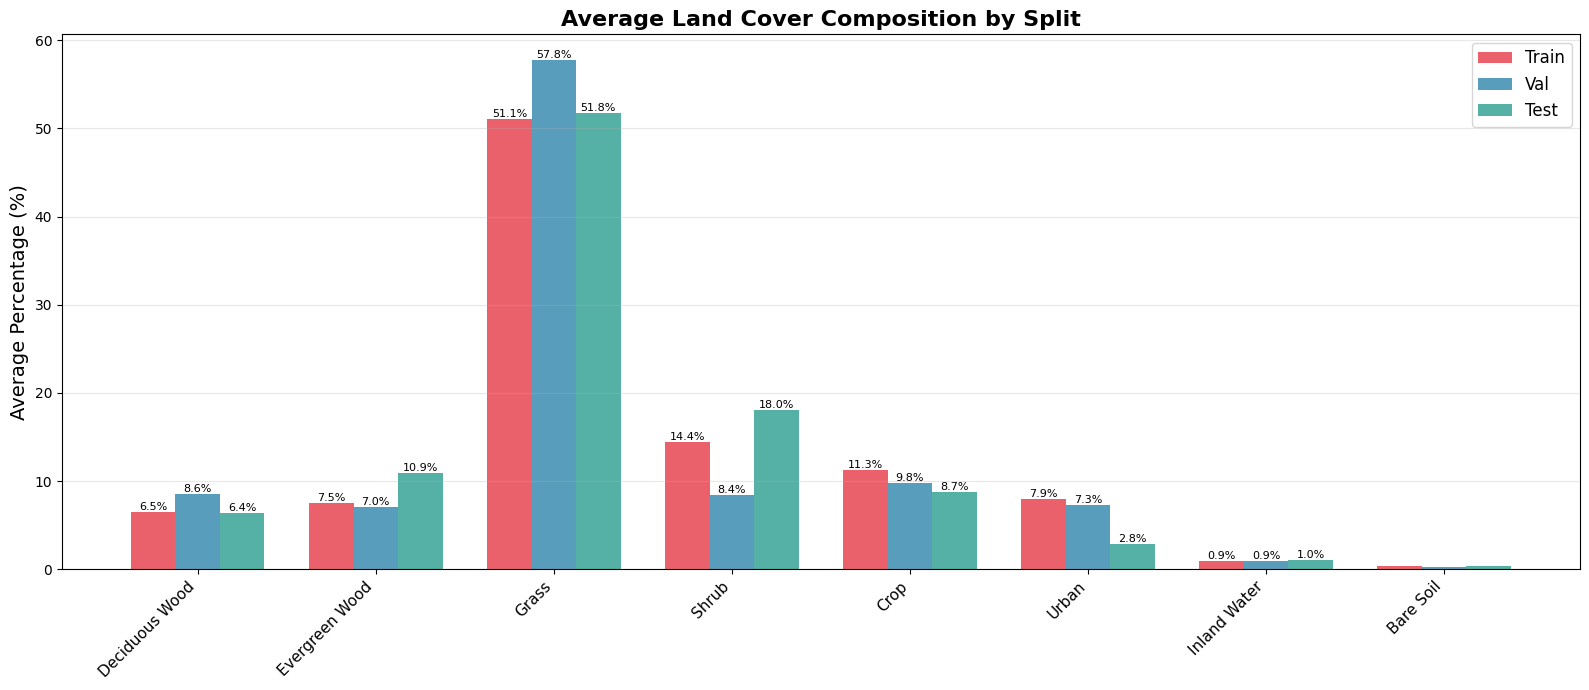

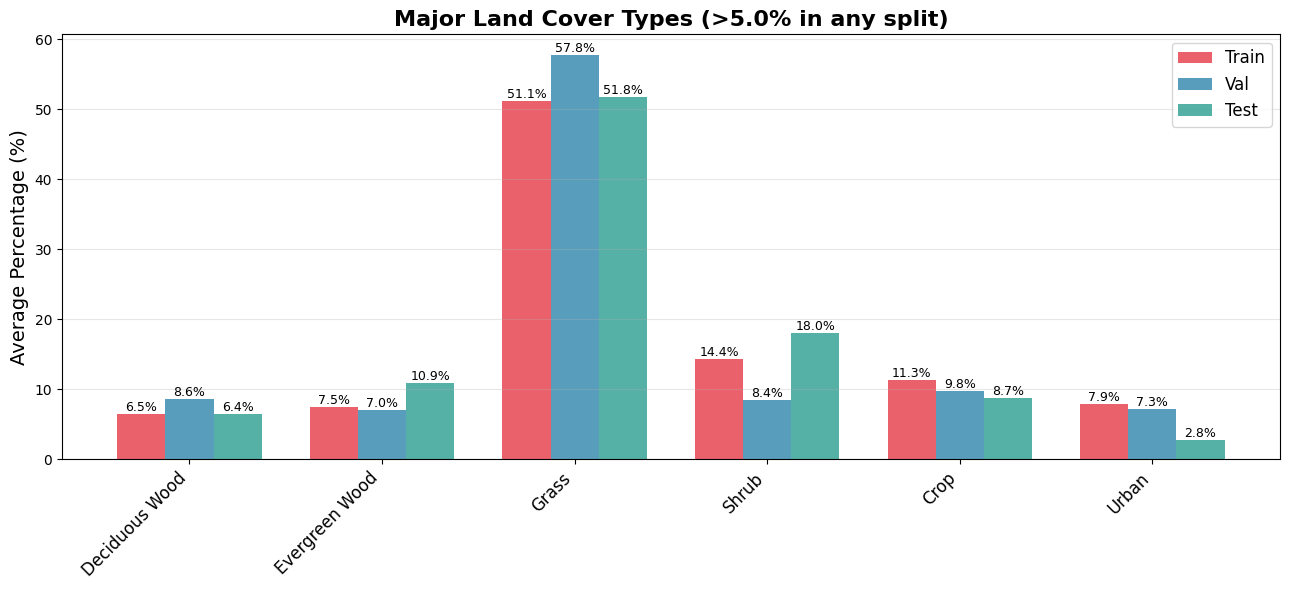


Average Land Cover Composition:

Train (n=214):
  Deciduous Wood: 6.51%
  Evergreen Wood: 7.46%
  Grass: 51.11%
  Shrub: 14.40%
  Crop: 11.30%
  Urban: 7.94%
  Inland Water: 0.90%
  Bare Soil: 0.37%
  Total: 100.00%

Val (n=46):
  Deciduous Wood: 8.56%
  Evergreen Wood: 7.05%
  Grass: 57.78%
  Shrub: 8.43%
  Crop: 9.79%
  Urban: 7.26%
  Inland Water: 0.90%
  Bare Soil: 0.23%
  Total: 100.00%

Test (n=46):
  Deciduous Wood: 6.43%
  Evergreen Wood: 10.88%
  Grass: 51.76%
  Shrub: 18.05%
  Crop: 8.71%
  Urban: 2.81%
  Inland Water: 1.01%
  Bare Soil: 0.34%
  Total: 100.00%


In [44]:
soil_columns = ['sand_perc', 'silt_perc', 'clay_perc', 'organic_perc']
soil_labels = ['Sand', 'Silt', 'Clay', 'Organic']
colors_soil = {'Sand': '#F4A460', 'Silt': '#D2B48C', 'Clay': '#8B4513', 'Organic': '#2F4F2F'}
pie_colors = [colors_soil[soil] for soil in soil_labels]

splits = ['train', 'val', 'test']
split_avgs = {}
for split in splits:
    grp = all_gdf_static[all_gdf_static['split'] == split]
    avg = grp[soil_columns].mean()
    avg.index = soil_labels
    split_avgs[split] = (avg, len(grp))

# --- Pie charts ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, split in zip(axes, splits):
    avg, n = split_avgs[split]
    ax.pie(avg.values, labels=avg.index, autopct='%1.1f%%',
           startangle=90, colors=pie_colors)
    ax.set_title(f'Average Soil Composition - {split.capitalize()}\n(n={n})',
                 fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Bar chart ---
split_colors = {'train': '#E63946', 'val': '#2E86AB', 'test': '#2A9D8F'}
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(soil_labels))
width = 0.25
offsets = [-width, 0, width]

for split, offset in zip(splits, offsets):
    avg, n = split_avgs[split]
    bars = ax.bar(x + offset, avg.values, width,
                  label=split.capitalize(), color=split_colors[split], alpha=0.8)
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}%', ha='center', va='bottom', fontsize=9)

ax.set_ylabel('Average Percentage (%)', fontsize=14)
ax.set_title('Average Soil Composition by Split', fontsize=16, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(soil_labels, fontsize=12)
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# --- Print stats ---
print("\nAverage Soil Composition:")
for split in splits:
    avg, n = split_avgs[split]
    print(f"\n{split.capitalize()} (n={n}):")
    for soil, pct in avg.items():
        print(f"  {soil}: {pct:.2f}%")
    print(f"  Total: {avg.sum():.2f}%")


year = 2022
landcover_columns = [f'dwood_perc_{year}', f'ewood_perc_{year}', f'grass_perc_{year}', f'shrub_perc_{year}', 
                     f'crop_perc_{year}', f'urban_perc_{year}', f'inwater_perc_{year}', f'bares_perc_{year}']

landcover_labels = ['Deciduous Wood', 'Evergreen Wood', 'Grass', 'Shrub', 
                    'Crop', 'Urban', 'Inland Water', 'Bare Soil']

colors_landcover = {
    'Deciduous Wood': '#90EE90', 'Evergreen Wood': '#228B22', 'Grass': '#9ACD32',
    'Shrub': '#6B8E23', 'Crop': '#FFD700', 'Urban': '#808080',
    'Inland Water': '#4682B4', 'Bare Soil': '#D2691E'
}
pie_colors = [colors_landcover[lc] for lc in landcover_labels]
split_colors = {'train': '#E63946', 'val': '#2E86AB', 'test': '#2A9D8F'}
splits = ['train', 'val', 'test']

split_avgs = {}
for split in splits:
    grp = all_gdf_static[all_gdf_static['split'] == split]
    avg = grp[landcover_columns].mean()
    avg.index = landcover_labels
    split_avgs[split] = (avg, len(grp))

# --- Pie charts ---
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, split in zip(axes, splits):
    avg, n = split_avgs[split]
    ax.pie(avg.values, labels=avg.index, autopct='%1.1f%%',
           startangle=90, colors=pie_colors)
    ax.set_title(f'Average Land Cover - {split.capitalize()}\n(n={n})',
                 fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Full bar chart ---
fig, ax = plt.subplots(figsize=(16, 7))
x = np.arange(len(landcover_labels))
width = 0.25
offsets = [-width, 0, width]

for split, offset in zip(splits, offsets):
    avg, n = split_avgs[split]
    bars = ax.bar(x + offset, avg.values, width,
                  label=split.capitalize(), color=split_colors[split], alpha=0.8)
    for bar in bars:
        height = bar.get_height()
        if height > 0.5:
            ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.1f}%', ha='center', va='bottom', fontsize=8)

ax.set_ylabel('Average Percentage (%)', fontsize=14)
ax.set_title('Average Land Cover Composition by Split', fontsize=16, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(landcover_labels, fontsize=11, rotation=45, ha='right')
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# --- Significant types only ---
significant_threshold = 5.0
all_avgs = [split_avgs[s][0] for s in splits]
significant_types = landcover_labels  # start with all
significant_mask = np.any([avg.values > significant_threshold for avg in all_avgs], axis=0)
significant_types = [lc for lc, sig in zip(landcover_labels, significant_mask) if sig]

if significant_types:
    fig, ax = plt.subplots(figsize=(13, 6))
    x = np.arange(len(significant_types))

    for split, offset in zip(splits, offsets):
        avg, n = split_avgs[split]
        sig_vals = avg[significant_types].values
        bars = ax.bar(x + offset, sig_vals, width,
                      label=split.capitalize(), color=split_colors[split], alpha=0.8)
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.1f}%', ha='center', va='bottom', fontsize=9)

    ax.set_ylabel('Average Percentage (%)', fontsize=14)
    ax.set_title(f'Major Land Cover Types (>{significant_threshold}% in any split)',
                 fontsize=16, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(significant_types, fontsize=12, rotation=45, ha='right')
    ax.legend(fontsize=12)
    ax.grid(True, alpha=0.3, axis='y')
    plt.tight_layout()
    plt.show()

# --- Print stats ---
print("\nAverage Land Cover Composition:")
for split in splits:
    avg, n = split_avgs[split]
    print(f"\n{split.capitalize()} (n={n}):")
    for lc, pct in avg.items():
        print(f"  {lc}: {pct:.2f}%")
    print(f"  Total: {avg.sum():.2f}%")

# Properties of Reservoirs and Non Reservoir splits

In [45]:
res_gdf
nonres_gdf
All_Static_Variables

,gauge_id,inter_high_perc,inter_mod_perc,inter_low_perc,frac_high_perc,frac_mod_perc,frac_low_perc,no_gw_perc,low_nsig_perc,nsig_low_perc,...,inwater_perc_2021,bares_perc_2021,dwood_perc_2022,ewood_perc_2022,grass_perc_2022,shrub_perc_2022,crop_perc_2022,urban_perc_2022,inwater_perc_2022,bares_perc_2022
0,1001.0,0.00,10.19,0.00,0.00,2.25,0.00,87.56,0.00,0.0,...,3.31,0.02,0.79,11.23,34.44,38.81,10.55,0.62,3.31,0.24
1,2001.0,0.00,9.86,0.00,0.00,1.01,3.27,85.86,0.00,0.0,...,3.19,0.00,0.34,5.45,10.24,80.82,0.00,0.01,3.15,0.01
2,2002.0,0.00,8.81,0.00,0.00,0.78,3.39,86.95,0.06,0.0,...,1.33,0.00,1.16,4.77,9.89,82.85,0.00,0.01,1.33,0.00
3,3003.0,0.00,5.75,0.00,0.00,0.21,12.17,81.88,0.00,0.0,...,1.50,2.30,1.44,12.30,23.69,59.85,0.32,0.00,1.50,0.90
4,4001.0,0.00,8.16,0.00,0.00,0.20,21.75,69.76,0.12,0.0,...,3.93,4.36,4.40,6.97,34.72,47.69,0.67,0.07,3.95,1.53
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
666,101002.0,45.27,31.08,0.08,4.28,0.00,0.00,19.29,0.00,0.0,...,0.55,0.00,6.80,0.24,46.36,0.00,41.72,4.14,0.47,0.28
667,101005.0,28.84,43.99,0.00,8.92,0.00,0.00,18.25,0.00,0.0,...,0.14,0.00,3.76,0.00,64.22,0.00,27.41,4.50,0.10,0.00
668,102001.0,0.00,11.28,0.00,0.00,0.00,1.94,86.78,0.00,0.0,...,0.00,0.00,0.50,0.00,93.09,0.00,5.14,1.27,0.00,0.00
669,106001.0,0.00,0.00,0.00,0.00,0.00,4.65,95.35,0.00,0.0,...,5.84,0.00,0.68,1.39,0.96,91.11,0.00,0.00,5.86,0.00


In [46]:
# Create reservoir and non-reservoir static variable sets
res_static = All_Static_Variables[
    All_Static_Variables['gauge_id'].isin(res_gdf['gauge_id'].astype(float))
].copy()

nonres_static = All_Static_Variables[
    All_Static_Variables['gauge_id'].isin(nonres_gdf['gauge_id'])
].copy()

print(f"Reservoir gauges: {len(res_static)}")
print(f"Non-reservoir gauges: {len(nonres_static)}")

Reservoir gauges: 153
Non-reservoir gauges: 0


In [47]:
res_gdf['gauge_id']

0      48011
1      47011
2      47001
3      46014
4      47008
       ...  
148     4001
149     7003
150     2001
151     1001
152    97002
Name: gauge_id, Length: 153, dtype: object

/etc/ecmwf/ssd/ssd1/jupyterhub/mokr-jupyterhub/tmpdirs/mokr.27833902/ipykernel_3655777/1267854479.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_to_plot,


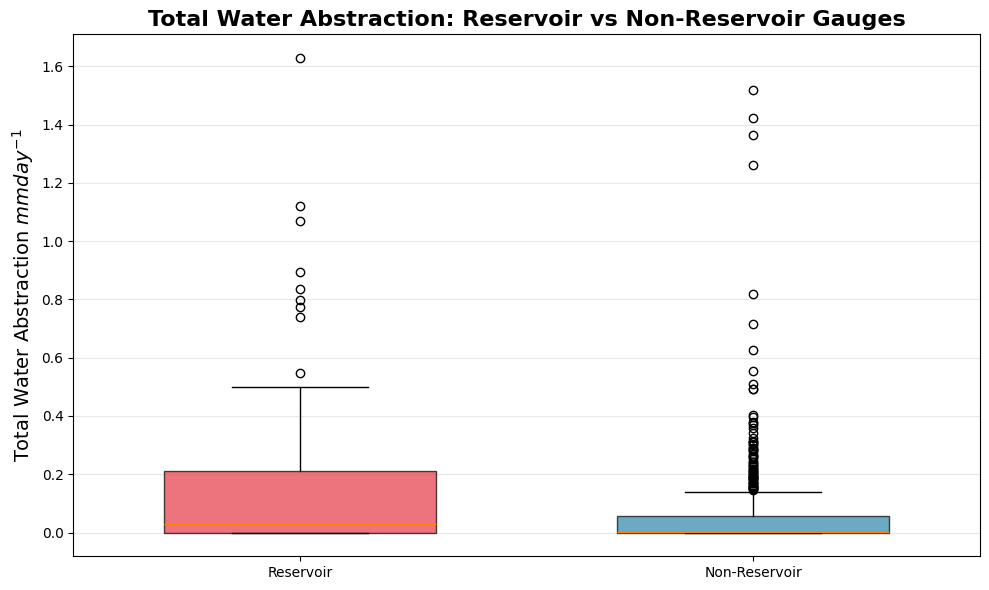

In [48]:
# 1. BOXPLOT: stream_elas comparison
fig, ax = plt.subplots(figsize=(10, 6))
non_reservoir_gauges = gdf_gauges[gdf_gauges["reservoir_contributing_area"] == 0].copy()


variable = 'stream_elas' # 'stream_elas', 'surfacewater_abs', 'groundwater_abs' 
# data_to_plot = [
#     res_static[f'{variable}'].dropna(),
#     nonres_static[f'{variable}'].dropna()
# ]

# data_to_plot = [
#     res_static['surfacewater_abs'].dropna() + res_static['groundwater_abs'].dropna(),
#     nonres_static['surfacewater_abs'].dropna() + nonres_static['groundwater_abs'].dropna()
# ]

data_to_plot = [
    reservoir_gauges['surfacewater_abs'].dropna() + reservoir_gauges['groundwater_abs'].dropna(),
    non_reservoir_gauges['surfacewater_abs'].dropna() + non_reservoir_gauges['groundwater_abs'].dropna()
]

bp = ax.boxplot(data_to_plot, 
                labels=['Reservoir', 'Non-Reservoir'],
                patch_artist=True,
                widths=0.6)

# Color the boxes
colors = ['#E63946', '#2E86AB']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_ylabel('Total Water Abstraction $mmday^{-1}$', fontsize=14)
ax.set_title('Total Water Abstraction: Reservoir vs Non-Reservoir Gauges', fontsize=16, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
#plt.savefig('surfacewater_abs_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# # Print summary statistics
# print("\nStreamflow Elasticity Statistics:")
# print(f"Reservoir - Mean: {res_static[f'{variable}'].mean():.3f}, Median: {res_static[f'{variable}'].median():.3f}")
# print(f"Non-Reservoir - Mean: {nonres_static[f'{variable}'].mean():.3f}, Median: {nonres_static[f'{variable}'].median():.3f}")

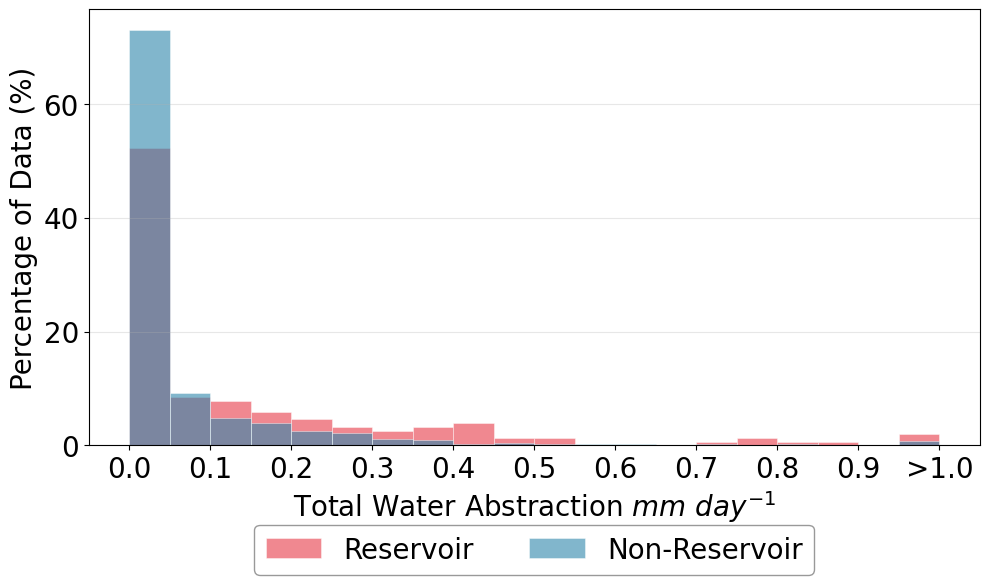

In [49]:
# ── Editable parameters ────────────────────────────────────────────────────────
FONT_SIZE       = 20
BIN_WIDTH       = 0.05
CLIP_MAX        = 1.0         # values above this are grouped into a final overflow bin
ALPHA           = 0.6
COLORS          = ['#E63946', '#2E86AB']
LABELS          = ['Reservoir', 'Non-Reservoir']
YLABEL          = r'Percentage of Data (%)'
XLABEL          = r'Total Water Abstraction $mm\ day^{-1}$'
FIG_SIZE        = (10, 6)
LEGEND_LOC      = 'upper right'
# ──────────────────────────────────────────────────────────────────────────────

non_reservoir_gauges = gdf_gauges[gdf_gauges["reservoir_contributing_area"] == 0].copy()

data_to_plot = [
    reservoir_gauges['surfacewater_abs'].dropna() + reservoir_gauges['groundwater_abs'].dropna(),
    non_reservoir_gauges['surfacewater_abs'].dropna() + non_reservoir_gauges['groundwater_abs'].dropna()
]

all_data  = pd.concat(data_to_plot)
bin_edges = np.arange(all_data.min(), CLIP_MAX + BIN_WIDTH, BIN_WIDTH)

fig, ax = plt.subplots(figsize=FIG_SIZE)

for data, color, label in zip(data_to_plot, COLORS, LABELS):
    clipped = data.clip(upper=CLIP_MAX)
    counts, _ = np.histogram(clipped, bins=bin_edges)
    percentages = counts / len(data) * 100
    ax.bar(bin_edges[:-1], percentages, width=BIN_WIDTH,
           align='edge', color=color, alpha=ALPHA,
           label=label, edgecolor='white', linewidth=0.5)

# Only label a sensible number of ticks, replacing the last one with ">CLIP_MAX"
tick_step    = int(len(bin_edges) / 10) or 1          # ~10 ticks across the axis
tick_indices = list(range(0, len(bin_edges) - 1, tick_step)) + [len(bin_edges) - 1]
tick_pos     = bin_edges[tick_indices]
tick_labels  = [f'{v:.1f}' for v in tick_pos]
tick_labels[-1] = f'>{CLIP_MAX}'

ax.set_xticks(tick_pos)
ax.set_xticklabels(tick_labels, fontsize=FONT_SIZE)

ax.set_xlabel(XLABEL, fontsize=FONT_SIZE)
ax.set_ylabel(YLABEL, fontsize=FONT_SIZE)
ax.tick_params(axis='both', labelsize=FONT_SIZE)

ax.legend(fontsize=FONT_SIZE, loc='upper center',
          bbox_to_anchor=(0.5, -0.15), ncol=2,
          frameon=True, edgecolor='grey')

plt.tight_layout()
plt.subplots_adjust(bottom=0.2)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
# plt.savefig('water_abstraction_histogram.png', dpi=300, bbox_inches='tight')
plt.show()

In [50]:
nonres_static[['gauge_id', 'surfacewater_abs', 'groundwater_abs']].sort_values(by='surfacewater_abs', ascending=False)

with pd.option_context('display.max_columns', None):
    print(All_Static_Variables[All_Static_Variables['gauge_id'] == 27038])

     gauge_id  inter_high_perc  inter_mod_perc  inter_low_perc  \
144   27038.0              0.0            4.37             0.0   

     frac_high_perc  frac_mod_perc  frac_low_perc  no_gw_perc  low_nsig_perc  \
144             0.0           68.2            0.0       27.43            0.0   

     nsig_low_perc benchmark_catch  surfacewater_abs  groundwater_abs  \
144            0.0               N             0.935            0.583   

     discharges  abs_agriculture_perc  abs_amenities_perc  abs_energy_perc  \
144         0.0                 61.59                 0.0              0.0   

     abs_environmental_perc  abs_industry_perc  abs_watersupply_perc  \
144                     0.0                0.0                 38.41   

     abs_highloss_perc  abs_mediumloss_perc  abs_lowloss_perc  \
144                0.0                38.41               0.0   

     abs_verylowloss_perc  num_reservoir  reservoir_cap  \
144                 61.59            0.0            0.0   

     re

In [51]:

with open(
    "/home/mokr/Reservoir_Modelling/Sample_Pairs/1203_catchment_date_pairs_splits.pkl", "rb"
) as f:
    catchment_splits = pickle.load(f)


In [52]:
# Want to know where 27038 is

catchment_splits['non_reservoir_test'][0]['gauge_id']

[key for key, items in catchment_splits.items() if any(item['gauge_id'] == '27038' for item in items)]

[]

In [55]:
# Calculate average soil percentages for each group
soil_columns = ['sand_perc', 'silt_perc', 'clay_perc', 'organic_perc']

res_soil_avg = res_static[soil_columns].mean()
nonres_soil_avg = nonres_static[soil_columns].mean()

# Rename for cleaner labels
soil_labels = ['Sand', 'Silt', 'Clay', 'Organic']
res_soil_avg.index = soil_labels
nonres_soil_avg.index = soil_labels

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Color mapping
colors_soil = {'Sand': '#F4A460', 'Silt': '#D2B48C', 'Clay': '#8B4513', 'Organic': '#2F4F2F'}
pie_colors = [colors_soil[soil] for soil in soil_labels]

# Reservoir soil composition
axes[0].pie(res_soil_avg.values, 
            labels=res_soil_avg.index, 
            autopct='%1.1f%%',
            startangle=90,
            colors=pie_colors)
axes[0].set_title(f'Average Soil Composition - Reservoir\n(n={len(res_static)})', 
                  fontsize=14, fontweight='bold')

# Non-reservoir soil composition
axes[1].pie(nonres_soil_avg.values, 
            labels=nonres_soil_avg.index, 
            autopct='%1.1f%%',
            startangle=90,
            colors=pie_colors)
axes[1].set_title(f'Average Soil Composition - Non-Reservoir\n(n={len(nonres_static)})', 
                  fontsize=14, fontweight='bold')

plt.tight_layout()
#plt.savefig('soil_composition_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Print detailed statistics
print("\nAverage Soil Composition:")
print("\nReservoir:")
for soil, pct in res_soil_avg.items():
    print(f"  {soil}: {pct:.2f}%")
print(f"  Total: {res_soil_avg.sum():.2f}%")

print("\nNon-Reservoir:")
for soil, pct in nonres_soil_avg.items():
    print(f"  {soil}: {pct:.2f}%")
print(f"  Total: {nonres_soil_avg.sum():.2f}%")

# Optional: Create a side-by-side bar chart for easier comparison
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(soil_labels))
width = 0.35

bars1 = ax.bar(x - width/2, res_soil_avg.values, width, 
               label='Reservoir', color='#E63946', alpha=0.8)
bars2 = ax.bar(x + width/2, nonres_soil_avg.values, width, 
               label='Non-Reservoir', color='#2E86AB', alpha=0.8)

ax.set_ylabel('Average Percentage (%)', fontsize=14)
ax.set_title('Average Soil Composition Comparison', fontsize=16, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(soil_labels, fontsize=12)
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}%',
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
#plt.savefig('soil_composition_bar_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

ValueError: cannot convert float NaN to integer

ValueError: need at least one array to concatenate

<Figure size 1400x600 with 2 Axes>

In [56]:
# Calculate average land cover percentages for each group

year = 2022
landcover_columns = [f'dwood_perc_{year}', f'ewood_perc_{year}', f'grass_perc_{year}', f'shrub_perc_{year}', 
                     f'crop_perc_{year}', f'urban_perc_{year}', f'inwater_perc_{year}', f'bares_perc_{year}']

res_landcover_avg = res_static[landcover_columns].mean()
nonres_landcover_avg = nonres_static[landcover_columns].mean()

# Rename for cleaner labels
landcover_labels = ['Deciduous Wood', 'Evergreen Wood', 'Grass', 'Shrub', 
                    'Crop', 'Urban', 'Inland Water', 'Bare Soil']
res_landcover_avg.index = landcover_labels
nonres_landcover_avg.index = landcover_labels

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Color mapping for land cover types
colors_landcover = {
    'Deciduous Wood': '#90EE90',
    'Evergreen Wood': '#228B22',
    'Grass': '#9ACD32',
    'Shrub': '#6B8E23',
    'Crop': '#FFD700',
    'Urban': '#808080',
    'Inland Water': '#4682B4',
    'Bare Soil': '#D2691E'
}
pie_colors = [colors_landcover[lc] for lc in landcover_labels]

# Reservoir land cover composition
axes[0].pie(res_landcover_avg.values, 
            labels=res_landcover_avg.index, 
            autopct='%1.1f%%',
            startangle=90,
            colors=pie_colors)
axes[0].set_title(f'Average Land Cover Composition - Reservoir\n(n={len(res_static)})', 
                  fontsize=14, fontweight='bold')

# Non-reservoir land cover composition
axes[1].pie(nonres_landcover_avg.values, 
            labels=nonres_landcover_avg.index, 
            autopct='%1.1f%%',
            startangle=90,
            colors=pie_colors)
axes[1].set_title(f'Average Land Cover Composition - Non-Reservoir\n(n={len(nonres_static)})', 
                  fontsize=14, fontweight='bold')

plt.tight_layout()
#plt.savefig('landcover_composition_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Print detailed statistics
print("\nAverage Land Cover Composition:")
print("\nReservoir:")
for lc, pct in res_landcover_avg.items():
    print(f"  {lc}: {pct:.2f}%")
print(f"  Total: {res_landcover_avg.sum():.2f}%")

print("\nNon-Reservoir:")
for lc, pct in nonres_landcover_avg.items():
    print(f"  {lc}: {pct:.2f}%")
print(f"  Total: {nonres_landcover_avg.sum():.2f}%")

# Side-by-side bar chart for easier comparison
fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(landcover_labels))
width = 0.35

bars1 = ax.bar(x - width/2, res_landcover_avg.values, width, 
               label='Reservoir', color='#E63946', alpha=0.8)
bars2 = ax.bar(x + width/2, nonres_landcover_avg.values, width, 
               label='Non-Reservoir', color='#2E86AB', alpha=0.8)

ax.set_ylabel('Average Percentage (%)', fontsize=14)
ax.set_title('Average Land Cover Composition Comparison', fontsize=16, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(landcover_labels, fontsize=11, rotation=45, ha='right')
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        if height > 0.5:  # Only show label if percentage is > 0.5%
            ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.1f}%',
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
#plt.savefig('landcover_composition_bar_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Optional: Show only significant land cover types (>5% in either group)
significant_threshold = 5.0
significant_types = res_landcover_avg[
    (res_landcover_avg > significant_threshold) | 
    (nonres_landcover_avg > significant_threshold)
].index

if len(significant_types) > 0:
    fig, ax = plt.subplots(figsize=(12, 6))
    
    x = np.arange(len(significant_types))
    width = 0.35
    
    res_sig = res_landcover_avg[significant_types]
    nonres_sig = nonres_landcover_avg[significant_types]
    
    bars1 = ax.bar(x - width/2, res_sig.values, width, 
                   label='Reservoir', color='#E63946', alpha=0.8)
    bars2 = ax.bar(x + width/2, nonres_sig.values, width, 
                   label='Non-Reservoir', color='#2E86AB', alpha=0.8)
    
    ax.set_ylabel('Average Percentage (%)', fontsize=14)
    ax.set_title(f'Major Land Cover Types (>{significant_threshold}% in either group)', 
                 fontsize=16, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(significant_types, fontsize=12, rotation=45, ha='right')
    ax.legend(fontsize=12)
    ax.grid(True, alpha=0.3, axis='y')
    
    # Add value labels on bars
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.1f}%',
                    ha='center', va='bottom', fontsize=10)
    
    plt.tight_layout()
    #plt.savefig('landcover_major_types_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()

ValueError: cannot convert float NaN to integer

ValueError: need at least one array to concatenate

<Figure size 1600x700 with 2 Axes>

# Dates of Available data for each pair

In [57]:
import torch

train_res_tensor_metadata = torch.load(
    "/perm/mokr/CamelsGB_V2/train_res_tensor_metadata.pt"
)

val_res_tensor_metadata = torch.load(
    "/perm/mokr/CamelsGB_V2/val_res_tensor_metadata.pt"
)


test_res_tensor_metadata = torch.load(
    "/perm/mokr/CamelsGB_V2/test_res_tensor_metadata.pt"
)

# res_by_split

In [58]:
def make_gauge_dates_summary(metadata, split_name):
    df = pd.DataFrame({
        'gauge_id': metadata['gauge_id'],
        'init_date': metadata['init_date']
    })
    return (
        df.groupby('gauge_id', sort=False)['init_date']
        .agg(first_date='first', last_date='last')
        .reset_index()
        .assign(split=split_name)
    )

gauge_dates_summary = pd.concat([
    make_gauge_dates_summary(train_res_tensor_metadata, 'train'),
    make_gauge_dates_summary(val_res_tensor_metadata,   'val'),
    make_gauge_dates_summary(test_res_tensor_metadata,  'test'),
]).reset_index(drop=True)

gauge_dates_summary

,gauge_id,first_date,last_date,split
0,48011,1984-01-01 00:00:00,2015-07-03 00:00:00,train
1,47001,1990-01-01 00:00:00,2015-07-03 00:00:00,train
2,46014,2004-02-17 00:00:00,2015-07-02 00:00:00,train
3,47008,1990-01-01 00:00:00,2015-07-02 00:00:00,train
4,45001,1980-01-01 00:00:00,1994-11-08 00:00:00,train
...,...,...,...,...
144,16001,1972-01-09 00:00:00,2015-07-02 00:00:00,test
145,16004,1997-02-05 00:00:00,2015-07-02 00:00:00,test
146,8005,1970-10-01 00:00:00,2015-07-03 00:00:00,test
147,8006,1985-01-01 00:00:00,2015-07-02 00:00:00,test


In [59]:
res_gdf

,gauge_id,gauge_name,split,geometry,type,pair_id,source,set_id
0,48011,Fowey at Restormel,val,POINT (209757.32 62339.436),reservoir,0,res,21
1,47011,Plym at Carn Wood,train,POINT (252366.207 60974.397),reservoir,1,res,56
2,47001,Tamar at Gunnislake,train,POINT (242756.333 72380.038),reservoir,2,res,16
3,46014,Teign at Chudleigh,val,POINT (285447.595 79062.837),reservoir,3,res,57
4,47008,Thrushel at Tinhay,train,POINT (239621.533 85828.887),reservoir,4,res,16
...,...,...,...,...,...,...,...,...
148,4001,Conon at Moy Bridge,train,POINT (248141.129 855057.844),reservoir,148,res,29
149,7003,Lossie at Sheriffmills,train,POINT (319525.259 863035.543),reservoir,149,res,26
150,2001,Helmsdale at Kilphedir,train,POINT (300010.089 918048.787),reservoir,150,res,44
151,1001,Wick at Tarroul,train,POINT (326039.003 955343.325),reservoir,151,res,36


/etc/ecmwf/ssd/ssd1/jupyterhub/mokr-jupyterhub/tmpdirs/mokr.27833902/ipykernel_3655777/350116120.py:46: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  absent  = mpatches.Patch(color='white', edgecolor='grey', label='No data')


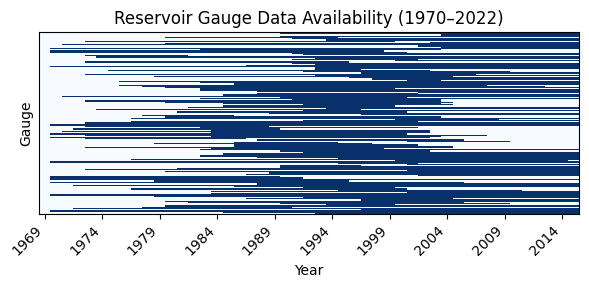

In [60]:
import matplotlib.patches as mpatches

# Build a year-level availability matrix
years = np.arange(1969, 2016)
gauge_ids = res_gdf['gauge_id'].values
gauge_ids = gauge_dates_summary['gauge_id'].astype(str).tolist()

# Map each gauge to its available year range from gauge_dates_summary
availability = pd.DataFrame(0, index=gauge_ids, columns=years)

for _, row in gauge_dates_summary[gauge_dates_summary['gauge_id'].isin(gauge_ids)].iterrows():
    gid = row['gauge_id']
    if gid not in availability.index:
        continue
    y_start = pd.to_datetime(row['first_date']).year
    y_end   = pd.to_datetime(row['last_date']).year
    availability.loc[gid, y_start:y_end] = 1

# --- Plot ---
fig, ax = plt.subplots(figsize=(6, len(gauge_ids) * 0.02))

im = ax.imshow(
    availability.values,
    aspect='auto',
    cmap='Blues',
    vmin=0, vmax=1,
    interpolation='none'
)

# Axes labels
# ax.set_yticks(range(len(gauge_ids)))
ax.set_yticks([])

# ax.set_yticklabels(gauge_ids, fontsize=7)

year_ticks = np.arange(0, len(years), 5)
ax.set_xticks(year_ticks)
ax.set_xticklabels(years[year_ticks], rotation=45, ha='right')

ax.set_xlabel("Year")
ax.set_ylabel("Gauge")
ax.set_title("Reservoir Gauge Data Availability (1970–2022)")

# Legend
present = mpatches.Patch(color='steelblue', label='Data present')
absent  = mpatches.Patch(color='white', edgecolor='grey', label='No data')
# ax.legend(handles=[present, absent], loc='lower right', framealpha=0.9)

plt.tight_layout()
plt.show()

# Multiplot for paper

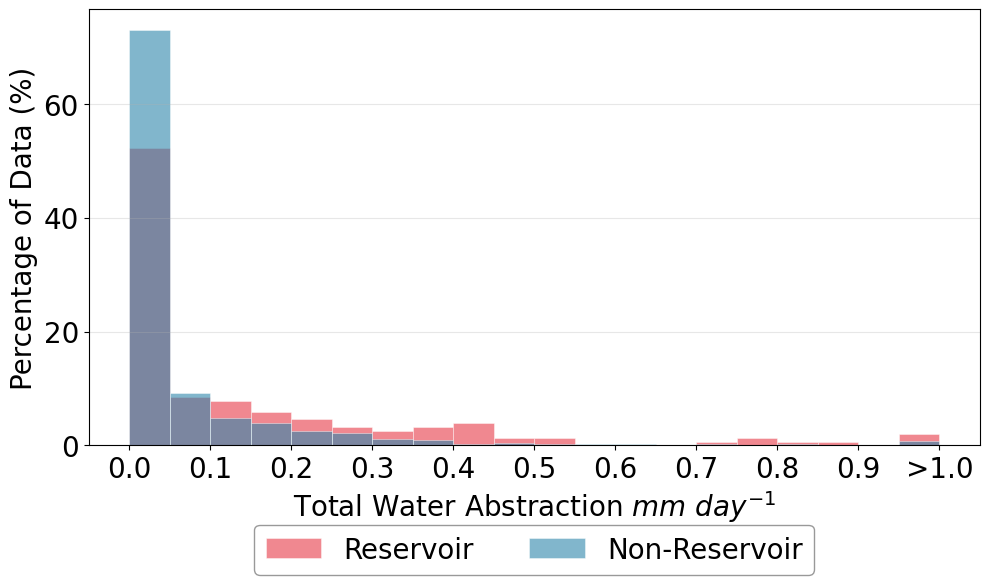

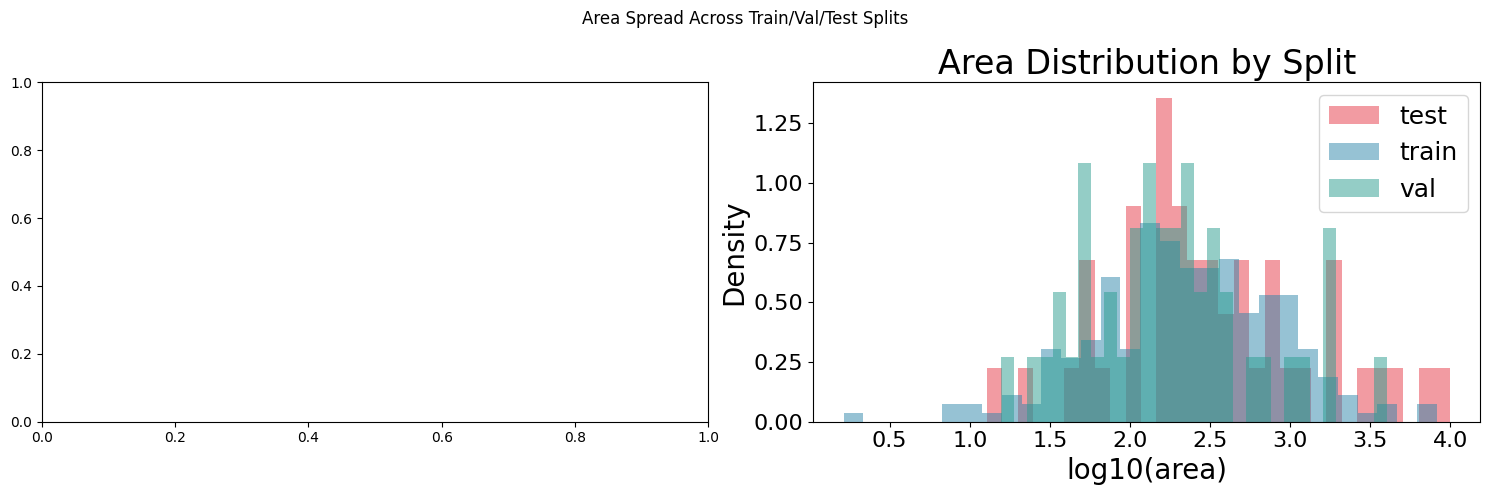

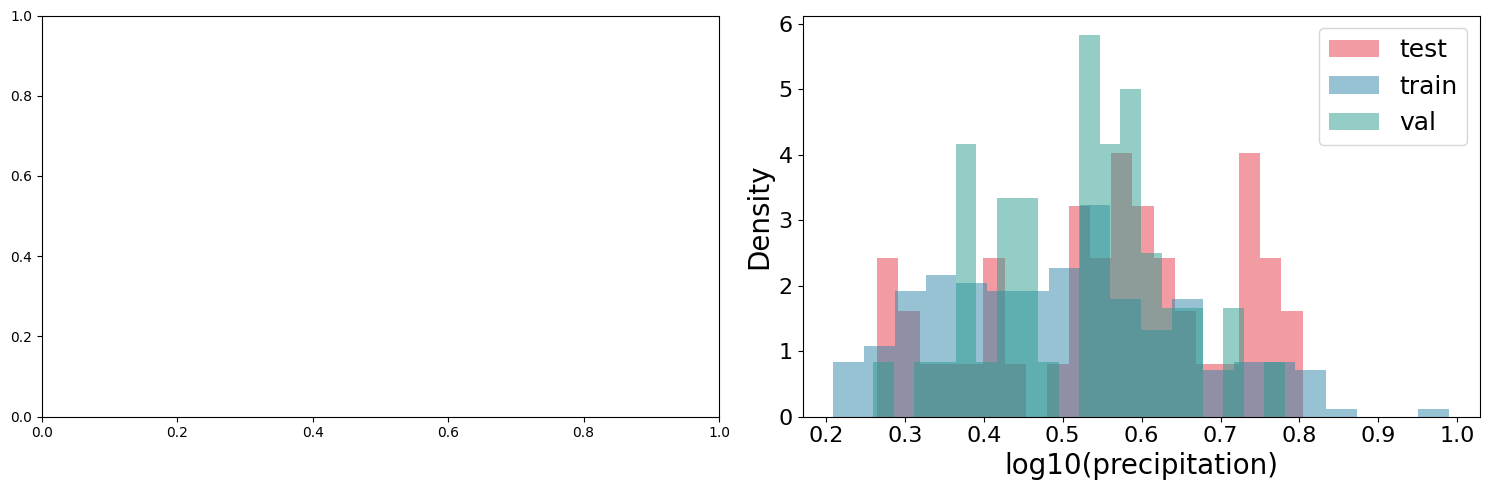

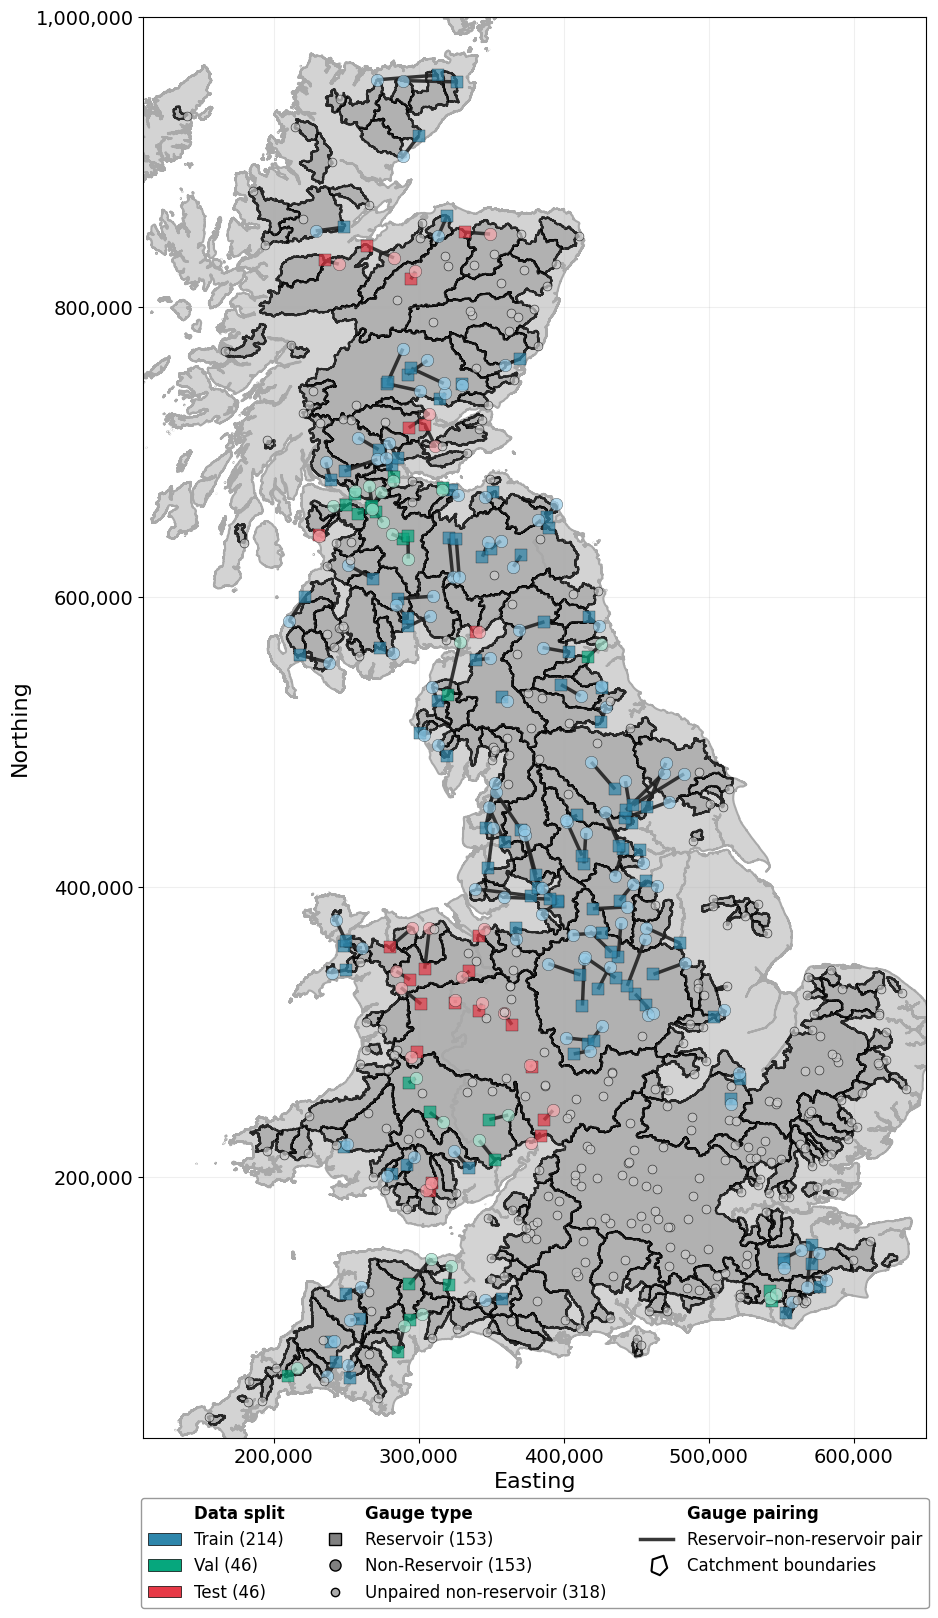

/etc/ecmwf/ssd/ssd1/jupyterhub/mokr-jupyterhub/tmpdirs/mokr.27833902/ipykernel_3655777/3477558463.py:310: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  absent  = mpatches.Patch(color='white', edgecolor='grey', label='No data')


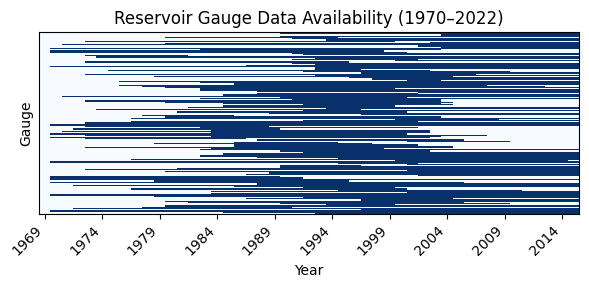

In [61]:
# ── Editable parameters ────────────────────────────────────────────────────────
FONT_SIZE       = 20
BIN_WIDTH       = 0.05
CLIP_MAX        = 1.0         # values above this are grouped into a final overflow bin
ALPHA           = 0.6
COLORS          = ['#E63946', '#2E86AB']
LABELS          = ['Reservoir', 'Non-Reservoir']
YLABEL          = r'Percentage of Data (%)'
XLABEL          = r'Total Water Abstraction $mm\ day^{-1}$'
FIG_SIZE        = (10, 6)
LEGEND_LOC      = 'upper right'
# ──────────────────────────────────────────────────────────────────────────────

non_reservoir_gauges = gdf_gauges[gdf_gauges["reservoir_contributing_area"] == 0].copy()

data_to_plot = [
    reservoir_gauges['surfacewater_abs'].dropna() + reservoir_gauges['groundwater_abs'].dropna(),
    non_reservoir_gauges['surfacewater_abs'].dropna() + non_reservoir_gauges['groundwater_abs'].dropna()
]

all_data  = pd.concat(data_to_plot)
bin_edges = np.arange(all_data.min(), CLIP_MAX + BIN_WIDTH, BIN_WIDTH)

fig, ax = plt.subplots(figsize=FIG_SIZE)

for data, color, label in zip(data_to_plot, COLORS, LABELS):
    clipped = data.clip(upper=CLIP_MAX)
    counts, _ = np.histogram(clipped, bins=bin_edges)
    percentages = counts / len(data) * 100
    ax.bar(bin_edges[:-1], percentages, width=BIN_WIDTH,
           align='edge', color=color, alpha=ALPHA,
           label=label, edgecolor='white', linewidth=0.5)

# Only label a sensible number of ticks, replacing the last one with ">CLIP_MAX"
tick_step    = int(len(bin_edges) / 10) or 1          # ~10 ticks across the axis
tick_indices = list(range(0, len(bin_edges) - 1, tick_step)) + [len(bin_edges) - 1]
tick_pos     = bin_edges[tick_indices]
tick_labels  = [f'{v:.1f}' for v in tick_pos]
tick_labels[-1] = f'>{CLIP_MAX}'

ax.set_xticks(tick_pos)
ax.set_xticklabels(tick_labels, fontsize=FONT_SIZE)

ax.set_xlabel(XLABEL, fontsize=FONT_SIZE)
ax.set_ylabel(YLABEL, fontsize=FONT_SIZE)
ax.tick_params(axis='both', labelsize=FONT_SIZE)

ax.legend(fontsize=FONT_SIZE, loc='upper center',
          bbox_to_anchor=(0.5, -0.15), ncol=2,
          frameon=True, edgecolor='grey')

plt.tight_layout()
plt.subplots_adjust(bottom=0.2)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
# plt.savefig('water_abstraction_histogram.png', dpi=300, bbox_inches='tight')
plt.show()



TITLE_SIZE = 24
LABEL_FONT = 20
TICK_SIZE = 16
LEGEND_FONT = 18
### Spread of Area

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
split_colors = {'train': '#2E86AB', 'val': '#2A9D8F', 'test': '#E63946'}
split_order = ['train', 'val', 'test']

# Option B: Overlapping histograms / KDE
for split, grp in all_gdf_static.groupby('split'):
    axes[1].hist(np.log10(grp['area'].dropna()), bins=30, alpha=0.5, label=split, density=True, color=split_colors[split])
axes[1].set_xlabel('log10(area)', fontsize=LABEL_FONT)
axes[1].set_ylabel('Density', fontsize=LABEL_FONT)
axes[1].set_title('Area Distribution by Split', fontsize = TITLE_SIZE)
axes[1].tick_params(axis="both", labelsize=TICK_SIZE)
axes[1].legend(fontsize=LEGEND_FONT)

plt.suptitle('Area Spread Across Train/Val/Test Splits')
plt.tight_layout()
plt.show()


### Spread of Precipitation

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Option B: Overlapping histograms / KDE
for split, grp in all_gdf_static.groupby('split'):
    axes[1].hist(np.log10(grp['p_mean'].dropna()), bins=20, alpha=0.5, label=split, density=True, color=split_colors[split])
axes[1].set_xlabel('log10(precipitation)', fontsize=LABEL_FONT)
axes[1].set_ylabel('Density', fontsize=LABEL_FONT)
# axes[1].set_title('Precipitation Distribution by Split', fontsize = TITLE_SIZE)
axes[1].tick_params(axis="both", labelsize=TICK_SIZE)
axes[1].legend(fontsize=LEGEND_FONT)


# plt.suptitle('Precipitation Spread Across Train/Val/Test Splits')
plt.tight_layout()
plt.show()


import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.path as mpath
import geopandas as gpd
import numpy as np
import time

# --- Define split and nonres_gdf ---
splits = ["train", "val", "test"]
res_by_split = {s: res_gdf[res_gdf["split"] == s] for s in splits}
nonres_by_split = {s: nonres_gdf[nonres_gdf["split"] == s] for s in splits}
res_coords = res_gdf.geometry.values
nonres_coords = nonres_gdf.geometry.values
res_splits = res_gdf["split"].values

# ── Updated Color Definitions ──────────────────────────────────────────
# 1. Your original "base" colors, which we will use for Reservoir gauges (squares)
split_colors_res = {"train": "#2E86AB", "val": "#06A77D", "test": "#E63946"}

# 2. Corresponding lighter hues of the same colors for Non-Reservoir gauges (circles)
split_colors_light = {"train": "#97CEEB", "val": "#A6E7D2", "test": "#F7A8AE"}
# ───────────────────────────────────────────────────────────────────────

MARKER_SIZE = 80
UNPAIRED_SIZE = 40
LINE_WIDTH = 2.5
LINE_COLOR = '#222222'
LINE_ALPHA = 0.9
ALPHA = 0.7
TITLE_FONT = 18
LABEL_FONT = 16
LEGEND_FONT = 12
TICK_SIZE = 14

t_total = time.time()

# ── Figure with extra top margin for the legend ────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 16))
fig.subplots_adjust(top=0.85)

# UK boundary
uk_boundary_filtered.plot(ax=ax, color="lightgray", edgecolor="darkgray", linewidth=1.5)

# Catchments
catchments_gdf.plot(ax=ax, color="darkgray", edgecolor="black", linewidth=1.5, alpha=0.8)

# ── Gauge scatter with updated color logic ──────────────────────
for split in splits:
    # 3. Iterate through types and markers, including a type name ('res' or 'nonres')
    for gdf, marker, type_name in [
        (res_by_split[split], "s", "res"),       # Reservoir -> Square
        (nonres_by_split[split], "o", "nonres") # Non-Reservoir -> Circle
    ]:
        # 4. Use the correct color dictionary based on the gauge type
        color_dict = split_colors_res if type_name == "res" else split_colors_light
        
        ax.scatter(gdf.geometry.x.values, gdf.geometry.y.values,
                    c=color_dict[split], # ← Use the updated, distinct color
                    s=MARKER_SIZE, alpha=ALPHA,
                    edgecolors="black", linewidths=0.3, marker=marker, zorder=3)
# ──────────────────────────────────────────────────────────────────

# Pair lines — single dark colour so they stand out against the basemap
for split in splits:
    mask = res_splits == split
    xs_res = np.array([g.x for g in res_coords[mask]])
    ys_res = np.array([g.y for g in res_coords[mask]])
    xs_nonres = np.array([g.x for g in nonres_coords[mask]])
    ys_nonres = np.array([g.y for g in nonres_coords[mask]])
    segments = np.stack([np.column_stack([xs_res, ys_res]),
                          np.column_stack([xs_nonres, ys_nonres])], axis=1)
    lc = LineCollection(segments, colors=LINE_COLOR,
                        alpha=LINE_ALPHA, linewidths=LINE_WIDTH, zorder=2)
    ax.add_collection(lc)

# Unpaired gauges — use a visible grey instead of white
unpaired_non_reservoir.plot(ax=ax, color="#CCCCCC", markersize=UNPAIRED_SIZE, alpha=0.7,
                             edgecolor="black", linewidth=0.5, zorder=3)

# ── Axes formatting ────────────────────────────────────────────────────────────
ax.set_xlabel("Easting", fontsize=LABEL_FONT)
ax.set_ylabel("Northing", fontsize=LABEL_FONT)
ax.set_aspect("equal")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_xlim(110_000, 650_000)
ax.set_ylim(20_000, 1_000_000)
ax.tick_params(axis="both", labelsize=TICK_SIZE)
ax.grid(True, alpha=0.2)

# ── Custom 3-column legend placed at the top ─────────────────────────────────

# 1. Column 1 items: Data Split (Showing the base/reservoir color)
split_handles = [
    Patch(facecolor=split_colors_res[s], edgecolor="black", linewidth=0.5,
          label=f"{s.capitalize()} ({len(res_by_split[s])+len(nonres_by_split[s])})")
    for s in splits
]

# 2. Column 2 items: Gauge Type (With generic placeholders)
total_res = len(res_gdf)
total_nonres = len(nonres_gdf)
total_unpaired = len(unpaired_non_reservoir)

type_handles = [
    Line2D([0], [0], marker="s", color="none", markerfacecolor="grey",
            markeredgecolor="black", markersize=8, label=f"Reservoir ({total_res})"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="grey",
            markeredgecolor="black", markersize=8, label=f"Non-Reservoir ({total_nonres})"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#AAAAAA",
            markeredgecolor="black", markersize=6, label=f"Unpaired non-reservoir ({total_unpaired})"),
]

# 3. Column 3 items: Gauge Pairing & Boundaries
# Create an irregular, "wonky" polygon path to represent a catchment shape
catchment_verts = [[-0.5, -0.5], [0.2, -0.8], [0.8, -0.2], [0.5, 0.8], [-0.4, 0.5], [-0.5, -0.5]]
catchment_path = mpath.Path(catchment_verts)

pairing_handles = [
    Line2D([0], [0], color=LINE_COLOR, linewidth=LINE_WIDTH, alpha=LINE_ALPHA,
           label="Reservoir–non-reservoir pair"),
    Line2D([0], [0], marker=catchment_path, color="none", markeredgecolor="black", 
           markerfacecolor="none", markersize=14, markeredgewidth=1.5, 
           label="Catchment boundaries")
]

# Blank handle helper used for bold section titles and empty spacing
def section_title(text):
    return Patch(color="none", label=text)

# --- Force the layout row-by-row for a 3-column grid ---
all_handles_horizontal = [
    section_title("Data split"),    split_handles[0],   split_handles[1],   split_handles[2],
    section_title("Gauge type"),    type_handles[0],    type_handles[1],    type_handles[2],
    section_title("Gauge pairing"), pairing_handles[0], pairing_handles[1], section_title("")
]

leg = ax.legend(
    handles=all_handles_horizontal,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    borderaxespad=0,
    frameon=True,
    edgecolor="grey",
    fontsize=LEGEND_FONT,
)

# Make the section-title entries bold and hide their blank handles
for text, handle in zip(leg.get_texts(), leg.legend_handles):
    if text.get_text() in ("Data split", "Gauge type", "Gauge pairing", ""):
        text.set_fontweight("bold")
        handle.set_visible(False)   

plt.tight_layout()
plt.show()


import matplotlib.patches as mpatches

# Build a year-level availability matrix
years = np.arange(1969, 2016)
gauge_ids = res_gdf['gauge_id'].values
gauge_ids = gauge_dates_summary['gauge_id'].astype(str).tolist()

# Map each gauge to its available year range from gauge_dates_summary
availability = pd.DataFrame(0, index=gauge_ids, columns=years)

for _, row in gauge_dates_summary[gauge_dates_summary['gauge_id'].isin(gauge_ids)].iterrows():
    gid = row['gauge_id']
    if gid not in availability.index:
        continue
    y_start = pd.to_datetime(row['first_date']).year
    y_end   = pd.to_datetime(row['last_date']).year
    availability.loc[gid, y_start:y_end] = 1

# --- Plot ---
fig, ax = plt.subplots(figsize=(6, len(gauge_ids) * 0.02))

im = ax.imshow(
    availability.values,
    aspect='auto',
    cmap='Blues',
    vmin=0, vmax=1,
    interpolation='none'
)

# Axes labels
# ax.set_yticks(range(len(gauge_ids)))
ax.set_yticks([])

# ax.set_yticklabels(gauge_ids, fontsize=7)

year_ticks = np.arange(0, len(years), 5)
ax.set_xticks(year_ticks)
ax.set_xticklabels(years[year_ticks], rotation=45, ha='right')

ax.set_xlabel("Year")
ax.set_ylabel("Gauge")
ax.set_title("Reservoir Gauge Data Availability (1970–2022)")

# Legend
present = mpatches.Patch(color='steelblue', label='Data present')
absent  = mpatches.Patch(color='white', edgecolor='grey', label='No data')
# ax.legend(handles=[present, absent], loc='lower right', framealpha=0.9)

plt.tight_layout()
plt.show()

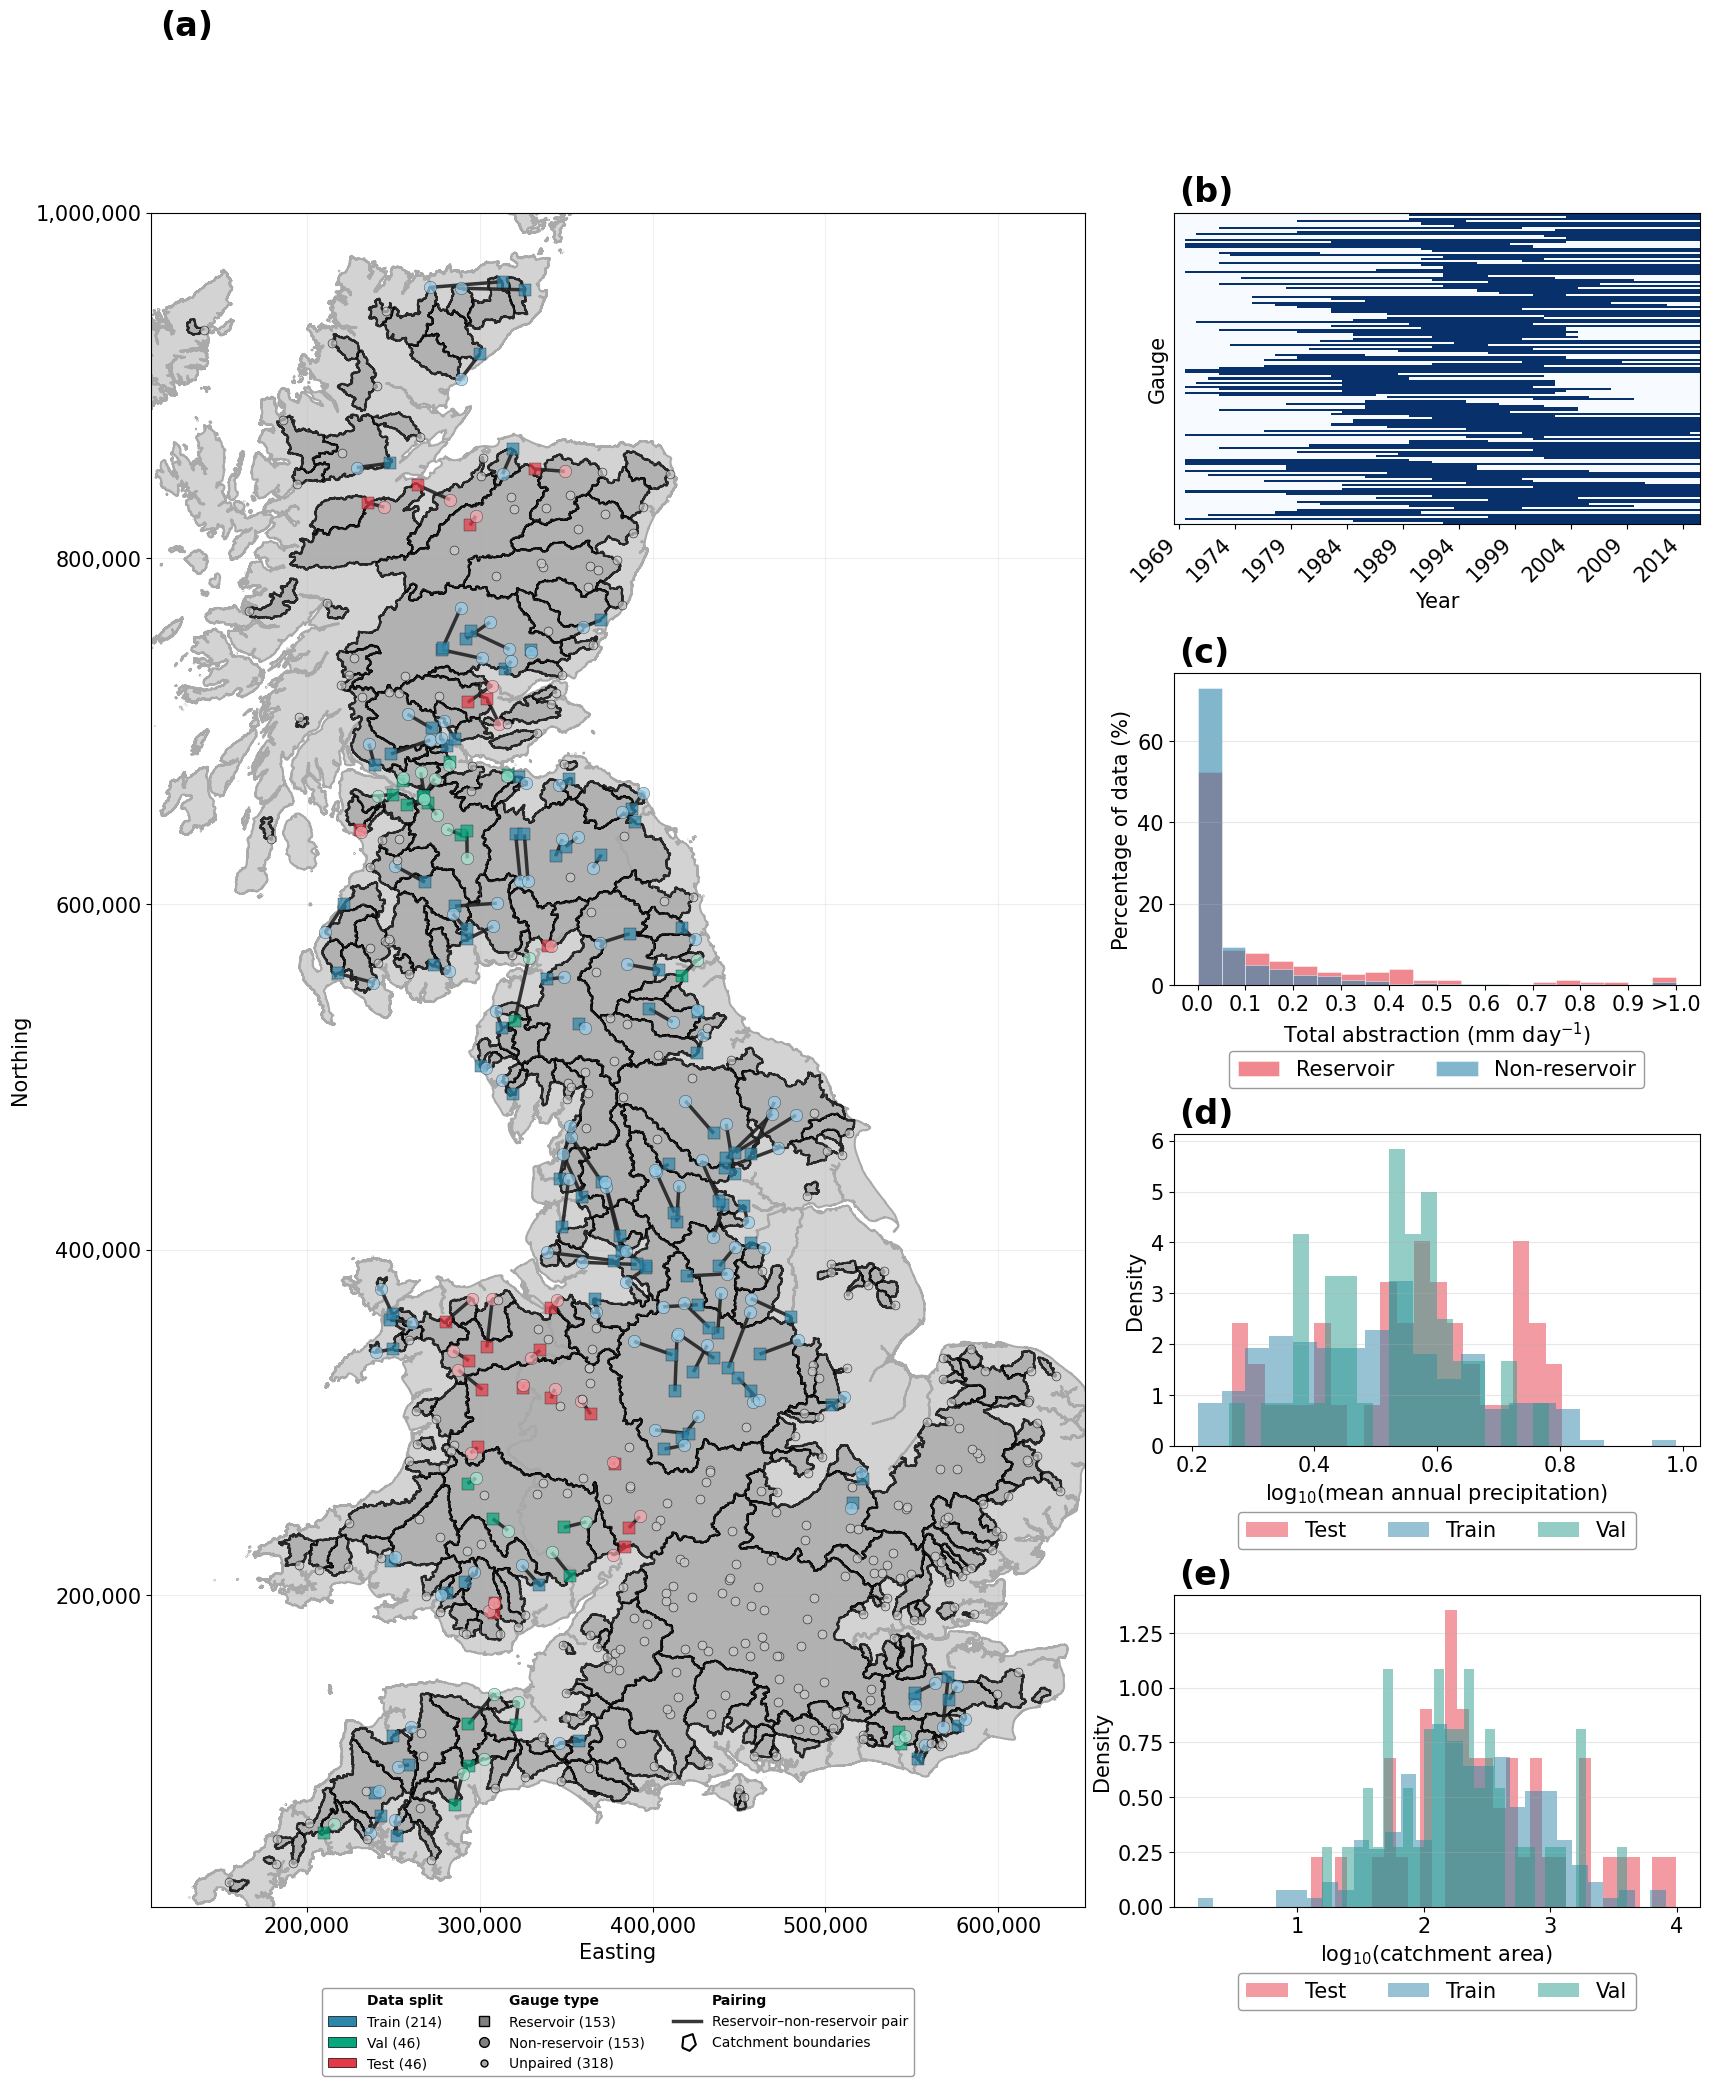

In [62]:
"""
Combined 5-panel figure — drop-in replacement for the LaTeX minipage layout.

Layout
------
Left  (62 %) : (a) Map
Right (38 %) : (b) Data availability
               (c) Water abstraction
               (d) Precipitation distribution
               (e) Area distribution
"""

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.path as mpath
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

# ── Shared right-column font sizes ────────────────────────────────────────────
RF  = 15   # axis labels, tick labels
RLF = RF   # legend


# ── Figure & GridSpec ─────────────────────────────────────────────────────────
fig = plt.figure(figsize=(20, 22))

gs = gridspec.GridSpec(
    4, 2,
    width_ratios=[0.64, 0.36],
    hspace=0.48,   # vertical spacing between right-column panels
    wspace=0.12,   # horizontal spacing between columns
)

ax_map    = fig.add_subplot(gs[:, 0])   # (a) spans all four rows
ax_avail  = fig.add_subplot(gs[0, 1])   # (b)
ax_water  = fig.add_subplot(gs[1, 1])   # (c)
ax_precip = fig.add_subplot(gs[2, 1])   # (d)
ax_area   = fig.add_subplot(gs[3, 1])   # (e)


# ── Subplot label helper ──────────────────────────────────────────────────────
def add_label(ax, letter):
    ax.text(0.01, 1.12, f'({letter})',
            transform=ax.transAxes,
            fontsize=24, fontweight='bold',
            va='top', ha='left', zorder=6)


# ══════════════════════════════════════════════════════════════════════════════
# (a)  MAP
# ══════════════════════════════════════════════════════════════════════════════
splits             = ["train", "val", "test"]
split_colors_res   = {"train": "#2E86AB", "val": "#06A77D", "test": "#E63946"}
split_colors_light = {"train": "#97CEEB", "val": "#A6E7D2", "test": "#F7A8AE"}
res_by_split       = {s: res_gdf[res_gdf["split"] == s]    for s in splits}
nonres_by_split    = {s: nonres_gdf[nonres_gdf["split"] == s] for s in splits}
res_coords         = res_gdf.geometry.values
nonres_coords      = nonres_gdf.geometry.values
res_splits         = res_gdf["split"].values

MAP_MARKER  = 80;  UNPS = 40
LINE_W      = 2.5; LINE_C = '#222222'; LINE_A = 0.9; ALPHA_M = 0.7
MAP_LABEL   = 15;  MAP_TICK = 15;     MAP_LEG = 10

uk_boundary_filtered.plot(ax=ax_map, color="lightgray", edgecolor="darkgray", linewidth=1.5)
catchments_gdf.plot(ax=ax_map, color="darkgray", edgecolor="black", linewidth=1.5, alpha=0.8)

for split in splits:
    for gdf, marker, kind in [
        (res_by_split[split],    "s", "res"),
        (nonres_by_split[split], "o", "nonres"),
    ]:
        cdict = split_colors_res if kind == "res" else split_colors_light
        ax_map.scatter(
            gdf.geometry.x.values, gdf.geometry.y.values,
            c=cdict[split], s=MAP_MARKER, alpha=ALPHA_M,
            edgecolors="black", linewidths=0.3, marker=marker, zorder=3,
        )

for split in splits:
    mask  = res_splits == split
    xs_r  = np.array([g.x for g in res_coords[mask]])
    ys_r  = np.array([g.y for g in res_coords[mask]])
    xs_nr = np.array([g.x for g in nonres_coords[mask]])
    ys_nr = np.array([g.y for g in nonres_coords[mask]])
    segs  = np.stack([np.column_stack([xs_r, ys_r]),
                      np.column_stack([xs_nr, ys_nr])], axis=1)
    ax_map.add_collection(
        LineCollection(segs, colors=LINE_C, alpha=LINE_A, linewidths=LINE_W, zorder=2)
    )

unpaired_non_reservoir.plot(
    ax=ax_map, color="#CCCCCC", markersize=UNPS,
    alpha=0.7, edgecolor="black", linewidth=0.5, zorder=3,
)

ax_map.set_xlabel("Easting",  fontsize=MAP_LABEL)
ax_map.set_ylabel("Northing", fontsize=MAP_LABEL)
ax_map.set_aspect("equal")
ax_map.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax_map.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax_map.set_xlim(110_000, 650_000)
ax_map.set_ylim(20_000, 1_000_000)
ax_map.tick_params(axis="both", labelsize=MAP_TICK)
ax_map.grid(True, alpha=0.2)

# --- Map legend (3-column grid, placed below axes) ---
total_res      = len(res_gdf)
total_nonres   = len(nonres_gdf)
total_unpaired = len(unpaired_non_reservoir)

split_handles = [
    Patch(facecolor=split_colors_res[s], edgecolor="black", linewidth=0.5,
          label=f"{s.capitalize()} ({len(res_by_split[s]) + len(nonres_by_split[s])})")
    for s in splits
]

catchment_path = mpath.Path(
    [[-0.5, -0.5], [0.2, -0.8], [0.8, -0.2], [0.5, 0.8], [-0.4, 0.5], [-0.5, -0.5]]
)

type_handles = [
    Line2D([0], [0], marker="s", color="none", markerfacecolor="grey",
           markeredgecolor="black", markersize=7,
           label=f"Reservoir ({total_res})"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="grey",
           markeredgecolor="black", markersize=7,
           label=f"Non-reservoir ({total_nonres})"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#AAAAAA",
           markeredgecolor="black", markersize=5,
           label=f"Unpaired ({total_unpaired})"),
]

pairing_handles = [
    Line2D([0], [0], color=LINE_C, linewidth=LINE_W, alpha=LINE_A,
           label="Reservoir–non-reservoir pair"),
    Line2D([0], [0], marker=catchment_path, color="none",
           markeredgecolor="black", markerfacecolor="none",
           markersize=12, markeredgewidth=1.5,
           label="Catchment boundaries"),
]

def section_title(text):
    return Patch(color="none", label=text)

all_handles = [
    section_title("Data split"), split_handles[0],    split_handles[1],    split_handles[2],
    section_title("Gauge type"), type_handles[0],      type_handles[1],     type_handles[2],
    section_title("Pairing"),    pairing_handles[0],   pairing_handles[1],  section_title(""),
]

leg = ax_map.legend(
    handles=all_handles,
    loc="lower center", bbox_to_anchor=(0.5, -0.10),
    ncol=3, borderaxespad=0,
    frameon=True, edgecolor="grey",
    fontsize=MAP_LEG,
)
for text, handle in zip(leg.get_texts(), leg.legend_handles):
    if text.get_text() in ("Data split", "Gauge type", "Pairing", ""):
        text.set_fontweight("bold")
        handle.set_visible(False)


# ══════════════════════════════════════════════════════════════════════════════
# (b)  DATA AVAILABILITY
# ══════════════════════════════════════════════════════════════════════════════
years     = np.arange(1969, 2016)
gauge_ids = gauge_dates_summary['gauge_id'].astype(str).tolist()

availability = pd.DataFrame(0, index=gauge_ids, columns=years)
for _, row in gauge_dates_summary[
        gauge_dates_summary['gauge_id'].isin(gauge_ids)].iterrows():
    gid     = str(row['gauge_id'])
    y_start = pd.to_datetime(row['first_date']).year
    y_end   = pd.to_datetime(row['last_date']).year
    availability.loc[gid, y_start:y_end] = 1

ax_avail.imshow(
    availability.values,
    aspect='auto', cmap='Blues', vmin=0, vmax=1, interpolation='none',
)
ax_avail.set_yticks([])

year_ticks = np.arange(0, len(years), 5)
ax_avail.set_xticks(year_ticks)
ax_avail.set_xticklabels(years[year_ticks], rotation=45, ha='right', fontsize=RF)
ax_avail.set_xlabel("Year",  fontsize=RF)
ax_avail.set_ylabel("Gauge", fontsize=RF)

# Add a minimal legend
present_patch = mpatches.Patch(color='steelblue', label='Data present')
# ax_avail.legend(
#     handles=[present_patch], 
#     fontsize=RLF, 
#     loc='upper center', 
#     bbox_to_anchor=(0.5, -0.35), 
#     ncol=1, 
#     frameon=True, 
#     edgecolor='grey'
# )

# ══════════════════════════════════════════════════════════════════════════════
# (c)  WATER ABSTRACTION
# ══════════════════════════════════════════════════════════════════════════════
BIN_WIDTH  = 0.05
CLIP_MAX   = 1.0
ALPHA_HIST = 0.6
COLORS_W   = ['#E63946', '#2E86AB']
LABELS_W   = ['Reservoir', 'Non-reservoir']

non_reservoir_gauges = gdf_gauges[gdf_gauges["reservoir_contributing_area"] == 0].copy()
data_to_plot = [
    reservoir_gauges['surfacewater_abs'].dropna()
        + reservoir_gauges['groundwater_abs'].dropna(),
    non_reservoir_gauges['surfacewater_abs'].dropna()
        + non_reservoir_gauges['groundwater_abs'].dropna(),
]
all_data  = pd.concat(data_to_plot)
bin_edges = np.arange(all_data.min(), CLIP_MAX + BIN_WIDTH, BIN_WIDTH)

for data, color, lbl in zip(data_to_plot, COLORS_W, LABELS_W):
    clipped = data.clip(upper=CLIP_MAX)
    counts, _ = np.histogram(clipped, bins=bin_edges)
    pct = counts / len(data) * 100
    ax_water.bar(
        bin_edges[:-1], pct, width=BIN_WIDTH, align='edge',
        color=color, alpha=ALPHA_HIST, label=lbl,
        edgecolor='white', linewidth=0.5,
    )

tick_step   = int(len(bin_edges) / 8) or 1
tick_idx    = list(range(0, len(bin_edges) - 1, tick_step)) + [len(bin_edges) - 1]
tick_pos    = bin_edges[tick_idx]
tick_labels = [f'{v:.1f}' for v in tick_pos]
tick_labels[-1] = f'>{CLIP_MAX}'

ax_water.set_xticks(tick_pos)
ax_water.set_xticklabels(tick_labels, fontsize=RF)
ax_water.set_xlabel(r'Total abstraction (mm day$^{-1}$)', fontsize=RF)
ax_water.set_ylabel('Percentage of data (%)', fontsize=RF)
ax_water.tick_params(axis='both', labelsize=RF)
ax_water.legend(
    fontsize=RLF, 
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.18), 
    ncol=2, 
    frameon=True, 
    edgecolor='grey'
)
ax_water.grid(True, alpha=0.3, axis='y')


# ══════════════════════════════════════════════════════════════════════════════
# (d)  PRECIPITATION DISTRIBUTION
# ══════════════════════════════════════════════════════════════════════════════
split_colors = {'train': '#2E86AB', 'val': '#2A9D8F', 'test': '#E63946'}

for split, grp in all_gdf_static.groupby('split'):
    ax_precip.hist(
        np.log10(grp['p_mean'].dropna()), bins=20,
        alpha=0.5, label=split.capitalize(), density=True,
        color=split_colors[split],
    )
ax_precip.set_xlabel(r'log$_{10}$(mean annual precipitation)', fontsize=RF)
ax_precip.set_ylabel('Density', fontsize=RF)
ax_precip.tick_params(axis='both', labelsize=RF)
ax_precip.legend(
    fontsize=RLF, 
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.18), 
    ncol=3, 
    frameon=True, 
    edgecolor='grey'
)
ax_precip.grid(True, alpha=0.3, axis='y')


# ══════════════════════════════════════════════════════════════════════════════
# (e)  AREA DISTRIBUTION
# ══════════════════════════════════════════════════════════════════════════════
for split, grp in all_gdf_static.groupby('split'):
    ax_area.hist(
        np.log10(grp['area'].dropna()), bins=30,
        alpha=0.5, label=split.capitalize(), density=True,
        color=split_colors[split],
    )
ax_area.set_xlabel(r'log$_{10}$(catchment area)', fontsize=RF)
ax_area.set_ylabel('Density', fontsize=RF)
ax_area.tick_params(axis='both', labelsize=RF)
ax_area.legend(
    fontsize=RLF, 
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.18), 
    ncol=3, 
    frameon=True, 
    edgecolor='grey'
)
ax_area.grid(True, alpha=0.3, axis='y')


# ══════════════════════════════════════════════════════════════════════════════
# Subplot labels  (a) – (e)
# ══════════════════════════════════════════════════════════════════════════════
for ax, letter in zip([ax_map, ax_avail, ax_water, ax_precip, ax_area], 'abcde'):
    add_label(ax, letter)


# ── Save / show ───────────────────────────────────────────────────────────────
plt.savefig('combined_figure.png', dpi=300, bbox_inches='tight')
plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# Suggested figure caption
# ══════════════════════════════════════════════════════════════════════════════


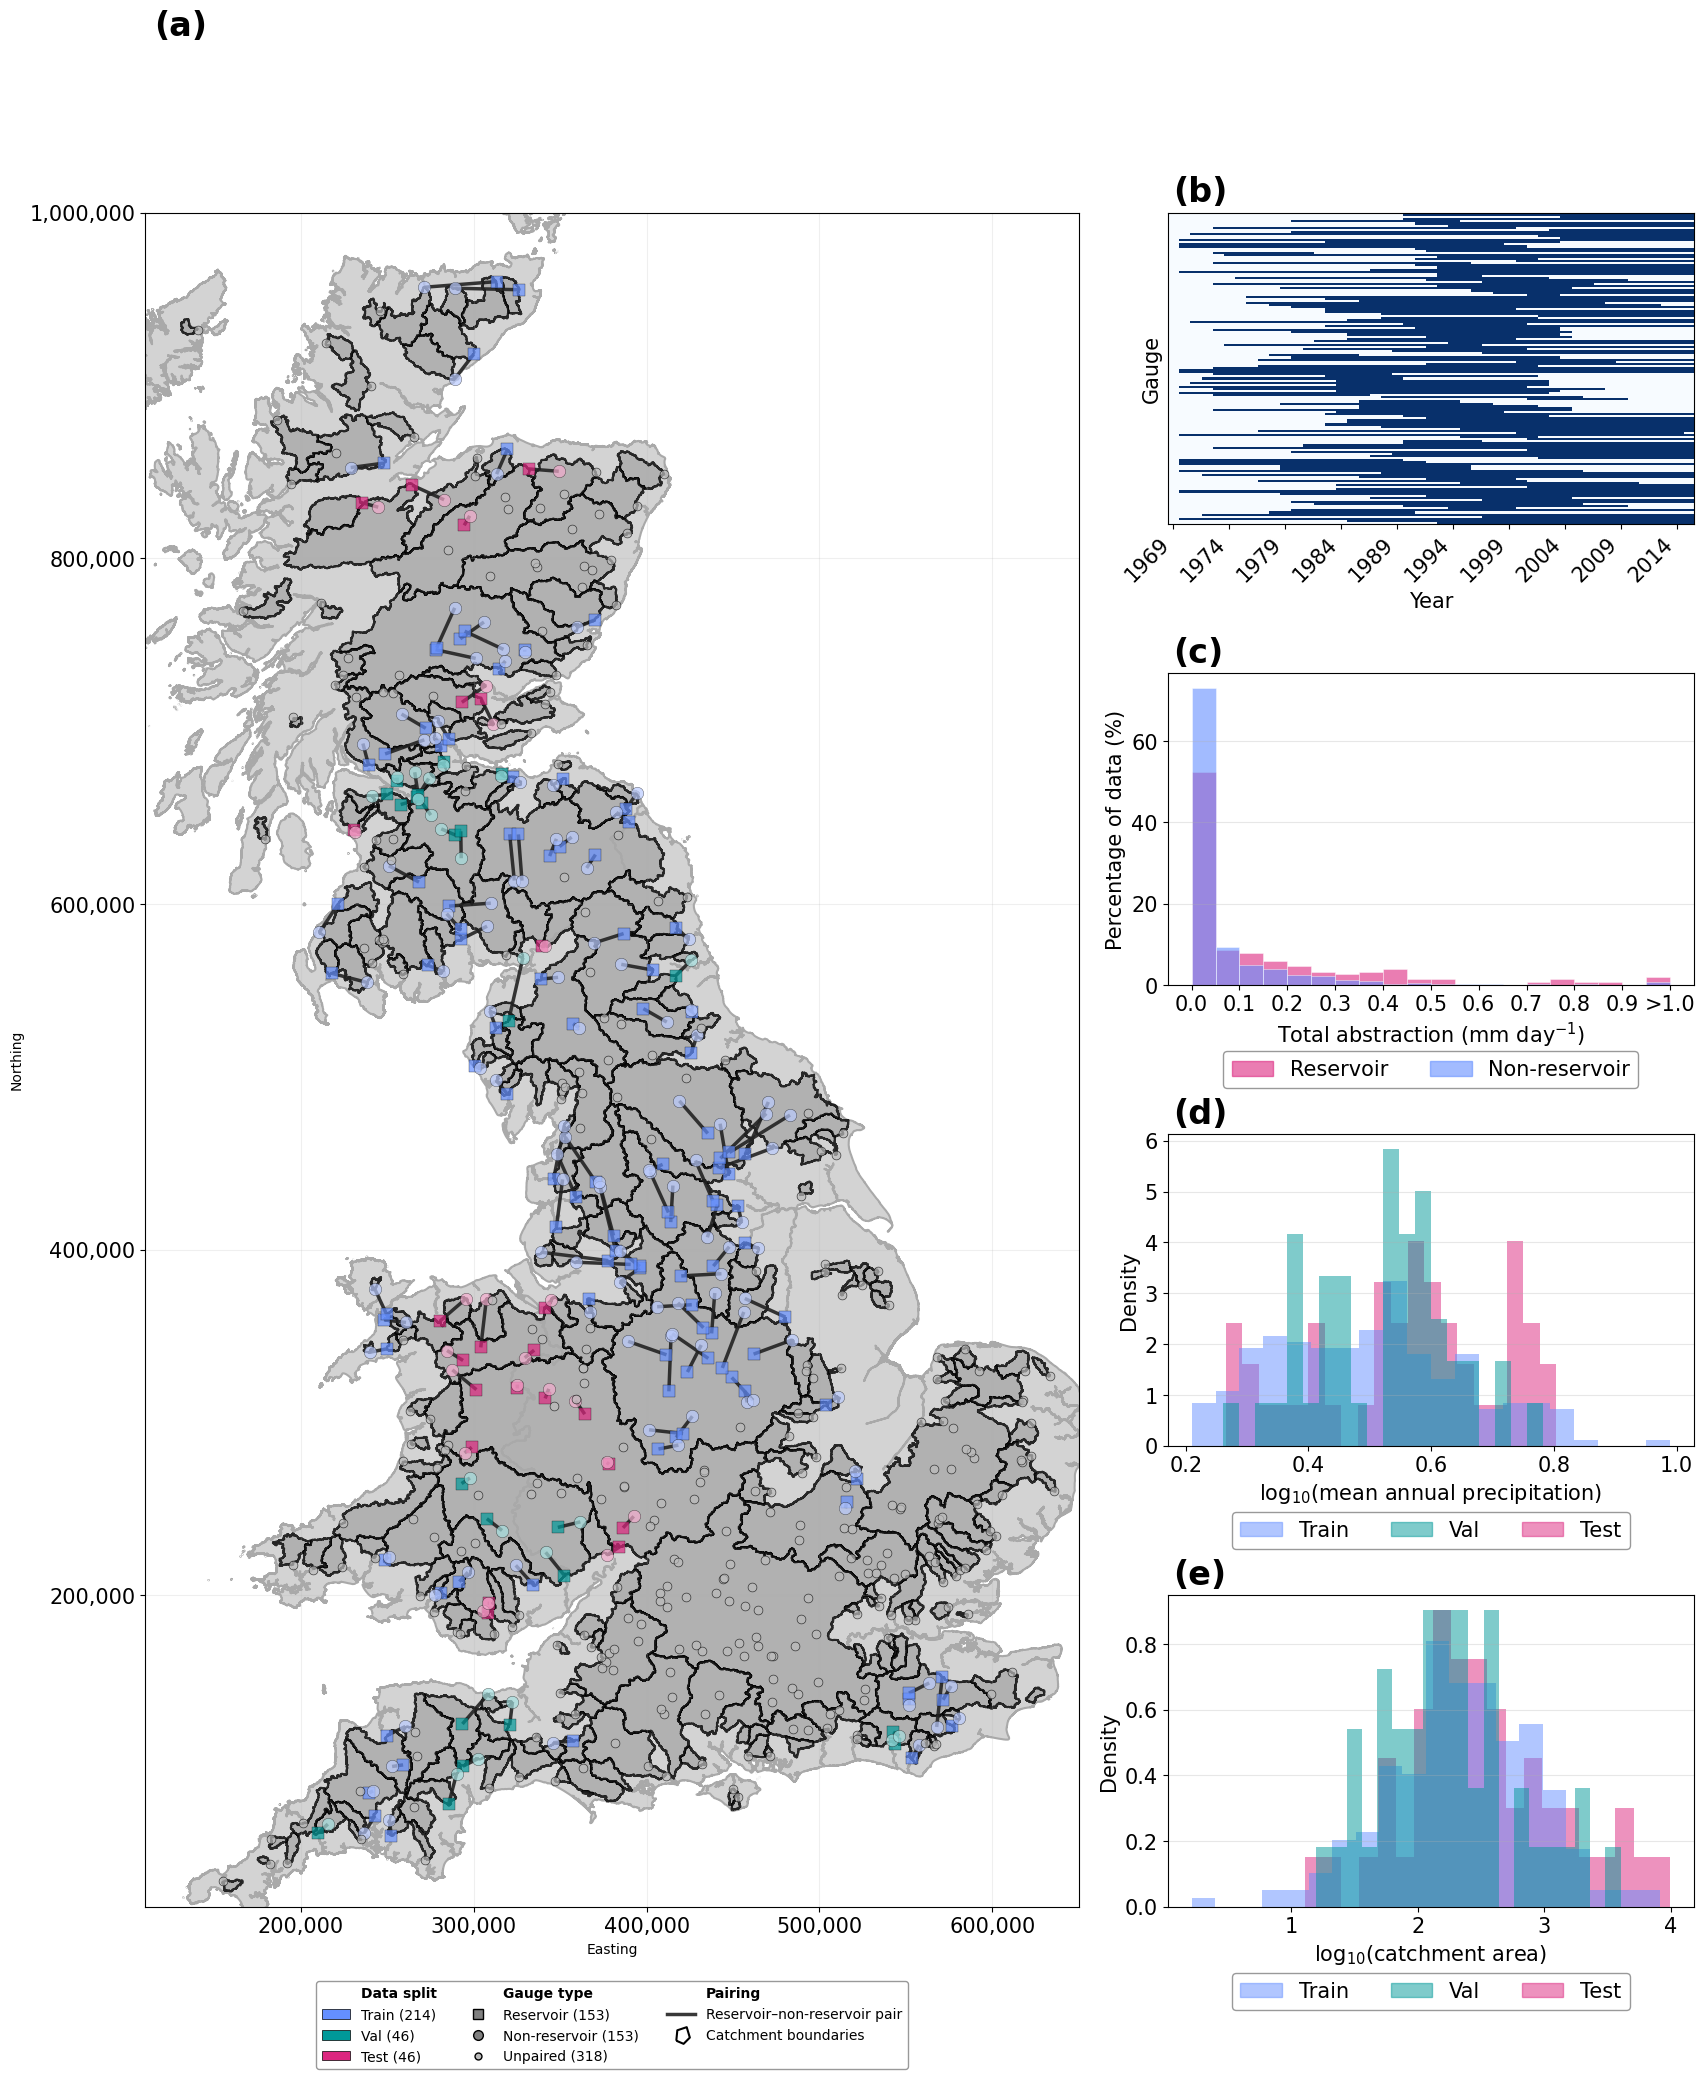

In [64]:
"""
Combined 5-panel figure: (a) Map | (b) Data availability | (c) Water abstraction
                          (d) Precipitation distribution  | (e) Area distribution
Layout: left 62% map, right 38% four stacked panels.
"""

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.path as mpath
import matplotlib.patches as mpatches
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np
import pandas as pd

# ── Palette (IBM colourblind-safe, works for protanopia, deuteranopia & tritanopia) ──
#   100 = light tint for non-reservoir markers
#   60  = main colour for reservoir markers, split histograms, legend patches

# Ultramarine (train), Teal (val), Magenta (test)
BLUE   = "#648FFF"   # IBM Ultramarine 40 — train / reservoir
TEAL   = "#009999"   # IBM Teal 50 — val / reservoir
RED    = "#DC267F"   # IBM Magenta 60 — test / reservoir
GREY   = "#BBBBBB"   # unpaired gauges

SPLIT_COL  = {"train": BLUE,    "val": TEAL,    "test": RED}
SPLIT_LITE = {"train": "#BACBFF", "val": "#A6E0E0", "test": "#F4ACCE"}  # light tints for non-reservoir
GAUGE_COL  = {"res": SPLIT_COL, "nonres": SPLIT_LITE}
GAUGE_MKR  = {"res": "s", "nonres": "o"}

LINE_KW  = dict(colors="#222222", alpha=0.9, linewidths=2.5, zorder=2)
HIST_KW  = dict(alpha=0.5, density=True, bins=20)
SPLITS   = ["train", "val", "test"]

FS = dict(label=15, tick=15, legend=15, panel=24)  # unified font sizes

# ── Figure / GridSpec ─────────────────────────────────────────────────────────
fig = plt.figure(figsize=(20, 22))
gs  = gridspec.GridSpec(4, 2, width_ratios=[0.64, 0.36], hspace=0.48, wspace=0.12)

ax_map, ax_avail, ax_water, ax_precip, ax_area = (
    fig.add_subplot(gs[:, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[2, 1]),
    fig.add_subplot(gs[3, 1]),
)

def panel_label(ax, letter):
    ax.text(0.01, 1.12, f"({letter})", transform=ax.transAxes,
            fontsize=FS["panel"], fontweight="bold", va="top", ha="left", zorder=6)

def right_legend(ax, handles, ncol=2):
    ax.legend(handles=handles, fontsize=FS["legend"],
              loc="upper center", bbox_to_anchor=(0.5, -0.18),
              ncol=ncol, frameon=True, edgecolor="grey")

# ══════════════════════════════════════════════════════════════════════════════
# (a) MAP
# ══════════════════════════════════════════════════════════════════════════════
res_split    = {s: res_gdf[res_gdf["split"] == s]    for s in SPLITS}
nonres_split = {s: nonres_gdf[nonres_gdf["split"] == s] for s in SPLITS}

uk_boundary_filtered.plot(ax=ax_map, color="lightgray", edgecolor="darkgray", linewidth=1.5)
catchments_gdf.plot(ax=ax_map, color="darkgray", edgecolor="black", linewidth=1.5, alpha=0.8)

for split in SPLITS:
    for kind, gdf in [("res", res_split[split]), ("nonres", nonres_split[split])]:
        ax_map.scatter(
            gdf.geometry.x, gdf.geometry.y,
            c=GAUGE_COL[kind][split], s=80, alpha=0.7,
            edgecolors="black", linewidths=0.3, marker=GAUGE_MKR[kind], zorder=3,
        )

# Reservoir–non-reservoir connecting lines
res_coords    = res_gdf.geometry.values
nonres_coords = nonres_gdf.geometry.values
res_splits    = res_gdf["split"].values
for split in SPLITS:
    m   = res_splits == split
    pts = lambda coords, mask: np.array([[g.x, g.y] for g in coords[mask]])
    segs = np.stack([pts(res_coords, m), pts(nonres_coords, m)], axis=1)
    ax_map.add_collection(LineCollection(segs, **LINE_KW))

unpaired_non_reservoir.plot(
    ax=ax_map, color=GREY, markersize=40, alpha=0.7, edgecolor="black", linewidth=0.5, zorder=3,
)

ax_map.set(xlabel="Easting", ylabel="Northing",
           xlim=(110_000, 650_000), ylim=(20_000, 1_000_000))
ax_map.set_aspect("equal")
ax_map.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax_map.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax_map.tick_params(labelsize=FS["tick"])
ax_map.grid(alpha=0.2)

# Map legend (3-column grid beneath axes)
n_res    = {s: len(res_split[s]) + len(nonres_split[s]) for s in SPLITS}
catchment_path = mpath.Path(
    [[-0.5,-0.5],[0.2,-0.8],[0.8,-0.2],[0.5,0.8],[-0.4,0.5],[-0.5,-0.5]]
)
blank = Patch(color="none", label="")

leg_handles = [
    Patch(color="none", label="Data split"),
    *[Patch(facecolor=SPLIT_COL[s], edgecolor="black", linewidth=0.5,
            label=f"{s.capitalize()} ({n_res[s]})") for s in SPLITS],
    Patch(color="none", label="Gauge type"),
    Line2D([0],[0], marker="s", color="none", markerfacecolor="grey",
           markeredgecolor="black", markersize=7, label=f"Reservoir ({len(res_gdf)})"),
    Line2D([0],[0], marker="o", color="none", markerfacecolor="grey",
           markeredgecolor="black", markersize=7, label=f"Non-reservoir ({len(nonres_gdf)})"),
    Line2D([0],[0], marker="o", color="none", markerfacecolor=GREY,
           markeredgecolor="black", markersize=5,
           label=f"Unpaired ({len(unpaired_non_reservoir)})"),
    Patch(color="none", label="Pairing"),
    Line2D([0],[0], color="#222222", linewidth=2.5, alpha=0.9,
           label="Reservoir–non-reservoir pair"),
    Line2D([0],[0], marker=catchment_path, color="none", markeredgecolor="black",
           markerfacecolor="none", markersize=12, markeredgewidth=1.5,
           label="Catchment boundaries"),
    blank,
]
leg = ax_map.legend(handles=leg_handles, loc="lower center", bbox_to_anchor=(0.5, -0.10),
                    ncol=3, frameon=True, edgecolor="grey", fontsize=10)
BOLD_LABELS = {"Data split", "Gauge type", "Pairing", ""}
for txt, hdl in zip(leg.get_texts(), leg.legend_handles):
    if txt.get_text() in BOLD_LABELS:
        txt.set_fontweight("bold")
        hdl.set_visible(False)


# ══════════════════════════════════════════════════════════════════════════════
# (b) DATA AVAILABILITY
# ══════════════════════════════════════════════════════════════════════════════
years     = np.arange(1969, 2016)
gauge_ids = gauge_dates_summary["gauge_id"].astype(str).tolist()

avail = pd.DataFrame(0, index=gauge_ids, columns=years)
for _, row in gauge_dates_summary[gauge_dates_summary["gauge_id"].isin(gauge_ids)].iterrows():
    gid = str(row["gauge_id"])
    avail.loc[gid, pd.to_datetime(row["first_date"]).year : pd.to_datetime(row["last_date"]).year] = 1

ax_avail.imshow(avail.values, aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="none")
ax_avail.set_yticks([])
year_ticks = np.arange(0, len(years), 5)
ax_avail.set_xticks(year_ticks)
ax_avail.set_xticklabels(years[year_ticks], rotation=45, ha="right", fontsize=FS["tick"])
ax_avail.set(xlabel="Year", ylabel="Gauge")
ax_avail.xaxis.label.set_size(FS["label"])
ax_avail.yaxis.label.set_size(FS["label"])


# ══════════════════════════════════════════════════════════════════════════════
# (c) WATER ABSTRACTION
# ══════════════════════════════════════════════════════════════════════════════
CLIP_MAX = 1.0
BIN_W    = 0.05
non_res_gauges = gdf_gauges[gdf_gauges["reservoir_contributing_area"] == 0]

abs_data = {
    "Reservoir":     reservoir_gauges[["surfacewater_abs","groundwater_abs"]].sum(axis=1).dropna(),
    "Non-reservoir": non_res_gauges[["surfacewater_abs","groundwater_abs"]].sum(axis=1).dropna(),
}
bin_edges = np.arange(pd.concat(abs_data.values()).min(), CLIP_MAX + BIN_W, BIN_W)

for (lbl, data), color in zip(abs_data.items(), [RED, BLUE]):
    counts, _ = np.histogram(data.clip(upper=CLIP_MAX), bins=bin_edges)
    ax_water.bar(bin_edges[:-1], counts / len(data) * 100, width=BIN_W, align="edge",
                 color=color, alpha=0.6, label=lbl, edgecolor="white", linewidth=0.5)

tick_idx = list(range(0, len(bin_edges) - 1, max(1, len(bin_edges) // 8))) + [len(bin_edges) - 1]
ax_water.set_xticks(bin_edges[tick_idx])
ax_water.set_xticklabels(
    [*(f"{v:.1f}" for v in bin_edges[tick_idx[:-1]]), f">{CLIP_MAX}"], fontsize=FS["tick"]
)
ax_water.set(xlabel=r"Total abstraction (mm day$^{-1}$)", ylabel="Percentage of data (%)")
ax_water.xaxis.label.set_size(FS["label"])
ax_water.yaxis.label.set_size(FS["label"])
ax_water.tick_params(labelsize=FS["tick"])
ax_water.grid(alpha=0.3, axis="y")
right_legend(ax_water, [Patch(color=c, alpha=0.6, label=l) for l, c in zip(abs_data, [RED, BLUE])])


# ══════════════════════════════════════════════════════════════════════════════
# (d) PRECIPITATION DISTRIBUTION  /  (e) AREA DISTRIBUTION
# ══════════════════════════════════════════════════════════════════════════════
split_handles = [Patch(color=SPLIT_COL[s], alpha=0.5, label=s.capitalize()) for s in SPLITS]

for ax, col, xlabel in [
    (ax_precip, "p_mean",  r"log$_{10}$(mean annual precipitation)"),
    (ax_area,   "area",    r"log$_{10}$(catchment area)"),
]:
    for split, grp in all_gdf_static.groupby("split"):
        ax.hist(np.log10(grp[col].dropna()), color=SPLIT_COL[split],
                label=split.capitalize(), **HIST_KW)
    ax.set(xlabel=xlabel, ylabel="Density")
    ax.xaxis.label.set_size(FS["label"])
    ax.yaxis.label.set_size(FS["label"])
    ax.tick_params(labelsize=FS["tick"])
    ax.grid(alpha=0.3, axis="y")
    right_legend(ax, split_handles, ncol=3)

ax_area.legend(handles=split_handles, fontsize=FS["legend"],
               loc="upper center", bbox_to_anchor=(0.5, -0.18),
               ncol=3, frameon=True, edgecolor="grey")


# ══════════════════════════════════════════════════════════════════════════════
# Panel labels & save
# ══════════════════════════════════════════════════════════════════════════════
for ax, letter in zip([ax_map, ax_avail, ax_water, ax_precip, ax_area], "abcde"):
    panel_label(ax, letter)

plt.savefig("combined_figure.png", dpi=300, bbox_inches="tight")
plt.show()